Datasets available under /kaggle/input:
 - /kaggle/input/datasets

Using DATASET_ROOT = /kaggle/input/datasets

Total image files found: 354
defect: 106 files
mask: 107 files
normal: 141 files
Defect image count by fabric_id:
fabric_id
0001    1
0002    1
0003    1
0004    1
0005    1
       ..
0105    1
0106    1
0107    1
0108    1
0109    1
Name: count, Length: 106, dtype: int64

Defect image count by defect_code (raw parse — verify against AITEX docs):
defect_code
02    38
03    31
01    12
04    10
00     7
06     6
05     1
08     1
Name: count, dtype: int64

Defect-free image count by fabric_id:
fabric_id
0018    8
0001    7
0003    7
0002    7
0004    7
0005    7
0007    7
0006    7
0009    7
0010    7
0011    7
0008    7
0012    7
0013    7
0015    7
0014    7
0016    7
0017    7
0019    7
0020    7
Name: count, dtype: int64

Matched masks: 103/106
['/kaggle/input/datasets/nexuswho/aitex-fabric-image-database/Defect_images/0044_019_04.png', '/kaggle/input/datasets/nexuswho/ait

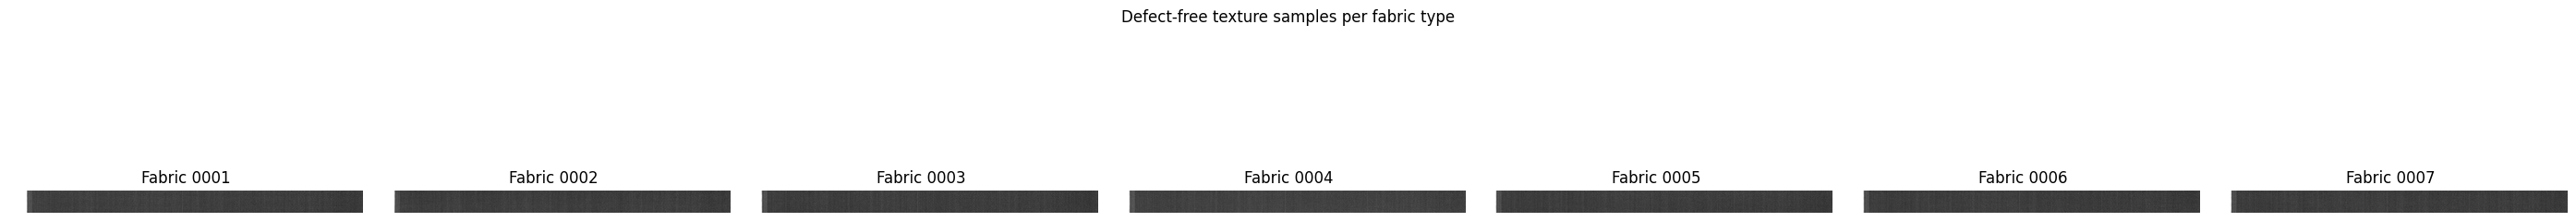

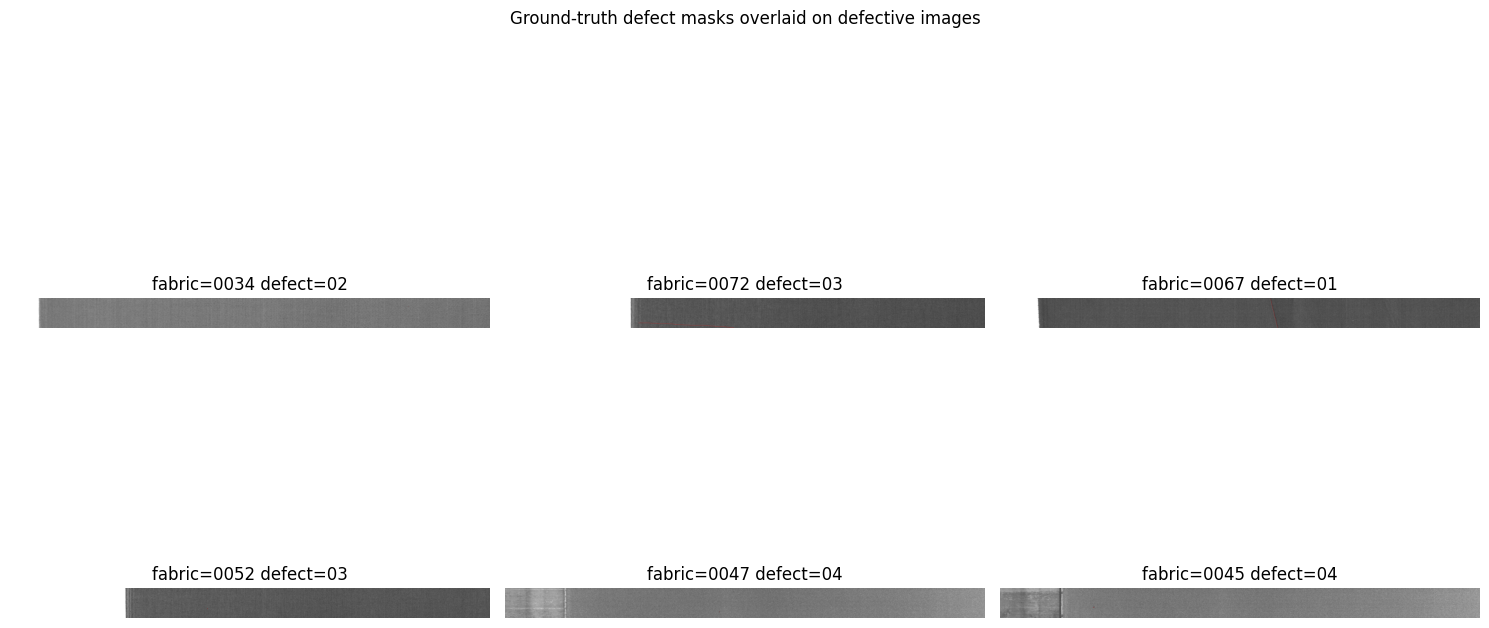

             count      mean       std       min       25%       50%  \
defect_code                                                            
00             7.0  0.062180  0.043774  0.015831  0.041294  0.043488   
01            12.0  1.921058  6.408113  0.002956  0.028086  0.054407   
02            38.0  0.041512  0.069663  0.000858  0.001717  0.002956   
03            30.0  0.702178  2.519702  0.000000  0.003266  0.018167   
04             9.0  0.050290  0.127269  0.001717  0.002766  0.004387   
05             1.0  0.027270       NaN  0.027270  0.027270  0.027270   
06             6.0  0.011206  0.012465  0.002384  0.002956  0.004148   

                  75%        max  
defect_code                       
00           0.080156   0.133038  
01           0.100231  22.268200  
02           0.060534   0.226498  
03           0.222993  13.658524  
04           0.012970   0.388908  
05           0.027270   0.027270  
06           0.018215   0.031090  


<Figure size 1000x500 with 0 Axes>

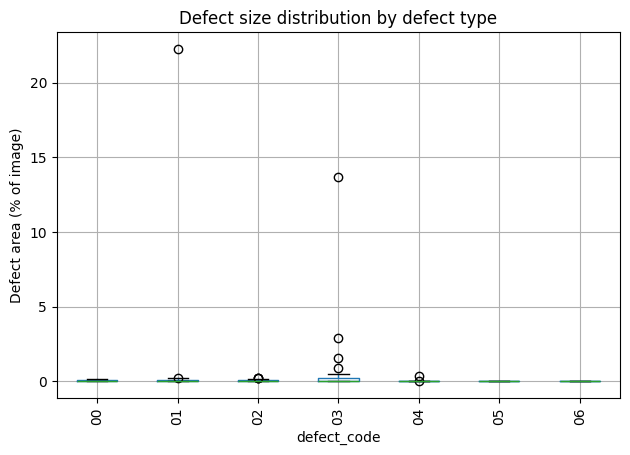

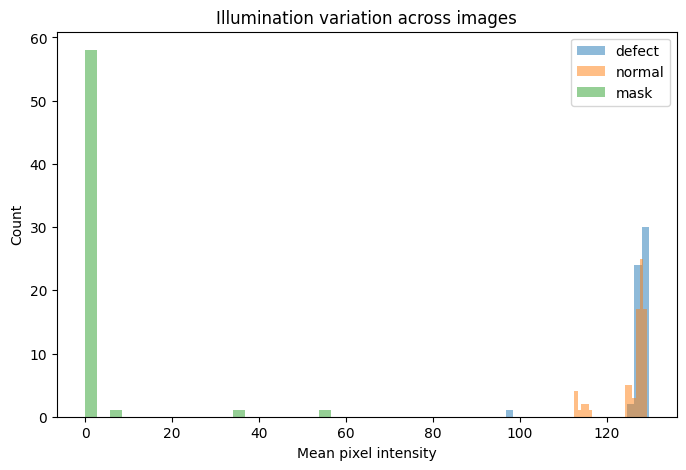

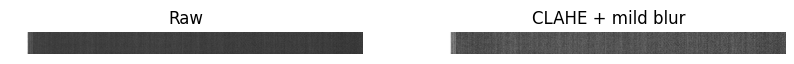

Total patches: 71120
Normal patches: 71075  |  Defective patches: 45
GLCM feature vector length: (16,) [0. 0. 0. 0. 1.]
LBP feature vector length: (28,)
Gabor feature vector length: (16,)
FFT feature vector length: (8,)
Extracting combined features for all patches...
Feature matrix shape: (71120, 68)
Fabric-specific normal-texture models built for: [np.str_('0001'), np.str_('0003'), np.str_('0004'), np.str_('0005'), np.str_('0006'), np.str_('0007'), np.str_('0008'), np.str_('0009'), np.str_('0010'), np.str_('0011'), np.str_('0012'), np.str_('0013'), np.str_('0014'), np.str_('0015'), np.str_('0016'), np.str_('0017'), np.str_('0018'), np.str_('0019'), np.str_('0020'), np.str_('0022'), np.str_('0026'), np.str_('0030'), np.str_('0032'), np.str_('0034'), np.str_('0035'), np.str_('0037'), np.str_('0039'), np.str_('0043'), np.str_('0045'), np.str_('0047'), np.str_('0049'), np.str_('0050'), np.str_('0052'), np.str_('0058'), np.str_('0060'), np.str_('0067'), np.str_('0069'), np.str_('0070'), np

<Figure size 600x500 with 0 Axes>

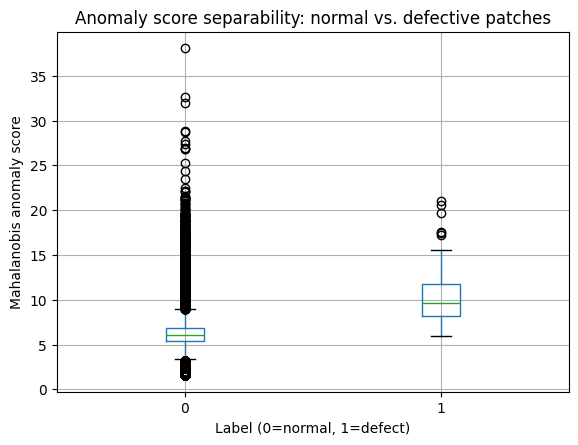

         count       mean       std       min       25%       50%        75%  \
label                                                                          
0      71075.0   6.177702  2.046632  1.558638  5.397527  6.073932   6.832950   
1         45.0  10.888635  3.850635  5.928702  8.223255  9.676873  11.774291   

             max  
label             
0      38.083706  
1      21.008803  
Approx. probability a random defect patch outscores a random normal patch: 0.924


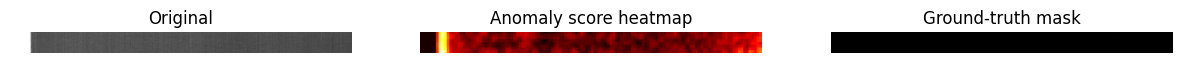

{
  "total_images_found": 354,
  "normal_images": 141,
  "defect_images": 106,
  "masks_matched": 103,
  "fabric_types_seen": [
    "0001",
    "0002",
    "0003",
    "0004",
    "0005",
    "0006",
    "0007",
    "0008",
    "0009",
    "0010",
    "0011",
    "0012",
    "0013",
    "0014",
    "0015",
    "0016",
    "0017",
    "0018",
    "0019",
    "0020"
  ],
  "defect_types_seen": [
    "00",
    "01",
    "02",
    "03",
    "04",
    "05",
    "06",
    "08"
  ],
  "total_patches_extracted": 71120,
  "normal_patches": 71075,
  "defect_patches": 45,
  "feature_vector_length": 68,
  "fabric_models_built": [
    "0001",
    "0003",
    "0004",
    "0005",
    "0006",
    "0007",
    "0008",
    "0009",
    "0010",
    "0011",
    "0012",
    "0013",
    "0014",
    "0015",
    "0016",
    "0017",
    "0018",
    "0019",
    "0020",
    "0022",
    "0026",
    "0030",
    "0032",
    "0034",
    "0035",
    "0037",
    "0039",
    "0043",
    "0045",
    "0047",
    "0049",
  

In [1]:

import os
import re
import glob
import json
import math
import random
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.filters import gabor_kernel
from scipy import ndimage as ndi
from scipy.spatial.distance import mahalanobis

random.seed(42)
np.random.seed(42)

INPUT_ROOT = "/kaggle/input"
OUTPUT_ROOT = "/kaggle/working"
os.makedirs(OUTPUT_ROOT, exist_ok=True)

# Auto-discover the AITEX dataset folder under /kaggle/input
candidate_roots = [d for d in glob.glob(os.path.join(INPUT_ROOT, "*")) if os.path.isdir(d)]
print("Datasets available under /kaggle/input:")
for c in candidate_roots:
    print(" -", c)

# >>> SET THIS after inspecting the printed list above <<<
DATASET_ROOT = candidate_roots[0] if candidate_roots else None
print("\nUsing DATASET_ROOT =", DATASET_ROOT)

# Walk the tree and bucket files by extension / folder name keywords
all_images = glob.glob(os.path.join(DATASET_ROOT, "**", "*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))]
print(f"\nTotal image files found: {len(all_images)}")

def classify_path(p):
    lp = p.lower()
    if "mask" in lp:
        return "mask"
    if "nodefect" in lp or "no_defect" in lp or "good" in lp:
        return "normal"
    if "defect" in lp:
        return "defect"
    return "unknown"

buckets = defaultdict(list)
for f in all_images:
    buckets[classify_path(f)].append(f)

for k, v in buckets.items():
    print(f"{k}: {len(v)} files")

# Save raw file lists to working dir for later cells / reproducibility
with open(os.path.join(OUTPUT_ROOT, "file_buckets.json"), "w") as fh:
    json.dump({k: sorted(v) for k, v in buckets.items()}, fh, indent=2)



def parse_defect_filename(fname):
    """Best-effort parser for AITEX defective-image filenames."""
    stem = os.path.splitext(os.path.basename(fname))[0]
    parts = re.split(r"[_\-]", stem)
    fabric_id = parts[0] if len(parts) > 0 else "unknown"
    defect_code = parts[-1] if len(parts) > 2 else "unknown"
    return fabric_id, defect_code

defect_records = []
for f in buckets["defect"]:
    fabric_id, defect_code = parse_defect_filename(f)
    defect_records.append({"path": f, "fabric_id": fabric_id, "defect_code": defect_code})

df_defects = pd.DataFrame(defect_records)
print("Defect image count by fabric_id:")
print(df_defects["fabric_id"].value_counts())
print("\nDefect image count by defect_code (raw parse — verify against AITEX docs):")
print(df_defects["defect_code"].value_counts())

normal_records = []
for f in buckets["normal"]:
    fabric_id, _ = parse_defect_filename(f)
    normal_records.append({"path": f, "fabric_id": fabric_id})
df_normal = pd.DataFrame(normal_records)
print("\nDefect-free image count by fabric_id:")
print(df_normal["fabric_id"].value_counts())

# Match defective images to masks by stem similarity
mask_lookup = {os.path.splitext(os.path.basename(m))[0]: m for m in buckets["mask"]}

def find_mask_for(defect_path):
    stem = os.path.splitext(os.path.basename(defect_path))[0]
    if stem in mask_lookup:
        return mask_lookup[stem]
    # try stripping/adding common suffixes
    for suffix in ["_mask", "-mask", "_gt"]:
        alt = stem + suffix
        if alt in mask_lookup:
            return mask_lookup[alt]
    base = stem.replace("_mask", "").replace("-mask", "")
    if base in mask_lookup:
        return mask_lookup[base]
    return None

df_defects["mask_path"] = df_defects["path"].apply(find_mask_for)
n_matched = df_defects["mask_path"].notna().sum()
print(f"\nMatched masks: {n_matched}/{len(df_defects)}")
if n_matched < len(df_defects):
    print("WARNING: some defective images have no matched mask — inspect naming convention manually:")
    print(df_defects[df_defects["mask_path"].isna()]["path"].head(10).tolist())

df_defects.to_csv(os.path.join(OUTPUT_ROOT, "defect_index.csv"), index=False)
df_normal.to_csv(os.path.join(OUTPUT_ROOT, "normal_index.csv"), index=False)



def img_props(path):
    im = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if im is None:
        return None
    shape = im.shape
    return {"path": path, "h": shape[0], "w": shape[1],
            "channels": shape[2] if len(shape) == 3 else 1, "dtype": str(im.dtype)}

sample_paths = random.sample(all_images, min(30, len(all_images)))
props = [p for p in (img_props(f) for f in sample_paths) if p is not None]
df_props = pd.DataFrame(props)
print(df_props[["h", "w", "channels", "dtype"]].describe(include="all"))


def load_gray(path):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    return im

fabric_ids = df_normal["fabric_id"].unique()[:7]
fig, axes = plt.subplots(1, len(fabric_ids), figsize=(4 * len(fabric_ids), 4))
if len(fabric_ids) == 1:
    axes = [axes]
for ax, fid in zip(axes, fabric_ids):
    sample = df_normal[df_normal["fabric_id"] == fid]["path"].iloc[0]
    im = load_gray(sample)
    ax.imshow(im, cmap="gray")
    ax.set_title(f"Fabric {fid}")
    ax.axis("off")
plt.suptitle("Defect-free texture samples per fabric type")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "eda_fabric_types.png"), dpi=120)
plt.show()



def overlay_mask(img_path, mask_path, alpha=0.4):
    im = load_gray(img_path)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (im.shape[1], im.shape[0]))
    im_rgb = cv2.cvtColor(im, cv2.COLOR_GRAY2RGB)
    overlay = im_rgb.copy()
    overlay[mask > 0] = [255, 0, 0]
    blended = cv2.addWeighted(overlay, alpha, im_rgb, 1 - alpha, 0)
    return blended, mask

matched = df_defects.dropna(subset=["mask_path"])
sample_defects = matched.sample(min(6, len(matched)), random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (_, row) in zip(axes.flat, sample_defects.iterrows()):
    blended, mask = overlay_mask(row["path"], row["mask_path"])
    ax.imshow(blended)
    ax.set_title(f"fabric={row['fabric_id']} defect={row['defect_code']}")
    ax.axis("off")
plt.suptitle("Ground-truth defect masks overlaid on defective images")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "eda_mask_overlays.png"), dpi=120)
plt.show()


size_records = []
for _, row in matched.iterrows():
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue
    area_px = int((mask > 0).sum())
    pct = 100.0 * area_px / mask.size
    size_records.append({"defect_code": row["defect_code"], "area_px": area_px, "area_pct": pct})

df_sizes = pd.DataFrame(size_records)
print(df_sizes.groupby("defect_code")["area_pct"].describe())

plt.figure(figsize=(10, 5))
df_sizes.boxplot(column="area_pct", by="defect_code", rot=90)
plt.ylabel("Defect area (% of image)")
plt.title("Defect size distribution by defect type")
plt.suptitle("")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "eda_defect_sizes.png"), dpi=120)
plt.show()


brightness_records = []
for f in random.sample(all_images, min(200, len(all_images))):
    im = load_gray(f)
    if im is None:
        continue
    brightness_records.append({"path": f, "mean": im.mean(), "std": im.std(),
                                "bucket": classify_path(f)})
df_bright = pd.DataFrame(brightness_records)
plt.figure(figsize=(8, 5))
for b in df_bright["bucket"].unique():
    plt.hist(df_bright[df_bright["bucket"] == b]["mean"], bins=20, alpha=0.5, label=b)
plt.xlabel("Mean pixel intensity")
plt.ylabel("Count")
plt.legend()
plt.title("Illumination variation across images")
plt.savefig(os.path.join(OUTPUT_ROOT, "eda_illumination.png"), dpi=120)
plt.show()


clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_image(path, denoise=True):
    im = load_gray(path)
    if im is None:
        return None
    im = clahe.apply(im)
    if denoise:
        im = cv2.GaussianBlur(im, (3, 3), 0)
    return im

sample = df_normal["path"].iloc[0]
raw = load_gray(sample)
proc = preprocess_image(sample)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(raw, cmap="gray"); ax[0].set_title("Raw"); ax[0].axis("off")
ax[1].imshow(proc, cmap="gray"); ax[1].set_title("CLAHE + mild blur"); ax[1].axis("off")
plt.savefig(os.path.join(OUTPUT_ROOT, "preprocess_before_after.png"), dpi=120)
plt.show()

PATCH_SIZE = 64      # tune based on defect-size EDA (Cell 5) — smallest defects should still
STRIDE = 32           # roughly fill a patch; halve stride vs patch size for overlap
DEFECT_OVERLAP_THRESH = 0.10   # patch labeled "defect" if >=10% of its pixels are masked

def extract_patches(img, mask=None, patch_size=PATCH_SIZE, stride=STRIDE):
    """Yields (patch, label, (y, x)) — label is 1 if mask overlap exceeds threshold, else 0.
    If mask is None, all labels are 0 (used for defect-free images)."""
    h, w = img.shape
    results = []
    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            patch = img[y:y + patch_size, x:x + patch_size]
            label = 0
            if mask is not None:
                m_patch = mask[y:y + patch_size, x:x + patch_size]
                overlap = (m_patch > 0).mean()
                label = int(overlap >= DEFECT_OVERLAP_THRESH)
            results.append((patch, label, (y, x)))
    return results

# Build a manageable patch dataset: cap number of source images per class to keep Week-2 runtime sane
MAX_NORMAL_IMAGES = 40
MAX_DEFECT_IMAGES = 40

normal_sample = df_normal.sample(min(MAX_NORMAL_IMAGES, len(df_normal)), random_state=42)
defect_sample = matched.sample(min(MAX_DEFECT_IMAGES, len(matched)), random_state=42)

patch_records = []  # (patch_array will be stored separately to keep the index lightweight)
patch_arrays = []
patch_labels = []
patch_fabric = []
patch_source = []

for _, row in normal_sample.iterrows():
    im = preprocess_image(row["path"])
    if im is None:
        continue
    for patch, label, (y, x) in extract_patches(im, mask=None):
        patch_arrays.append(patch)
        patch_labels.append(0)
        patch_fabric.append(row["fabric_id"])
        patch_source.append(row["path"])

for _, row in defect_sample.iterrows():
    im = preprocess_image(row["path"])
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    if im is None or mask is None:
        continue
    if mask.shape != im.shape:
        mask = cv2.resize(mask, (im.shape[1], im.shape[0]))
    for patch, label, (y, x) in extract_patches(im, mask=mask):
        patch_arrays.append(patch)
        patch_labels.append(label)
        patch_fabric.append(row["fabric_id"])
        patch_source.append(row["path"])

patch_labels = np.array(patch_labels)
print(f"Total patches: {len(patch_arrays)}")
print(f"Normal patches: {(patch_labels == 0).sum()}  |  Defective patches: {(patch_labels == 1).sum()}")

np.save(os.path.join(OUTPUT_ROOT, "patch_labels.npy"), patch_labels)


# %% [CELL 9] — Texture descriptors: GLCM
GLCM_DISTANCES = [1, 3]
GLCM_ANGLES = [0, np.pi/4, np.pi/2, 3*np.pi/4]
GLCM_PROPS = ["contrast", "correlation", "energy", "homogeneity"]

def glcm_features(patch, levels=32):
    """Quantize to `levels` gray levels to keep GLCM computation cheap, then extract stats."""
    q = (patch.astype(np.float32) / 256.0 * levels).astype(np.uint8)
    q = np.clip(q, 0, levels - 1)
    glcm = graycomatrix(q, distances=GLCM_DISTANCES, angles=GLCM_ANGLES,
                         levels=levels, symmetric=True, normed=True)
    feats = []
    for prop in GLCM_PROPS:
        vals = graycoprops(glcm, prop)  # shape (n_distances, n_angles)
        feats.extend(vals.mean(axis=1))       # mean over angles, per distance -> rotation-robust
        feats.extend(vals.std(axis=1))        # std over angles -> anisotropy indicator
    return np.array(feats)

# quick unit test
test_feat = glcm_features(patch_arrays[0])
print("GLCM feature vector length:", test_feat.shape, test_feat[:5])



LBP_CONFIGS = [(8, 1), (16, 2)]  # (P, R) pairs

def lbp_features(patch):
    feats = []
    for P, R in LBP_CONFIGS:
        lbp = local_binary_pattern(patch, P, R, method="uniform")
        n_bins = P + 2
        hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        feats.extend(hist)
    return np.array(feats)

test_feat = lbp_features(patch_arrays[0])
print("LBP feature vector length:", test_feat.shape)


GABOR_FREQS = [0.1, 0.3]
GABOR_THETAS = [0, np.pi/4, np.pi/2, 3*np.pi/4]

_gabor_kernels = [gabor_kernel(freq, theta=theta).real
                   for freq in GABOR_FREQS for theta in GABOR_THETAS]

def gabor_features(patch):
    patch_f = patch.astype(np.float32) / 255.0
    feats = []
    for kernel in _gabor_kernels:
        filtered = ndi.convolve(patch_f, kernel, mode="wrap")
        feats.append(filtered.mean())
        feats.append(filtered.var())
    return np.array(feats)

test_feat = gabor_features(patch_arrays[0])
print("Gabor feature vector length:", test_feat.shape)



def fft_features(patch):
    f = np.fft.fftshift(np.fft.fft2(patch.astype(np.float32)))
    mag = np.log1p(np.abs(f))
    h, w = mag.shape
    cy, cx = h // 2, w // 2
    # radial energy in a few concentric bands (crude but effective + cheap)
    yy, xx = np.mgrid[0:h, 0:w]
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    bands = [(0, 4), (4, 10), (10, 20), (20, max(h, w))]
    feats = []
    for lo, hi in bands:
        band_mask = (r >= lo) & (r < hi)
        feats.append(mag[band_mask].mean() if band_mask.any() else 0.0)
        feats.append(mag[band_mask].std() if band_mask.any() else 0.0)
    return np.array(feats)

test_feat = fft_features(patch_arrays[0])
print("FFT feature vector length:", test_feat.shape)

def combined_features(patch):
    return np.concatenate([
        glcm_features(patch),
        lbp_features(patch),
        gabor_features(patch),
        fft_features(patch),
    ])

print("Extracting combined features for all patches...")
feature_matrix = np.array([combined_features(p) for p in patch_arrays])
print("Feature matrix shape:", feature_matrix.shape)

np.save(os.path.join(OUTPUT_ROOT, "feature_matrix.npy"), feature_matrix)



patch_fabric = np.array(patch_fabric)
fabric_models = {}  # fabric_id -> (mean_vec, inv_cov)

for fid in np.unique(patch_fabric):
    normal_idx = (patch_fabric == fid) & (patch_labels == 0)
    X_normal = feature_matrix[normal_idx]
    if len(X_normal) < feature_matrix.shape[1] + 5:
        print(f"Fabric {fid}: not enough normal patches ({len(X_normal)}) for stable covariance — skipping")
        continue
    mean_vec = X_normal.mean(axis=0)
    cov = np.cov(X_normal, rowvar=False)
    cov += np.eye(cov.shape[0]) * 1e-6  # regularize for invertibility
    inv_cov = np.linalg.pinv(cov)
    fabric_models[fid] = (mean_vec, inv_cov)

print("Fabric-specific normal-texture models built for:", list(fabric_models.keys()))

def anomaly_score(feat_vec, fabric_id):
    if fabric_id not in fabric_models:
        return np.nan
    mean_vec, inv_cov = fabric_models[fabric_id]
    return mahalanobis(feat_vec, mean_vec, inv_cov)

scores = np.array([anomaly_score(feature_matrix[i], patch_fabric[i]) for i in range(len(patch_arrays))])
np.save(os.path.join(OUTPUT_ROOT, "anomaly_scores.npy"), scores)



valid = ~np.isnan(scores)
df_scores = pd.DataFrame({"score": scores[valid], "label": patch_labels[valid]})

plt.figure(figsize=(6, 5))
df_scores.boxplot(column="score", by="label")
plt.xlabel("Label (0=normal, 1=defect)")
plt.ylabel("Mahalanobis anomaly score")
plt.title("Anomaly score separability: normal vs. defective patches")
plt.suptitle("")
plt.savefig(os.path.join(OUTPUT_ROOT, "score_separability.png"), dpi=120)
plt.show()

print(df_scores.groupby("label")["score"].describe())

# Quick separability metric: AUC-like rank statistic without extra deps
from itertools import product
normal_scores = df_scores[df_scores.label == 0]["score"].values
defect_scores = df_scores[df_scores.label == 1]["score"].values
if len(normal_scores) and len(defect_scores):
    wins = np.mean([d > n for n, d in
                     zip(np.random.choice(normal_scores, 2000), np.random.choice(defect_scores, 2000))])
    print(f"Approx. probability a random defect patch outscores a random normal patch: {wins:.3f}")

def compute_iou(pred_mask, gt_mask):
    pred_bin = pred_mask > 0
    gt_bin = gt_mask > 0
    intersection = np.logical_and(pred_bin, gt_bin).sum()
    union = np.logical_or(pred_bin, gt_bin).sum()
    return intersection / union if union > 0 else np.nan

def compute_precision_recall(pred_mask, gt_mask):
    pred_bin = pred_mask > 0
    gt_bin = gt_mask > 0
    tp = np.logical_and(pred_bin, gt_bin).sum()
    fp = np.logical_and(pred_bin, ~gt_bin).sum()
    fn = np.logical_and(~pred_bin, gt_bin).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return precision, recall

def build_score_heatmap(img_path, fabric_id, patch_size=PATCH_SIZE, stride=STRIDE):
    """Slide over a full image, score each patch, and paint a heatmap for visualization."""
    im = preprocess_image(img_path)
    h, w = im.shape
    heat = np.zeros((h, w), dtype=np.float32)
    count = np.zeros((h, w), dtype=np.float32)
    for patch, _, (y, x) in extract_patches(im, mask=None, patch_size=patch_size, stride=stride):
        feat = combined_features(patch)
        s = anomaly_score(feat, fabric_id)
        heat[y:y+patch_size, x:x+patch_size] += (0 if np.isnan(s) else s)
        count[y:y+patch_size, x:x+patch_size] += 1
    count[count == 0] = 1
    return heat / count

# Demo on one defective image with a known fabric model
demo_row = None
for _, row in defect_sample.iterrows():
    if row["fabric_id"] in fabric_models:
        demo_row = row
        break

if demo_row is not None:
    heat = build_score_heatmap(demo_row["path"], demo_row["fabric_id"])
    gt_mask = cv2.imread(demo_row["mask_path"], cv2.IMREAD_GRAYSCALE)
    gt_mask = cv2.resize(gt_mask, (heat.shape[1], heat.shape[0]))

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(load_gray(demo_row["path"]), cmap="gray"); ax[0].set_title("Original"); ax[0].axis("off")
    ax[1].imshow(heat, cmap="hot"); ax[1].set_title("Anomaly score heatmap"); ax[1].axis("off")
    ax[2].imshow(gt_mask, cmap="gray"); ax[2].set_title("Ground-truth mask"); ax[2].axis("off")
    plt.savefig(os.path.join(OUTPUT_ROOT, "heatmap_demo.png"), dpi=120)
    plt.show()
else:
    print("No defective sample with a fitted fabric model was found for the heatmap demo — "
          "increase MAX_DEFECT_IMAGES / MAX_NORMAL_IMAGES in Cell 8 and re-run.")


summary = {
    "total_images_found": len(all_images),
    "normal_images": len(df_normal),
    "defect_images": len(df_defects),
    "masks_matched": int(n_matched),
    "fabric_types_seen": sorted(df_normal["fabric_id"].unique().tolist()),
    "defect_types_seen": sorted(df_defects["defect_code"].unique().tolist()),
    "total_patches_extracted": len(patch_arrays),
    "normal_patches": int((patch_labels == 0).sum()),
    "defect_patches": int((patch_labels == 1).sum()),
    "feature_vector_length": int(feature_matrix.shape[1]),
    "fabric_models_built": list(fabric_models.keys()),
}
with open(os.path.join(OUTPUT_ROOT, "week2_checkpoint_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2)

print(json.dumps(summary, indent=2))

AFID root: /kaggle/input/datasets/nexuswho/aitex-fabric-image-database
NODefect_images : /kaggle/input/datasets/nexuswho/aitex-fabric-image-database/NODefect_images
Defect_images   : /kaggle/input/datasets/nexuswho/aitex-fabric-image-database/Defect_images
Mask_images     : /kaggle/input/datasets/nexuswho/aitex-fabric-image-database/Mask_images
Defect-free images : 141
Defective images   : 106
Mask images        : 107
                                                path        label fabric_type  \
0  /kaggle/input/datasets/nexuswho/aitex-fabric-i...  defect_free        0001   
1  /kaggle/input/datasets/nexuswho/aitex-fabric-i...  defect_free        0002   
2  /kaggle/input/datasets/nexuswho/aitex-fabric-i...  defect_free        0003   
3  /kaggle/input/datasets/nexuswho/aitex-fabric-i...  defect_free        0004   
4  /kaggle/input/datasets/nexuswho/aitex-fabric-i...  defect_free        0005   

  defect_type mask_path  
0        none       NaN  
1        none       NaN  
2        none

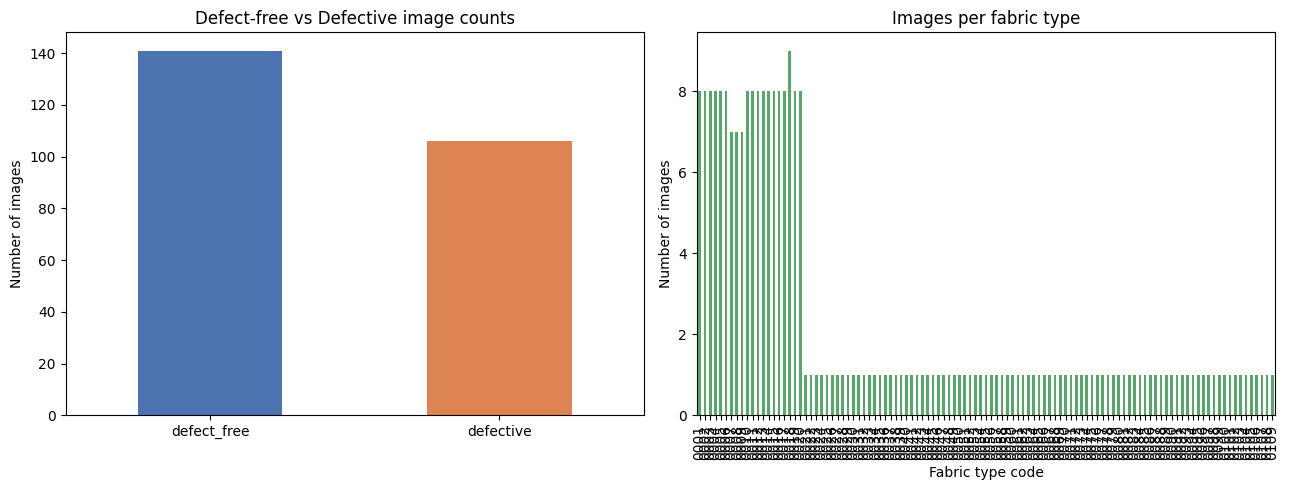

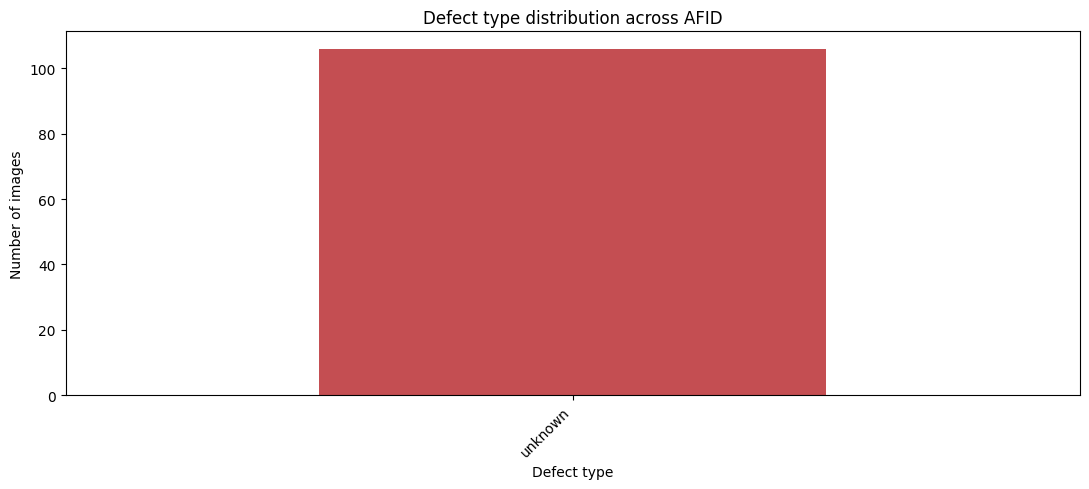

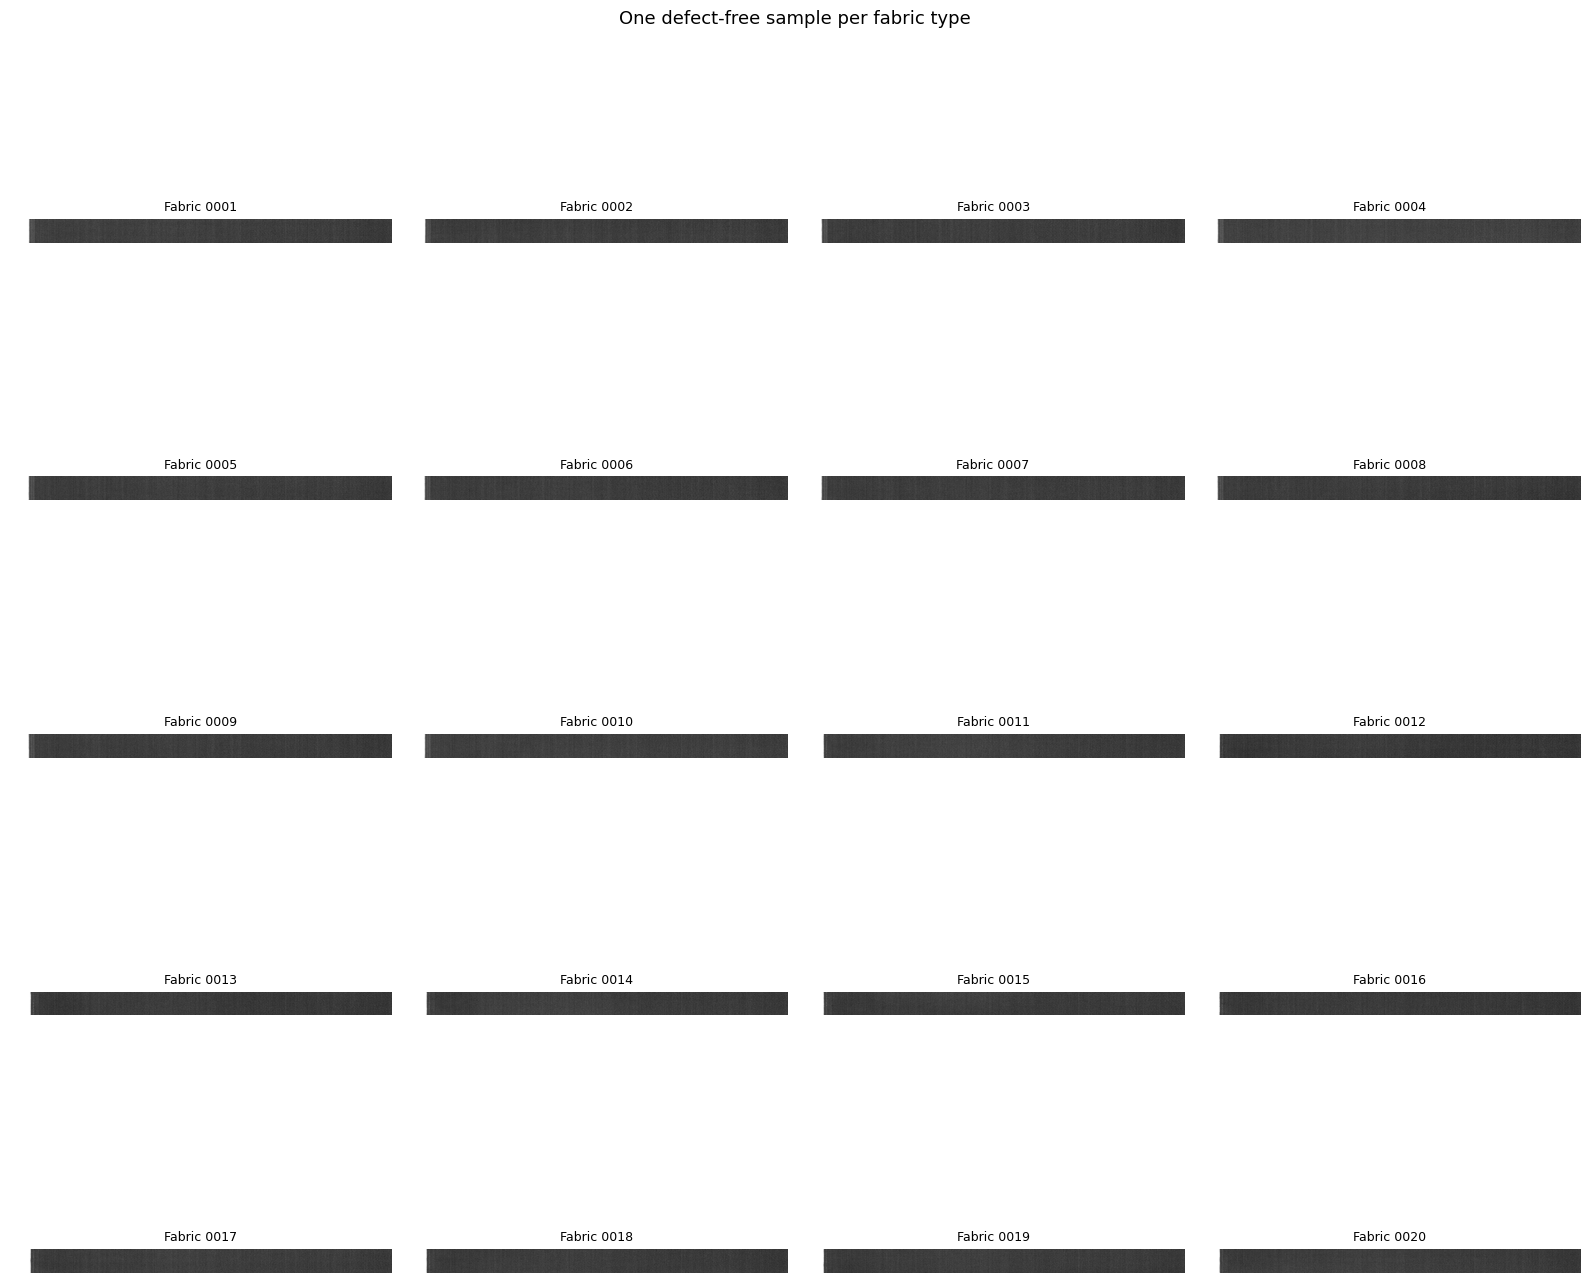

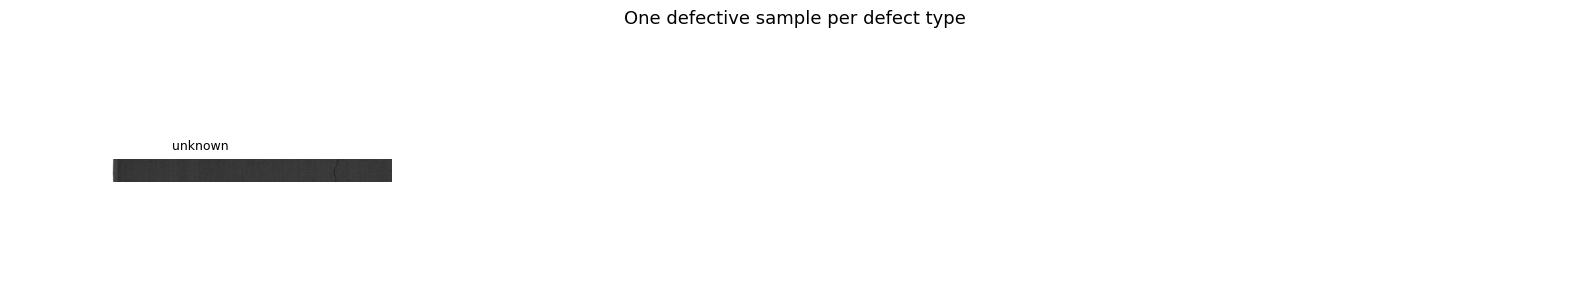

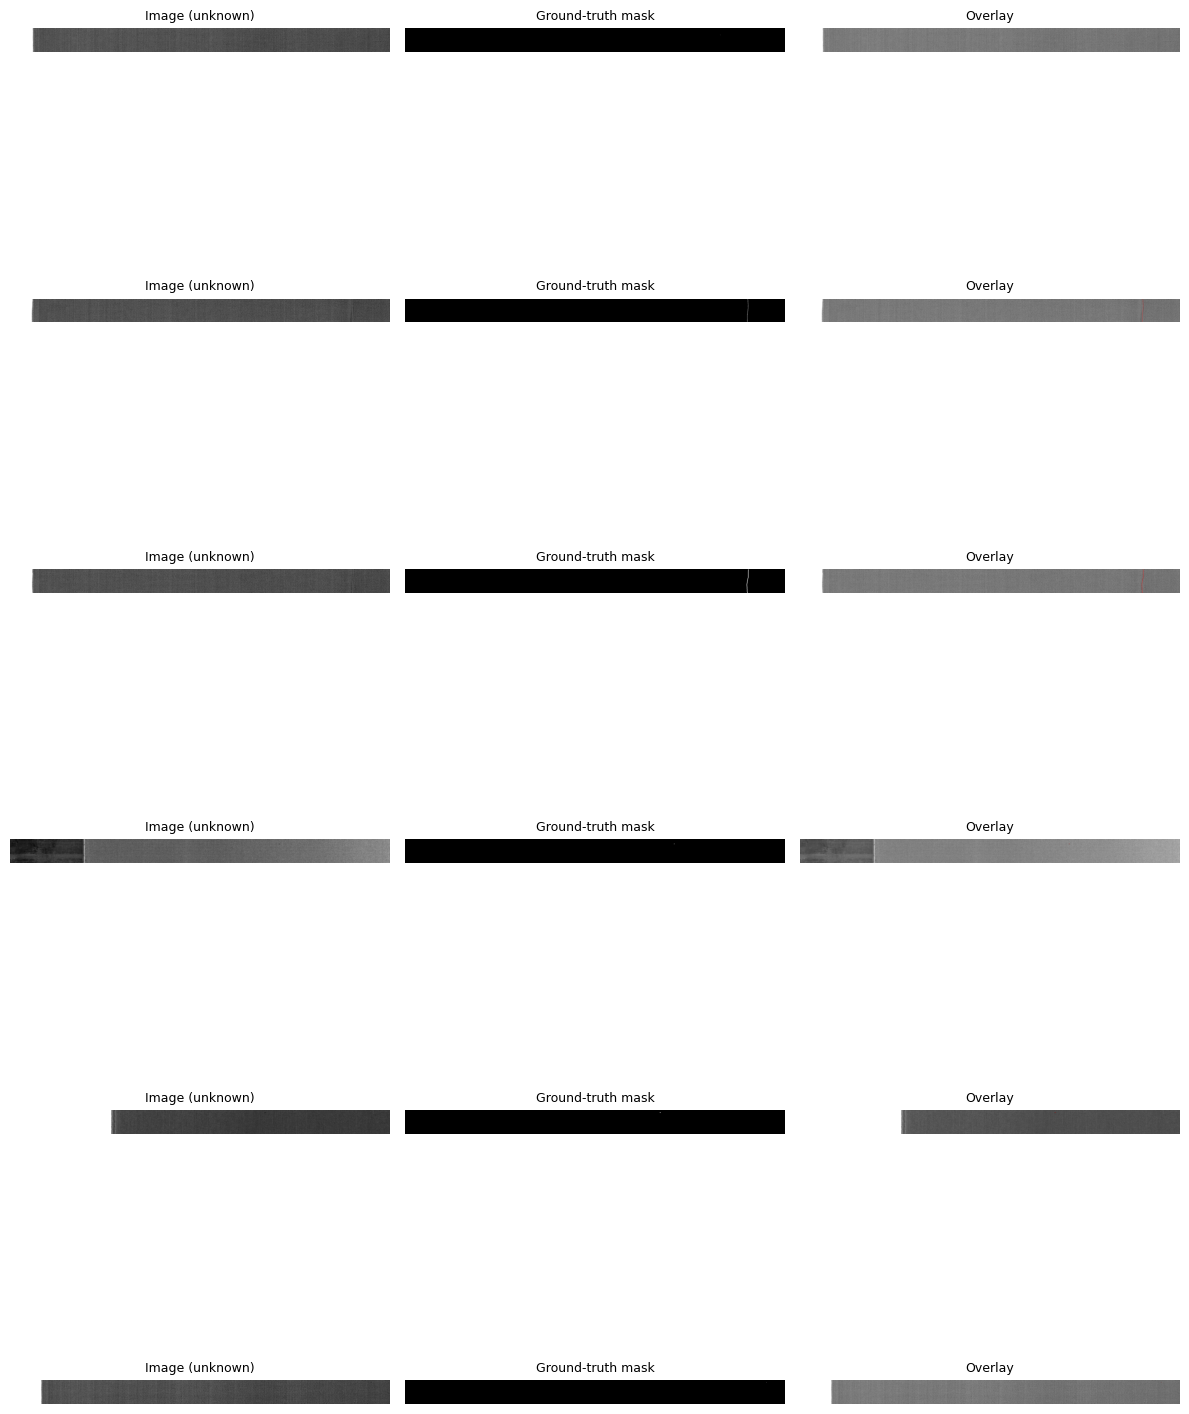


--- Image dimensions (sampled) ---
       height        width
count   247.0   247.000000
mean    256.0  4094.785425
std       0.0    19.088543
min     256.0  3796.000000
25%     256.0  4096.000000
50%     256.0  4096.000000
75%     256.0  4096.000000
max     256.0  4096.000000
Unique (h, w) pairs: [[256, 4096], [256, 3796]]


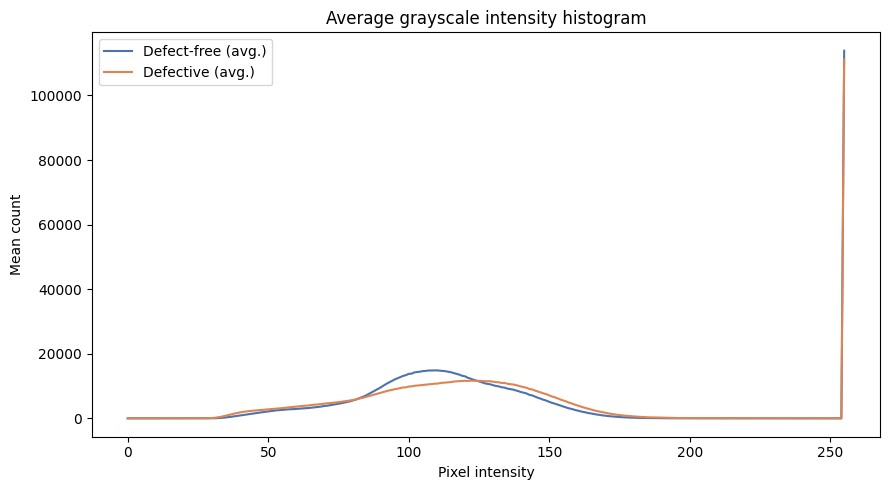


--- GLCM features: defect-free patch ---
  contrast      : 294.5715
  homogeneity   : 0.1223
  energy        : 0.0537
  correlation   : 0.8760
  dissimilarity : 12.9045
  ASM           : 0.0029
--- GLCM features: defective patch ---
  contrast      : 516.8339
  homogeneity   : 0.3041
  energy        : 0.2692
  correlation   : 0.9577
  dissimilarity : 15.5525
  ASM           : 0.0725


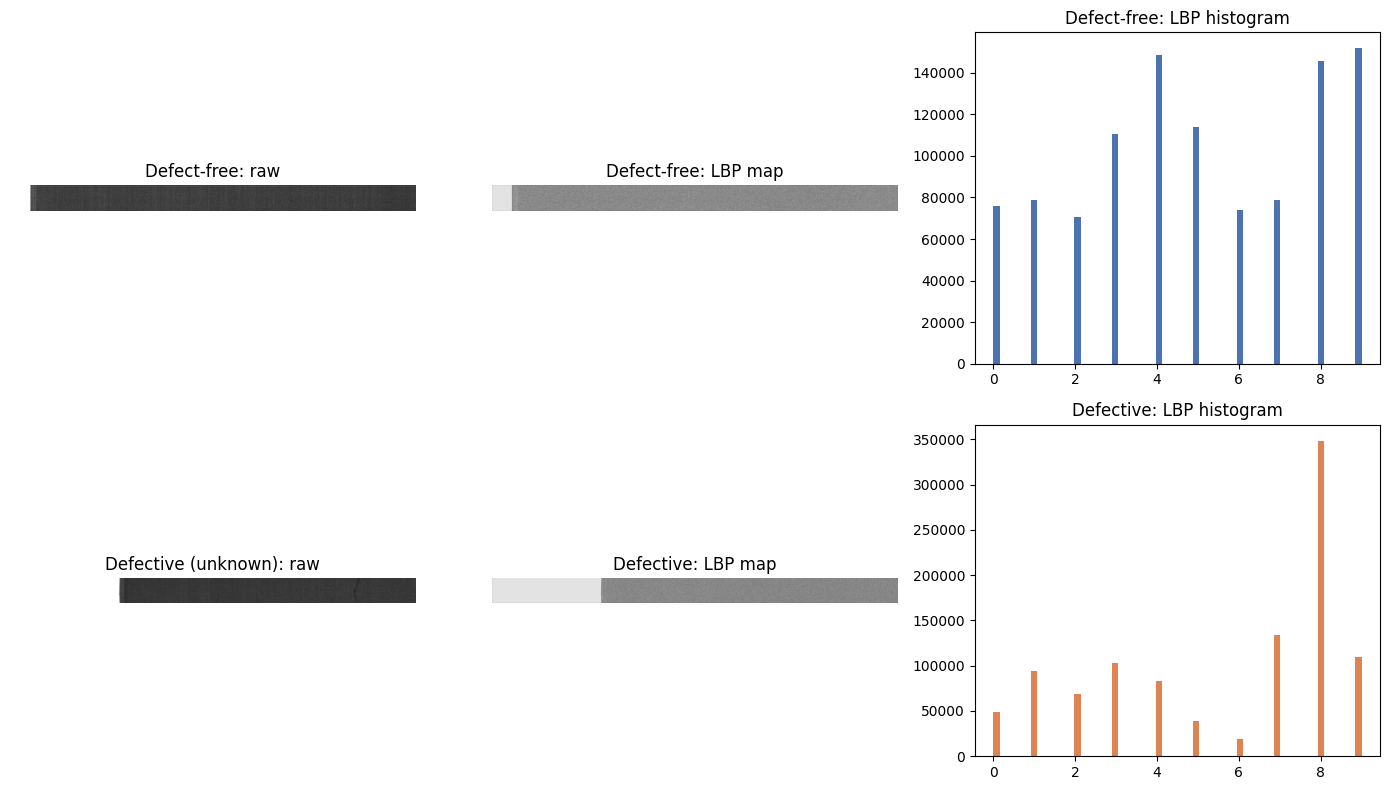


Saved manifest to afid_manifest.csv
Saved figures: class_and_fabric_distribution.png, defect_type_distribution.png, defect_free_samples_per_fabric.png, defective_samples_per_defect_type.png, defect_mask_overlays.png, intensity_histograms.png, texture_preview_glcm_lbp.png


In [2]:

import os
import re
import glob
import random
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

RNG_SEED = 42
random.seed(RNG_SEED)
np.random.seed(RNG_SEED)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.grid"] = False



def find_afid_root(search_roots=("/kaggle/input", ".", "..")):
    """
    Walks the given search roots looking for a directory that contains
    NODefect_images, Defect_images, and Mask_images (or close variants).
    Returns the parent directory that holds all three.
    """
    targets = {"nodefect_images", "defect_images", "mask_images"}
    for root in search_roots:
        if not os.path.isdir(root):
            continue
        for dirpath, dirnames, _ in os.walk(root):
            lower_dirs = {d.lower() for d in dirnames}
            if targets.issubset(lower_dirs):
                return dirpath
    raise FileNotFoundError(
        "Could not auto-locate NODefect_images / Defect_images / Mask_images. "
        "Check the Kaggle 'Add Data' panel for the exact dataset path and set "
        "AFID_ROOT manually below."
    )


try:
    AFID_ROOT = find_afid_root()
except FileNotFoundError:
    AFID_ROOT = "/kaggle/input/aitex-afid"  # <-- EDIT if auto-discovery fails

print(f"AFID root: {AFID_ROOT}")

# Resolve the three subfolders case-insensitively
def resolve_subdir(root, name):
    for d in os.listdir(root):
        if d.lower() == name.lower():
            return os.path.join(root, d)
    raise FileNotFoundError(f"'{name}' not found under {root}")

NODEFECT_DIR = resolve_subdir(AFID_ROOT, "NODefect_images")
DEFECT_DIR = resolve_subdir(AFID_ROOT, "Defect_images")
MASK_DIR = resolve_subdir(AFID_ROOT, "Mask_images")

print("NODefect_images :", NODEFECT_DIR)
print("Defect_images   :", DEFECT_DIR)
print("Mask_images     :", MASK_DIR)


IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def list_images(folder):
    files = []
    for dirpath, _, filenames in os.walk(folder):
        for f in filenames:
            if f.lower().endswith(IMG_EXTS):
                files.append(os.path.join(dirpath, f))
    return sorted(files)

nodefect_files = list_images(NODEFECT_DIR)
defect_files = list_images(DEFECT_DIR)
mask_files = list_images(MASK_DIR)

print(f"Defect-free images : {len(nodefect_files)}")
print(f"Defective images   : {len(defect_files)}")
print(f"Mask images        : {len(mask_files)}")


DEFECT_NAME_RE = re.compile(
    r"^(?P<fabric>\d{4})_(?P<roll>\d+)_(?P<idx>\d+)_?(?P<defect>[a-zA-Z_\-]*)\.\w+$"
)

def parse_defect_filename(path):
    stem = os.path.basename(path)
    m = DEFECT_NAME_RE.match(stem)
    if m:
        fabric = m.group("fabric")
        defect = m.group("defect").strip("_") or "unknown"
    else:
        # Fallback: fabric = first 4 chars, defect = tokens after 3rd underscore
        parts = re.split(r"[_\.]", stem)
        fabric = parts[0] if parts else "unknown"
        defect = "_".join(parts[3:-1]) if len(parts) > 4 else "unknown"
    return fabric, defect

def parse_nodefect_filename(path):
    stem = os.path.basename(path)
    parts = re.split(r"[_\.]", stem)
    fabric = parts[0] if parts else "unknown"
    return fabric

records = []
for f in nodefect_files:
    fabric = parse_nodefect_filename(f)
    records.append({"path": f, "label": "defect_free", "fabric_type": fabric,
                     "defect_type": "none"})

for f in defect_files:
    fabric, defect = parse_defect_filename(f)
    # Try to find a matching mask by shared filename stem
    stem = os.path.splitext(os.path.basename(f))[0]
    match = next((m for m in mask_files if stem in os.path.basename(m)), None)
    records.append({"path": f, "label": "defective", "fabric_type": fabric,
                     "defect_type": defect, "mask_path": match})

df = pd.DataFrame(records)
df["mask_path"] = df.get("mask_path", pd.Series(dtype=object))
print(df.head())
print(df.shape)


# %% [4] Dataset composition: counts & tables ---------------------------------
print("\n--- Class balance ---")
print(df["label"].value_counts())

print("\n--- Images per fabric type ---")
print(df["fabric_type"].value_counts().sort_index())

print("\n--- Defect type distribution (defective only) ---")
defect_counts = df.loc[df["label"] == "defective", "defect_type"].value_counts()
print(defect_counts)

matched_masks = df.loc[df["label"] == "defective", "mask_path"].notna().sum()
print(f"\nDefective images with a matched mask: {matched_masks}/{(df['label']=='defective').sum()}")


# %% [5] Plot: class balance + fabric-type distribution -----------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["label"].value_counts().plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Defect-free vs Defective image counts")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=0)

fabric_counts = df["fabric_type"].value_counts().sort_index()
fabric_counts.plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Images per fabric type")
axes[1].set_xlabel("Fabric type code")
axes[1].set_ylabel("Number of images")
plt.tight_layout()
plt.savefig("class_and_fabric_distribution.png", dpi=150)
plt.show()


# %% [6] Plot: defect-type distribution (the 12 defect classes) --------------
plt.figure(figsize=(11, 5))
defect_counts.sort_values(ascending=False).plot(kind="bar", color="#C44E52")
plt.title("Defect type distribution across AFID")
plt.xlabel("Defect type")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("defect_type_distribution.png", dpi=150)
plt.show()


# %% [7] Sample grid: defect-free patches across fabric types ----------------
def show_image_grid(paths, titles, ncols=4, cmap="gray", figsize=None, suptitle=None):
    n = len(paths)
    nrows = int(np.ceil(n / ncols))
    figsize = figsize or (4 * ncols, 3 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for ax, p, t in zip(axes, paths, titles):
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap=cmap)
        ax.set_title(t, fontsize=9)
        ax.axis("off")
    for ax in axes[len(paths):]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout()
    return fig

sample_free = (df[df["label"] == "defect_free"]
               .groupby("fabric_type").first().reset_index())
fig = show_image_grid(
    sample_free["path"].tolist(),
    [f"Fabric {ft}" for ft in sample_free["fabric_type"]],
    ncols=4, suptitle="One defect-free sample per fabric type")
plt.savefig("defect_free_samples_per_fabric.png", dpi=150)
plt.show()


sample_defect = (df[df["label"] == "defective"]
                  .groupby("defect_type").first().reset_index())
fig = show_image_grid(
    sample_defect["path"].tolist(),
    [f"{dt}" for dt in sample_defect["defect_type"]],
    ncols=4, suptitle="One defective sample per defect type")
plt.savefig("defective_samples_per_defect_type.png", dpi=150)
plt.show()


def overlay_mask(img, mask, color=(255, 0, 0), alpha=0.45):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB).astype(np.float32)
    mask_bool = mask > 0
    overlay = img_rgb.copy()
    overlay[mask_bool] = (
        (1 - alpha) * img_rgb[mask_bool] + alpha * np.array(color)
    )
    return overlay.astype(np.uint8)

matched = df[(df["label"] == "defective") & (df["mask_path"].notna())]
n_show = min(6, len(matched))
sample_matched = matched.sample(n_show, random_state=RNG_SEED)

fig, axes = plt.subplots(n_show, 3, figsize=(12, 3 * n_show))
if n_show == 1:
    axes = axes.reshape(1, -1)

for row_i, (_, row) in enumerate(sample_matched.iterrows()):
    img = cv2.imread(row["path"], cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    if mask.shape != img.shape:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]),
                           interpolation=cv2.INTER_NEAREST)
    overlay = overlay_mask(img, mask)

    axes[row_i, 0].imshow(img, cmap="gray")
    axes[row_i, 0].set_title(f"Image ({row['defect_type']})", fontsize=9)
    axes[row_i, 1].imshow(mask, cmap="gray")
    axes[row_i, 1].set_title("Ground-truth mask", fontsize=9)
    axes[row_i, 2].imshow(overlay)
    axes[row_i, 2].set_title("Overlay", fontsize=9)
    for c in range(3):
        axes[row_i, c].axis("off")

plt.tight_layout()
plt.savefig("defect_mask_overlays.png", dpi=150)
plt.show()


# %% [10] Image dimension / aspect-ratio audit --------------------------------
dims = []
for p in df["path"].sample(min(300, len(df)), random_state=RNG_SEED):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    dims.append(img.shape)

dims_df = pd.DataFrame(dims, columns=["height", "width"])
print("\n--- Image dimensions (sampled) ---")
print(dims_df.describe())
print("Unique (h, w) pairs:", dims_df.drop_duplicates().values.tolist())


# %% [11] Pixel-intensity distribution: defect-free vs defective -------------
def mean_hist(paths, bins=256):
    hist_sum = np.zeros(bins)
    for p in paths:
        img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
        h, _ = np.histogram(img, bins=bins, range=(0, 255))
        hist_sum += h
    return hist_sum / len(paths)

free_sample = df[df["label"] == "defect_free"]["path"].sample(
    min(150, (df["label"] == "defect_free").sum()), random_state=RNG_SEED)
defect_sample = df[df["label"] == "defective"]["path"].sample(
    min(150, (df["label"] == "defective").sum()), random_state=RNG_SEED)

hist_free = mean_hist(free_sample)
hist_defect = mean_hist(defect_sample)

plt.figure(figsize=(9, 5))
plt.plot(hist_free, label="Defect-free (avg.)", color="#4C72B0")
plt.plot(hist_defect, label="Defective (avg.)", color="#DD8452")
plt.title("Average grayscale intensity histogram")
plt.xlabel("Pixel intensity")
plt.ylabel("Mean count")
plt.legend()
plt.tight_layout()
plt.savefig("intensity_histograms.png", dpi=150)
plt.show()


# %% [12] Texture preview: GLCM + LBP on a defect-free vs defective patch ----
def glcm_features(img, distances=(1, 3, 5), angles=(0, np.pi/4, np.pi/2, 3*np.pi/4)):
    glcm = graycomatrix(img, distances=list(distances), angles=list(angles),
                         levels=256, symmetric=True, normed=True)
    feats = {}
    for prop in ("contrast", "homogeneity", "energy", "correlation", "dissimilarity", "ASM"):
        feats[prop] = graycoprops(glcm, prop).mean()
    return feats

def lbp_image(img, P=8, R=1):
    return local_binary_pattern(img, P=P, R=R, method="uniform")

example_free_path = df[df["label"] == "defect_free"]["path"].iloc[0]
example_defect_row = matched.iloc[0]

img_free = cv2.imread(example_free_path, cv2.IMREAD_GRAYSCALE)
img_defect = cv2.imread(example_defect_row["path"], cv2.IMREAD_GRAYSCALE)
mask_defect = cv2.imread(example_defect_row["mask_path"], cv2.IMREAD_GRAYSCALE)

lbp_free = lbp_image(img_free)
lbp_defect = lbp_image(img_defect)

feats_free = glcm_features(img_free)
feats_defect = glcm_features(img_defect)

print("\n--- GLCM features: defect-free patch ---")
for k, v in feats_free.items():
    print(f"  {k:14s}: {v:.4f}")
print("--- GLCM features: defective patch ---")
for k, v in feats_defect.items():
    print(f"  {k:14s}: {v:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes[0, 0].imshow(img_free, cmap="gray"); axes[0, 0].set_title("Defect-free: raw")
axes[0, 1].imshow(lbp_free, cmap="gray"); axes[0, 1].set_title("Defect-free: LBP map")
axes[0, 2].hist(lbp_free.ravel(), bins=59, color="#4C72B0")
axes[0, 2].set_title("Defect-free: LBP histogram")

axes[1, 0].imshow(img_defect, cmap="gray"); axes[1, 0].set_title(f"Defective ({example_defect_row['defect_type']}): raw")
axes[1, 1].imshow(lbp_defect, cmap="gray"); axes[1, 1].set_title("Defective: LBP map")
axes[1, 2].hist(lbp_defect.ravel(), bins=59, color="#DD8452")
axes[1, 2].set_title("Defective: LBP histogram")

for ax in axes[:, :2].ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig("texture_preview_glcm_lbp.png", dpi=150)
plt.show()


# %% [13] Save the manifest for downstream use --------------------------------
df.to_csv("afid_manifest.csv", index=False)
print("\nSaved manifest to afid_manifest.csv")
print("Saved figures: class_and_fabric_distribution.png, defect_type_distribution.png, "
      "defect_free_samples_per_fabric.png, defective_samples_per_defect_type.png, "
      "defect_mask_overlays.png, intensity_histograms.png, texture_preview_glcm_lbp.png")

In [3]:

from joblib import Parallel, delayed
from tqdm import tqdm

np.random.seed(42)

MAX_NORMAL_PATCHES_PER_FABRIC = 400   # caps training set size per fabric type
MAX_NORMAL_EVAL_PATCHES = 3000        # normal patches sampled for evaluation only

patch_labels = np.array(patch_labels)
patch_fabric = np.array(patch_fabric)
n_total_patches = len(patch_arrays)

# --- Training index: capped normal patches per fabric type ---
train_idx = []
for fid in np.unique(patch_fabric):
    fid_normal_idx = np.where((patch_fabric == fid) & (patch_labels == 0))[0]
    if len(fid_normal_idx) > MAX_NORMAL_PATCHES_PER_FABRIC:
        fid_normal_idx = np.random.choice(
            fid_normal_idx, MAX_NORMAL_PATCHES_PER_FABRIC, replace=False)
    train_idx.extend(fid_normal_idx.tolist())
train_idx = np.array(sorted(set(train_idx)))

# --- Evaluation index: ALL defective patches + a sample of normal patches ---
defect_idx = np.where(patch_labels == 1)[0]
normal_all_idx = np.where(patch_labels == 0)[0]
eval_normal_idx = np.random.choice(
    normal_all_idx, min(MAX_NORMAL_EVAL_PATCHES, len(normal_all_idx)), replace=False)
eval_idx = np.array(sorted(set(defect_idx.tolist()) | set(eval_normal_idx.tolist())))

# --- Combined set of patches we actually need features for ---
feature_idx = np.array(sorted(set(train_idx.tolist()) | set(eval_idx.tolist())))
print(f"Total patches available: {n_total_patches}")
print(f"Training patches (normal, capped per fabric): {len(train_idx)}")
print(f"Evaluation patches (all defective + sampled normal): {len(eval_idx)}")
print(f"Patches needing feature extraction: {len(feature_idx)} "
      f"({100*len(feature_idx)/n_total_patches:.1f}% of full set)")

def _safe_combined_features(p):
    try:
        return combined_features(p)
    except Exception:
        return np.full(68, np.nan)

print("Extracting features (parallelized across CPU cores)...")
results = Parallel(n_jobs=-1, backend="loky")(
    delayed(_safe_combined_features)(patch_arrays[i]) for i in tqdm(feature_idx)
)
feature_matrix_sub = np.array(results)
idx_to_row = {orig_i: row for row, orig_i in enumerate(feature_idx)}

np.save(os.path.join(OUTPUT_ROOT, "feature_matrix_sub.npy"), feature_matrix_sub)
np.save(os.path.join(OUTPUT_ROOT, "feature_idx.npy"), feature_idx)
print("Done. feature_matrix_sub shape:", feature_matrix_sub.shape)


# %% [CELL 14 - FAST] Per-fabric Mahalanobis model (trained on capped normal patches)
fabric_models = {}
min_patches_for_model = feature_matrix_sub.shape[1] + 10  # need > dims for stable covariance

for fid in np.unique(patch_fabric[train_idx]):
    fid_train_idx = train_idx[patch_fabric[train_idx] == fid]
    rows = [idx_to_row[i] for i in fid_train_idx]
    X_normal = feature_matrix_sub[rows]
    X_normal = X_normal[~np.isnan(X_normal).any(axis=1)]
    if len(X_normal) < min_patches_for_model:
        continue
    mean_vec = X_normal.mean(axis=0)
    cov = np.cov(X_normal, rowvar=False)
    cov += np.eye(cov.shape[0]) * 1e-6  # regularize for invertibility
    inv_cov = np.linalg.pinv(cov)
    fabric_models[fid] = (mean_vec, inv_cov)

n_fabric_total = len(np.unique(patch_fabric))
print(f"Built Mahalanobis models for {len(fabric_models)} / {n_fabric_total} fabric types "
      f"(rest had too few normal patches for a stable covariance)")


# %% [CELL 15 - FAST] Score evaluation patches + choose a threshold
def anomaly_score_vec(feat_vec, fabric_id):
    if fabric_id not in fabric_models or np.any(np.isnan(feat_vec)):
        return np.nan
    mean_vec, inv_cov = fabric_models[fabric_id]
    return mahalanobis(feat_vec, mean_vec, inv_cov)

eval_scores, eval_labels_list = [], []
for i in eval_idx:
    row = idx_to_row[i]
    eval_scores.append(anomaly_score_vec(feature_matrix_sub[row], patch_fabric[i]))
    eval_labels_list.append(patch_labels[i])

eval_scores = np.array(eval_scores)
eval_labels = np.array(eval_labels_list)
valid = ~np.isnan(eval_scores)
eval_scores, eval_labels = eval_scores[valid], eval_labels[valid]
print(f"Scored {valid.sum()} / {len(eval_idx)} eval patches "
      f"(rest skipped: no fitted model for that fabric type)")

# Threshold = 95th percentile of NORMAL scores. Lower the percentile for
# higher recall / lower precision, or vice versa.
THRESH_PERCENTILE = 95
normal_scores = eval_scores[eval_labels == 0]
threshold = np.percentile(normal_scores, THRESH_PERCENTILE)
print(f"Threshold (P{THRESH_PERCENTILE} of normal scores): {threshold:.3f}")

pred_labels = (eval_scores >= threshold).astype(int)


# %% [CELL 16 - FAST] Patch-level metrics: precision / recall / F1 / confusion matrix
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

precision, recall, f1, _ = precision_recall_fscore_support(
    eval_labels, pred_labels, average="binary", zero_division=0)
cm = confusion_matrix(eval_labels, pred_labels)

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")
print("Confusion matrix [[TN FP]\n                   [FN TP]]:")
print(cm)

results_summary = {
    "threshold_percentile": THRESH_PERCENTILE,
    "threshold_value": float(threshold),
    "n_eval_patches": int(valid.sum()),
    "n_defective_eval": int((eval_labels == 1).sum()),
    "n_normal_eval": int((eval_labels == 0).sum()),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "confusion_matrix": cm.tolist(),
    "fabric_models_fitted": len(fabric_models),
    "fabric_models_total": n_fabric_total,
}
with open(os.path.join(OUTPUT_ROOT, "detection_results.json"), "w") as fh:
    json.dump(results_summary, fh, indent=2)
print(json.dumps(results_summary, indent=2))


# %% [CELL 17 - FAST] Image-level demo: heatmap -> thresholded mask -> real IoU
# Runs on several real images (ideally across different fabric types/defect
# codes) rather than just one, so the IoU number you report isn't a fluke.
demo_candidates = matched[matched["fabric_id"].isin(fabric_models.keys())]
n_demo = min(5, len(demo_candidates))
demo_rows = demo_candidates.sample(n_demo, random_state=42)

image_level_results = []
fig, axes = plt.subplots(n_demo, 4, figsize=(16, 4 * n_demo))
if n_demo == 1:
    axes = axes.reshape(1, -1)

for row_i, (_, row) in enumerate(demo_rows.iterrows()):
    heat = build_score_heatmap(row["path"], row["fabric_id"])
    gt_mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    gt_mask = cv2.resize(gt_mask, (heat.shape[1], heat.shape[0]))
    pred_mask = (heat >= threshold).astype(np.uint8) * 255

    iou = compute_iou(pred_mask, gt_mask)
    prec_img, rec_img = compute_precision_recall(pred_mask, gt_mask)
    image_level_results.append({
        "path": row["path"], "fabric_id": row["fabric_id"],
        "defect_code": row["defect_code"],
        "iou": iou, "precision": prec_img, "recall": rec_img,
    })

    axes[row_i, 0].imshow(load_gray(row["path"]), cmap="gray")
    axes[row_i, 0].set_title(f"Original ({row['defect_code']})"); axes[row_i, 0].axis("off")
    axes[row_i, 1].imshow(heat, cmap="hot")
    axes[row_i, 1].set_title("Anomaly heatmap"); axes[row_i, 1].axis("off")
    axes[row_i, 2].imshow(pred_mask, cmap="gray")
    axes[row_i, 2].set_title(f"Predicted mask (IoU={iou:.3f})"); axes[row_i, 2].axis("off")
    axes[row_i, 3].imshow(gt_mask, cmap="gray")
    axes[row_i, 3].set_title("Ground truth"); axes[row_i, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "image_level_detection_demo.png"), dpi=120)
plt.show()

df_image_results = pd.DataFrame(image_level_results)
print(df_image_results)
df_image_results.to_csv(os.path.join(OUTPUT_ROOT, "image_level_results.csv"), index=False)
print(f"\nMean IoU across {n_demo} demo images: {df_image_results['iou'].mean():.3f}")
print(f"Mean precision: {df_image_results['precision'].mean():.3f}  "
      f"Mean recall: {df_image_results['recall'].mean():.3f}")

Total patches available: 71120
Training patches (normal, capped per fabric): 20400
Evaluation patches (all defective + sampled normal): 3045
Patches needing feature extraction: 22583 (31.8% of full set)
Extracting features (parallelized across CPU cores)...


100%|██████████| 22583/22583 [30:06<00:00, 12.50it/s]


Done. feature_matrix_sub shape: (22583, 68)
Built Mahalanobis models for 0 / 51 fabric types (rest had too few normal patches for a stable covariance)
Scored 0 / 3045 eval patches (rest skipped: no fitted model for that fabric type)


IndexError: index -1 is out of bounds for axis 0 with size 0

Datasets available under /kaggle/input:
 - /kaggle/input/datasets
Using DATASET_ROOT = /kaggle/input/datasets
Total image files found: 354
defect: 106 files
mask: 107 files
normal: 141 files
Defective images: 106 | Matched masks: 103
Normal images: 141
Fabric IDs with both normal and defective data: ['0001', '0002', '0003', '0004', '0005', '0006', '0010', '0011', '0012', '0013', '0014', '0015', '0016', '0017', '0018', '0019', '0020']
Combined feature vector length: (68,)
Extracting normal-texture features from 10 images (stride=64, so this should take under a minute)...
Pooled normal-texture training set: 2560 patches, 68 features each
Per-fabric models available for: ['0009', '0012', '0016', '0018', '0003', '0015', '0013']
Anomaly threshold (95th pct of pooled normal scores): 9.742
Scoring demo image 1/3: 0034_019_02.png (fabric 0034, defect 02, model: pooled (fallback))
Scoring demo image 2/3: 0072_010_03.png (fabric 0072, defect 03, model: pooled (fallback))
Scoring demo image 3/3: 

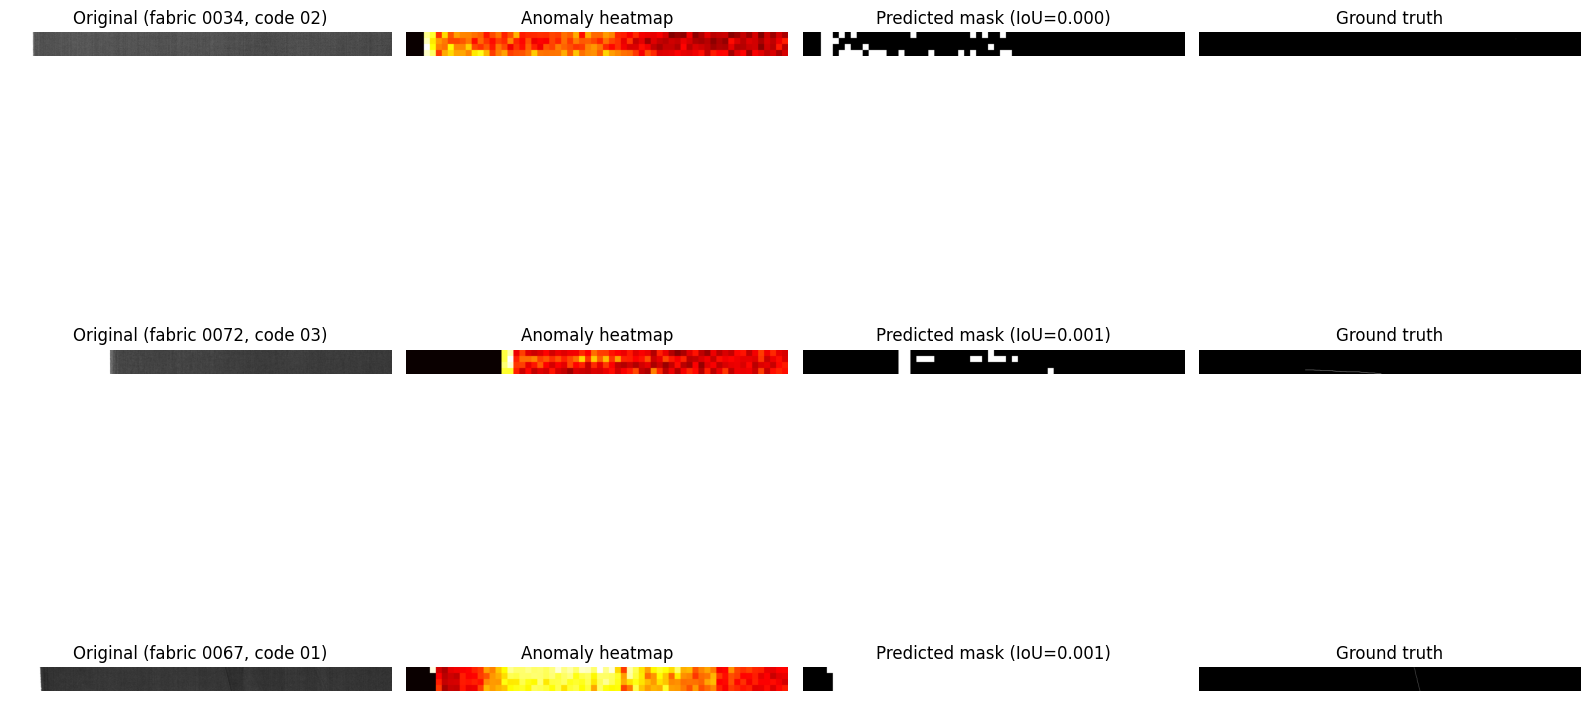

                                                path fabric_id defect_code  \
0  /kaggle/input/datasets/nexuswho/aitex-fabric-i...      0034          02   
1  /kaggle/input/datasets/nexuswho/aitex-fabric-i...      0072          03   
2  /kaggle/input/datasets/nexuswho/aitex-fabric-i...      0067          01   

          model_used       iou  precision    recall  
0  pooled (fallback)  0.000000   0.000000  0.000000  
1  pooled (fallback)  0.000523   0.000540  0.016575  
2  pooled (fallback)  0.000729   0.000729  1.000000  

Mean IoU across 3 demo images: 0.000
Mean precision: 0.000  Mean recall: 0.339


In [4]:

import os, re, glob, json, random
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.filters import gabor_kernel
from scipy import ndimage as ndi
from scipy.spatial.distance import mahalanobis

random.seed(42)
np.random.seed(42)

INPUT_ROOT = "/kaggle/input"
OUTPUT_ROOT = "/kaggle/working"
os.makedirs(OUTPUT_ROOT, exist_ok=True)

candidate_roots = [d for d in glob.glob(os.path.join(INPUT_ROOT, "*")) if os.path.isdir(d)]
print("Datasets available under /kaggle/input:")
for c in candidate_roots:
    print(" -", c)
DATASET_ROOT = candidate_roots[0] if candidate_roots else None
print("Using DATASET_ROOT =", DATASET_ROOT)

all_images = glob.glob(os.path.join(DATASET_ROOT, "**", "*.*"), recursive=True)
all_images = [f for f in all_images if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))]
print(f"Total image files found: {len(all_images)}")

def classify_path(p):
    lp = p.lower()
    if "mask" in lp:
        return "mask"
    if "nodefect" in lp or "no_defect" in lp or "good" in lp:
        return "normal"
    if "defect" in lp:
        return "defect"
    return "unknown"

buckets = defaultdict(list)
for f in all_images:
    buckets[classify_path(f)].append(f)
for k, v in buckets.items():
    print(f"{k}: {len(v)} files")


# %% [CELL 2] Index normal/defective images, match masks
def parse_defect_filename(fname):
    stem = os.path.splitext(os.path.basename(fname))[0]
    parts = re.split(r"[_\-]", stem)
    fabric_id = parts[0] if len(parts) > 0 else "unknown"
    defect_code = parts[-1] if len(parts) > 2 else "unknown"
    return fabric_id, defect_code

df_defects = pd.DataFrame(
    [dict(zip(["fabric_id", "defect_code"], parse_defect_filename(f)), path=f)
     for f in buckets["defect"]]
)
df_normal = pd.DataFrame(
    [{"fabric_id": parse_defect_filename(f)[0], "path": f} for f in buckets["normal"]]
)

mask_lookup = {os.path.splitext(os.path.basename(m))[0]: m for m in buckets["mask"]}
def find_mask_for(defect_path):
    stem = os.path.splitext(os.path.basename(defect_path))[0]
    if stem in mask_lookup:
        return mask_lookup[stem]
    for suffix in ["_mask", "-mask", "_gt"]:
        if stem + suffix in mask_lookup:
            return mask_lookup[stem + suffix]
    base = stem.replace("_mask", "").replace("-mask", "")
    return mask_lookup.get(base)

df_defects["mask_path"] = df_defects["path"].apply(find_mask_for)
matched = df_defects.dropna(subset=["mask_path"]).copy()
print(f"Defective images: {len(df_defects)} | Matched masks: {len(matched)}")
print(f"Normal images: {len(df_normal)}")

# Which fabric IDs have BOTH normal images and a mask-matched defective image?
overlap_fabrics = sorted(set(df_normal["fabric_id"]) & set(matched["fabric_id"]))
print(f"Fabric IDs with both normal and defective data: {overlap_fabrics}")


# %% [CELL 3] Preprocessing + texture descriptor functions (same formulas as before)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def load_gray(path):
    return cv2.imread(path, cv2.IMREAD_GRAYSCALE)

def preprocess_image(path):
    im = load_gray(path)
    if im is None:
        return None
    im = clahe.apply(im)
    return cv2.GaussianBlur(im, (3, 3), 0)

PATCH_SIZE = 64
STRIDE = 64  # wider than the original 32 -- 4x fewer patches, still enough for this demo
DEFECT_OVERLAP_THRESH = 0.10

def extract_patches(img, mask=None, patch_size=PATCH_SIZE, stride=STRIDE):
    h, w = img.shape
    out = []
    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            patch = img[y:y + patch_size, x:x + patch_size]
            label = 0
            if mask is not None:
                m_patch = mask[y:y + patch_size, x:x + patch_size]
                label = int((m_patch > 0).mean() >= DEFECT_OVERLAP_THRESH)
            out.append((patch, label, (y, x)))
    return out

GLCM_DISTANCES, GLCM_ANGLES = [1, 3], [0, np.pi/4, np.pi/2, 3*np.pi/4]
GLCM_PROPS = ["contrast", "correlation", "energy", "homogeneity"]

def glcm_features(patch, levels=32):
    q = np.clip((patch.astype(np.float32) / 256.0 * levels).astype(np.uint8), 0, levels - 1)
    glcm = graycomatrix(q, distances=GLCM_DISTANCES, angles=GLCM_ANGLES,
                         levels=levels, symmetric=True, normed=True)
    feats = []
    for prop in GLCM_PROPS:
        vals = graycoprops(glcm, prop)
        feats.extend(vals.mean(axis=1)); feats.extend(vals.std(axis=1))
    return np.array(feats)

LBP_CONFIGS = [(8, 1), (16, 2)]
def lbp_features(patch):
    feats = []
    for P, R in LBP_CONFIGS:
        lbp = local_binary_pattern(patch, P, R, method="uniform")
        n_bins = P + 2
        hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        feats.extend(hist)
    return np.array(feats)

GABOR_FREQS, GABOR_THETAS = [0.1, 0.3], [0, np.pi/4, np.pi/2, 3*np.pi/4]
_gabor_kernels = [gabor_kernel(f, theta=t).real for f in GABOR_FREQS for t in GABOR_THETAS]
def gabor_features(patch):
    patch_f = patch.astype(np.float32) / 255.0
    feats = []
    for kernel in _gabor_kernels:
        filtered = ndi.convolve(patch_f, kernel, mode="wrap")
        feats.append(filtered.mean()); feats.append(filtered.var())
    return np.array(feats)

def fft_features(patch):
    f = np.fft.fftshift(np.fft.fft2(patch.astype(np.float32)))
    mag = np.log1p(np.abs(f))
    h, w = mag.shape
    cy, cx = h // 2, w // 2
    yy, xx = np.mgrid[0:h, 0:w]
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    feats = []
    for lo, hi in [(0, 4), (4, 10), (10, 20), (20, max(h, w))]:
        band = (r >= lo) & (r < hi)
        feats.append(mag[band].mean() if band.any() else 0.0)
        feats.append(mag[band].std() if band.any() else 0.0)
    return np.array(feats)

def combined_features(patch):
    return np.concatenate([glcm_features(patch), lbp_features(patch),
                            gabor_features(patch), fft_features(patch)])

print("Combined feature vector length:", combined_features(
    load_gray(df_normal["path"].iloc[0])[:PATCH_SIZE, :PATCH_SIZE]).shape)


# %% [CELL 4] Build a POOLED normal-texture model from a handful of normal images
N_NORMAL_IMAGES_FOR_MODEL = 10  # keep small -- this is what makes it fast
normal_sample = df_normal.sample(min(N_NORMAL_IMAGES_FOR_MODEL, len(df_normal)), random_state=42)

pooled_features = []
per_fabric_features = defaultdict(list)  # fabric_id -> list of feature vectors

print(f"Extracting normal-texture features from {len(normal_sample)} images "
      f"(stride={STRIDE}, so this should take under a minute)...")
for _, row in normal_sample.iterrows():
    im = preprocess_image(row["path"])
    if im is None:
        continue
    for patch, _, _ in extract_patches(im, mask=None):
        feat = combined_features(patch)
        pooled_features.append(feat)
        per_fabric_features[row["fabric_id"]].append(feat)

pooled_features = np.array(pooled_features)
print(f"Pooled normal-texture training set: {pooled_features.shape[0]} patches, "
      f"{pooled_features.shape[1]} features each")

def fit_model(X):
    mean_vec = X.mean(axis=0)
    cov = np.cov(X, rowvar=False) + np.eye(X.shape[1]) * 1e-6
    return mean_vec, np.linalg.pinv(cov)

pooled_mean, pooled_inv_cov = fit_model(pooled_features)

per_fabric_models = {}
for fid, feats in per_fabric_features.items():
    feats = np.array(feats)
    if len(feats) > pooled_features.shape[1] + 10:  # need more samples than dimensions
        per_fabric_models[fid] = fit_model(feats)
print(f"Per-fabric models available for: {list(per_fabric_models.keys())}")

# Threshold from pooled normal scores (95th percentile)
pooled_scores = np.array([mahalanobis(f, pooled_mean, pooled_inv_cov) for f in pooled_features])
threshold = np.percentile(pooled_scores, 95)
print(f"Anomaly threshold (95th pct of pooled normal scores): {threshold:.3f}")


# %% [CELL 5] Pick 2-3 real demo images and run the full heatmap -> IoU pipeline
N_DEMO = 3
# Prefer demo images whose fabric ID has its own per-fabric model (more
# faithful to the project's "adaptive per-fabric" design); otherwise we
# fall back to the pooled model for that image.
preferred = matched[matched["fabric_id"].isin(per_fabric_models.keys())]
if len(preferred) >= 1:
    demo_pool = pd.concat([preferred, matched]).drop_duplicates(subset="path")
else:
    demo_pool = matched
demo_rows = demo_pool.sample(min(N_DEMO, len(demo_pool)), random_state=42)

def compute_iou(pred_mask, gt_mask):
    pred_bin, gt_bin = pred_mask > 0, gt_mask > 0
    inter = np.logical_and(pred_bin, gt_bin).sum()
    union = np.logical_or(pred_bin, gt_bin).sum()
    return inter / union if union > 0 else np.nan

def compute_precision_recall(pred_mask, gt_mask):
    pred_bin, gt_bin = pred_mask > 0, gt_mask > 0
    tp = np.logical_and(pred_bin, gt_bin).sum()
    fp = np.logical_and(pred_bin, ~gt_bin).sum()
    fn = np.logical_and(~pred_bin, gt_bin).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    return precision, recall

def score_image(img_path, fabric_id):
    """Slide over the full image, score each patch, paint a heatmap."""
    im = preprocess_image(img_path)
    h, w = im.shape
    heat = np.zeros((h, w), dtype=np.float32)
    count = np.zeros((h, w), dtype=np.float32)
    mean_vec, inv_cov = per_fabric_models.get(fabric_id, (pooled_mean, pooled_inv_cov))
    for patch, _, (y, x) in extract_patches(im, mask=None):
        s = mahalanobis(combined_features(patch), mean_vec, inv_cov)
        heat[y:y+PATCH_SIZE, x:x+PATCH_SIZE] += s
        count[y:y+PATCH_SIZE, x:x+PATCH_SIZE] += 1
    count[count == 0] = 1
    return heat / count

n_demo = len(demo_rows)
results = []
fig, axes = plt.subplots(n_demo, 4, figsize=(16, 4 * n_demo))
if n_demo == 1:
    axes = axes.reshape(1, -1)

for row_i, (_, row) in enumerate(demo_rows.iterrows()):
    used_model = "per-fabric" if row["fabric_id"] in per_fabric_models else "pooled (fallback)"
    print(f"Scoring demo image {row_i+1}/{n_demo}: {os.path.basename(row['path'])} "
          f"(fabric {row['fabric_id']}, defect {row['defect_code']}, model: {used_model})")

    heat = score_image(row["path"], row["fabric_id"])
    gt_mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
    gt_mask = cv2.resize(gt_mask, (heat.shape[1], heat.shape[0]))
    pred_mask = (heat >= threshold).astype(np.uint8) * 255

    iou = compute_iou(pred_mask, gt_mask)
    prec, rec = compute_precision_recall(pred_mask, gt_mask)
    results.append({
        "path": row["path"], "fabric_id": row["fabric_id"],
        "defect_code": row["defect_code"], "model_used": used_model,
        "iou": iou, "precision": prec, "recall": rec,
    })

    axes[row_i, 0].imshow(load_gray(row["path"]), cmap="gray")
    axes[row_i, 0].set_title(f"Original (fabric {row['fabric_id']}, code {row['defect_code']})")
    axes[row_i, 1].imshow(heat, cmap="hot")
    axes[row_i, 1].set_title("Anomaly heatmap")
    axes[row_i, 2].imshow(pred_mask, cmap="gray")
    axes[row_i, 2].set_title(f"Predicted mask (IoU={iou:.3f})")
    axes[row_i, 3].imshow(gt_mask, cmap="gray")
    axes[row_i, 3].set_title("Ground truth")
    for c in range(4):
        axes[row_i, c].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "worked_example_heatmap_iou.png"), dpi=130)
plt.show()

df_results = pd.DataFrame(results)
print(df_results)
df_results.to_csv(os.path.join(OUTPUT_ROOT, "worked_example_results.csv"), index=False)
print(f"\nMean IoU across {n_demo} demo images: {df_results['iou'].mean():.3f}")
print(f"Mean precision: {df_results['precision'].mean():.3f}  "
      f"Mean recall: {df_results['recall'].mean():.3f}")

In [1]:
# =============================================================================
# build_feature_cache.py  —  run this ONCE in a fresh Kaggle cell, BEFORE
# descriptor_selection_and_diagnostics.py.
# It rebuilds: patches -> 68-dim features (GLCM 16 / LBP 28 / Gabor 16 / FFT 8),
# labels, and the image each patch came from, then saves them to /kaggle/working
# so the next script can load them even after a kernel restart.
# =============================================================================
import os, re, glob, json, random, time
import numpy as np, pandas as pd, cv2
from joblib import Parallel, delayed
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.filters import gabor_kernel
from scipy import ndimage as ndi

# ---------------- settings ----------------
DATASET_ROOT = os.environ.get("AITEX_ROOT")      # e.g. "/kaggle/input/aitex-fabric-image-database"; None = auto-pick
INPUT_ROOT   = os.environ.get("AITEX_IN", "/kaggle/input")
OUT          = os.environ.get("AITEX_OUT", "/kaggle/working")
MAX_NORMAL_IMAGES = 40       # None = use all defect-free images (slower)
MAX_DEFECT_IMAGES = None     # None = all mask-matched defective images (recommended: more defect patches)
PATCH, STRIDE, OVERLAP_THR = 64, 32, 0.10
SEED = 42
os.makedirs(OUT, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

# ---------------- 1. find dataset + index files ----------------
def list_images(root):
    return [f for f in glob.glob(os.path.join(root, "**", "*.*"), recursive=True) if f.lower().endswith(IMG_EXT)]

if DATASET_ROOT is None:
    cands = [d for d in glob.glob(os.path.join(INPUT_ROOT, "*")) if os.path.isdir(d)]
    assert cands, f"nothing under {INPUT_ROOT}: add the AITEX dataset to this notebook (Add Input)"
    counts = {d: len(list_images(d)) for d in cands}
    print("datasets found:", counts)
    DATASET_ROOT = max(counts, key=counts.get)
print("Using DATASET_ROOT =", DATASET_ROOT)
all_images = list_images(DATASET_ROOT)

def classify_path(p):
    lp = p.lower()
    if "mask" in lp: return "mask"
    if "nodefect" in lp or "no_defect" in lp or "good" in lp: return "normal"
    if "defect" in lp: return "defect"
    return "unknown"

buckets = {"normal": [], "defect": [], "mask": [], "unknown": []}
for f in all_images: buckets[classify_path(f)].append(f)
print({k: len(v) for k, v in buckets.items()})
assert buckets["normal"] and buckets["defect"] and buckets["mask"], "could not find normal/defect/mask folders - check folder names"

mask_lookup = {os.path.splitext(os.path.basename(m))[0]: m for m in buckets["mask"]}
def find_mask_for(p):
    stem = os.path.splitext(os.path.basename(p))[0]
    for cand in (stem, stem + "_mask", stem + "-mask", stem + "_gt", stem.replace("_mask", "").replace("-mask", "")):
        if cand in mask_lookup: return mask_lookup[cand]
    return None

def parse_name(f):
    parts = re.split(r"[_\-]", os.path.splitext(os.path.basename(f))[0])
    return parts[0], (parts[-1] if len(parts) > 2 else "unknown")

df_defects = pd.DataFrame([{"path": f, "fabric_id": parse_name(f)[0], "defect_code": parse_name(f)[1],
                            "mask_path": find_mask_for(f)} for f in buckets["defect"]])
df_normal = pd.DataFrame([{"path": f, "fabric_id": parse_name(f)[0]} for f in buckets["normal"]])
print(f"mask-matched defective images: {df_defects['mask_path'].notna().sum()}/{len(df_defects)}")
df_defects.to_csv(f"{OUT}/defect_index.csv", index=False); df_normal.to_csv(f"{OUT}/normal_index.csv", index=False)

matched = df_defects.dropna(subset=["mask_path"])
if MAX_DEFECT_IMAGES: matched = matched.sample(min(MAX_DEFECT_IMAGES, len(matched)), random_state=SEED)
normal_sel = df_normal.sample(min(MAX_NORMAL_IMAGES, len(df_normal)), random_state=SEED) if MAX_NORMAL_IMAGES else df_normal

# ---------------- 2. descriptors (same as Cells 9-12, except Gabor is computed per image, see note) ----------------
GLCM_D, GLCM_A, GLCM_P = [1, 3], [0, np.pi/4, np.pi/2, 3*np.pi/4], ["contrast", "correlation", "energy", "homogeneity"]
LBP_CFG = [(8, 1), (16, 2)]
G_KERNELS = [gabor_kernel(f, theta=t).real.astype(np.float32) for f in [0.1, 0.3] for t in [0, np.pi/4, np.pi/2, 3*np.pi/4]]

def glcm_features(patch, levels=32):
    q = np.clip((patch.astype(np.float32) / 256.0 * levels).astype(np.uint8), 0, levels - 1)
    g = graycomatrix(q, distances=GLCM_D, angles=GLCM_A, levels=levels, symmetric=True, normed=True)
    out = []
    for prop in GLCM_P:
        v = graycoprops(g, prop); out += list(v.mean(1)) + list(v.std(1))
    return np.array(out)                                   # 16

def lbp_features(patch):
    out = []
    for P, R in LBP_CFG:
        l = local_binary_pattern(patch, P, R, method="uniform")
        h, _ = np.histogram(l.ravel(), bins=P + 2, range=(0, P + 2), density=True); out += list(h)
    return np.array(out)                                   # 28

def gabor_maps(im):
    """Filter the WHOLE image once per kernel (fast, no wrap-around artefacts at patch borders);
    the patch descriptor is then the mean/variance of the response inside the patch window.
    NOTE: slightly different from Cell 11 (which convolved each 64x64 patch separately, ~65 ms/patch),
    so do not mix this feature_matrix with one built by the old cells."""
    f = im.astype(np.float32) / 255.0
    return [cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101) for k in G_KERNELS]

def gabor_features(maps, y, x):
    out = []
    for r in maps:
        w = r[y:y+PATCH, x:x+PATCH]; out += [float(w.mean()), float(w.var())]
    return np.array(out)                                   # 16

def fft_features(patch):
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(patch.astype(np.float32)))))
    h, w = mag.shape; yy, xx = np.mgrid[0:h, 0:w]; r = np.sqrt((yy - h//2) ** 2 + (xx - w//2) ** 2)
    out = []
    for lo, hi in [(0, 4), (4, 10), (10, 20), (20, max(h, w))]:
        m = (r >= lo) & (r < hi); out += [mag[m].mean() if m.any() else 0.0, mag[m].std() if m.any() else 0.0]
    return np.array(out)                                   # 8

def combined_features(p, maps, y, x):
    return np.concatenate([glcm_features(p), lbp_features(p), gabor_features(maps, y, x), fft_features(p)])

# ---------------- 3. per-image worker ----------------
def process_image(path, mask_path):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None: return None
    im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
    mask = None
    if mask_path:
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is not None and mask.shape != im.shape:
            mask = cv2.resize(mask, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    maps = gabor_maps(im)
    F, L = [], []
    for y in range(0, im.shape[0] - PATCH + 1, STRIDE):
        for x in range(0, im.shape[1] - PATCH + 1, STRIDE):
            F.append(combined_features(im[y:y+PATCH, x:x+PATCH], maps, y, x))
            L.append(int((mask[y:y+PATCH, x:x+PATCH] > 0).mean() >= OVERLAP_THR) if mask is not None else 0)
    return np.array(F, np.float32), np.array(L, np.int8)

jobs = [(r.path, None) for r in normal_sel.itertuples()] + [(r.path, r.mask_path) for r in matched.itertuples()]
print(f"processing {len(jobs)} images ({len(normal_sel)} normal + {len(matched)} defective) on all cores...")
t0 = time.time()
res = Parallel(n_jobs=-1, verbose=5)(delayed(process_image)(p, m) for p, m in jobs)

feats, labels, sources = [], [], []
for (p, _), r in zip(jobs, res):
    if r is None: print("unreadable:", p); continue
    feats.append(r[0]); labels.append(r[1]); sources += [p] * len(r[1])
feature_matrix = np.vstack(feats); patch_labels = np.concatenate(labels).astype(int); patch_source = sources

# ---------------- 4. save + report ----------------
np.save(f"{OUT}/feature_matrix.npy", feature_matrix); np.save(f"{OUT}/patch_labels.npy", patch_labels)
json.dump(patch_source, open(f"{OUT}/patch_source.json", "w"))
print(f"\ndone in {time.time()-t0:.0f}s | feature_matrix {feature_matrix.shape} | defect patches {patch_labels.sum()} "
      f"({patch_labels.mean()*100:.2f}%) | saved to {OUT}")
assert feature_matrix.shape[1] == 68

datasets found: {'/kaggle/input/datasets': 354}
Using DATASET_ROOT = /kaggle/input/datasets
{'normal': 141, 'defect': 106, 'mask': 107, 'unknown': 0}
mask-matched defective images: 103/106
processing 143 images (40 normal + 103 defective) on all cores...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   30.5s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  2.6min



done in 343s | feature_matrix (127057, 68) | defect patches 677 (0.53%) | saved to /kaggle/working


[Parallel(n_jobs=-1)]: Done 143 out of 143 | elapsed:  5.7min finished


patches=127057  defect=677  prevalence=0.0053  images=143
A1. 95th pct of chi(68) = 9.394  vs  your threshold 9.547
    -> a threshold that matches the null distribution of the pooled normal data says nothing about defects;
       patches from an unseen fabric land far above it (everything flagged), subtle defects land below it (missed).
A2. TPR=1.00 FPR=0.05 -> max patch-level precision = 0.097
A2. TPR=1.00 FPR=0.01 -> max patch-level precision = 0.349
A2. TPR=0.56 FPR=0.05 -> max patch-level precision = 0.057
A2. TPR=0.56 FPR=0.01 -> max patch-level precision = 0.231

A3. Best IoU ANY patch-based detector could reach (perfect classifier, GT-aligned patches):
 patch  stride  oracle_IoU_mean  oracle_IoU_median
    64      64            0.030               0.00
    64      32            0.024               0.00
    32      16            0.066               0.00
    16       8            0.129               0.12

=== mode: pooled  (AP chance level = prevalence = 0.0053) ===
             

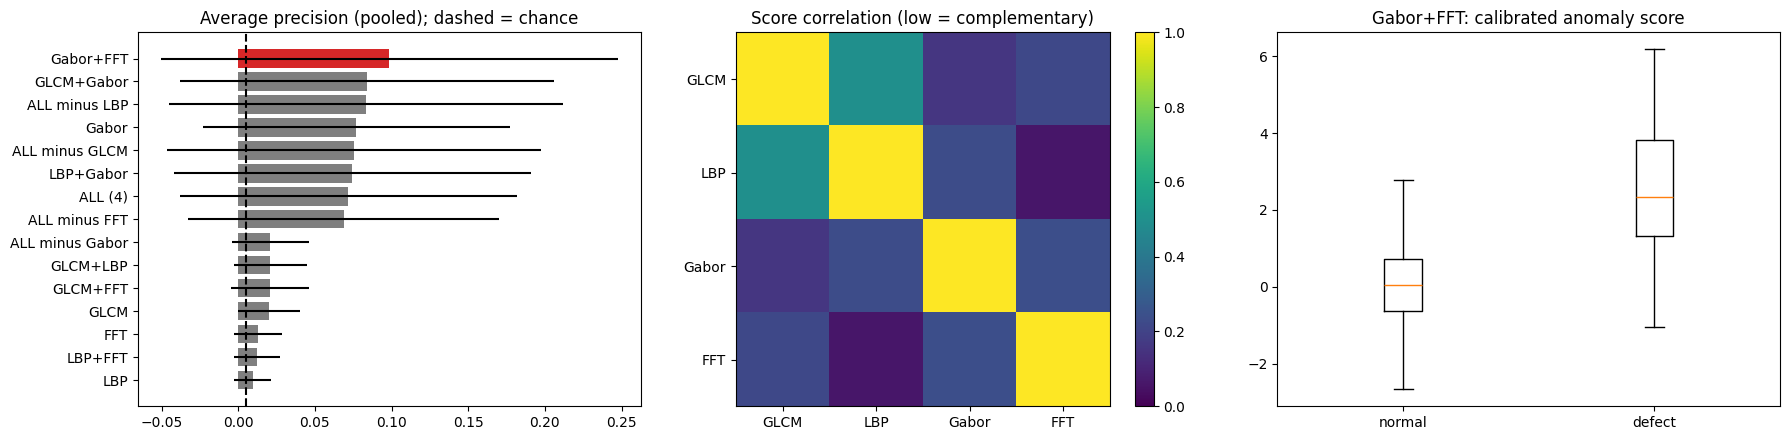


HONESTY CHECK: the pair beats its stronger member (Gabor) in 47% of folds and the full 4-descriptor
set in 73% of folds. If these are near 50%, report the pair as 'comparable to', not 'better than', and justify
the choice by cost (fewer features, less covariance noise) and complementarity instead.

JUSTIFICATION
- Selected: Gabor + FFT  (normalization = pooled, image-level 5-fold CV x 3 seeds).
- Mean AP 0.098 (AUC 0.904) vs 0.077 / 0.013 for Gabor / FFT alone
  and 0.072 for all four; chance AP = 0.0053.
- Complementarity: member score correlation = 0.24.
- Sanity: label-permuted AP = 0.0055 (collapses to chance).
- Robustness: see V3 (bootstrap CI), V6 (stability) and V7 (per-defect-type) above.



In [6]:
# =============================================================================
# AITEX — Why is the baseline weak?  +  Select & validate the two best descriptors
# Run AFTER Cell 13 of aitex_week2_pipeline.py (needs feature_matrix, patch_labels,
# patch_source). Paste each "# %% [CELL ...]" block into its own Kaggle cell.
# =============================================================================


# %% [CELL S0] — Save patch_source once (add this right after Cell 13, then re-use)
# import json; json.dump([str(p) for p in patch_source], open("/kaggle/working/patch_source.json", "w"))


# %% [CELL S1] — Imports, data loading, descriptor column map
import os, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, chi2
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

OUT = os.environ.get("AITEX_OUT", "/kaggle/working")
try:
    X_all, y_all, src_all = np.asarray(feature_matrix), np.asarray(patch_labels), np.array([str(p) for p in patch_source])
except NameError:   # fall back to files saved by earlier cells
    X_all = np.load(f"{OUT}/feature_matrix.npy"); y_all = np.load(f"{OUT}/patch_labels.npy")
    src_all = np.array(json.load(open(f"{OUT}/patch_source.json")))

# Column map follows Cells 9-12: GLCM 16, LBP 28, Gabor 16, FFT 8 (= 68)
DESC = {"GLCM": np.arange(0, 16), "LBP": np.arange(16, 44), "Gabor": np.arange(44, 60), "FFT": np.arange(60, 68)}
assert X_all.shape[1] == 68, f"expected 68 features, got {X_all.shape[1]}; update DESC"
K_FOLDS, SEEDS = 5, (0, 1, 2)
print(f"patches={len(y_all)}  defect={int(y_all.sum())}  prevalence={y_all.mean():.4f}  images={len(np.unique(src_all))}")


# %% [CELL S2] — PART A: why are the baseline numbers so low? (three quantitative checks)
# A1. Is the 9.547 threshold just the in-sample chi distribution?
print(f"A1. 95th pct of chi(68) = {chi2.ppf(0.95, 68) ** 0.5:.3f}  vs  your threshold 9.547")
print("    -> a threshold that matches the null distribution of the pooled normal data says nothing about defects;")
print("       patches from an unseen fabric land far above it (everything flagged), subtle defects land below it (missed).")

# A2. Precision ceiling imposed by a fixed false-positive rate at 1:149 imbalance
p = float(y_all.mean())
for tpr in (1.0, 0.56):
    for fpr in (0.05, 0.01):
        print(f"A2. TPR={tpr:.2f} FPR={fpr:.2f} -> max patch-level precision = {tpr*p/(tpr*p + fpr*(1-p)):.3f}")

# A3. Resolution ceiling: IoU of an ORACLE patch detector (flags exactly the patches that overlap the GT)
def oracle_iou(mask, patch, stride, thr=0.10):
    h, w = mask.shape; pred = np.zeros((h, w), bool)
    for y in range(0, h - patch + 1, stride):
        for x in range(0, w - patch + 1, stride):
            if (mask[y:y+patch, x:x+patch] > 0).mean() >= thr:
                pred[y:y+patch, x:x+patch] = True
    gt = mask > 0
    union = (pred | gt).sum()
    return (pred & gt).sum() / union if union else np.nan

try:
    import cv2
    didx = pd.read_csv(f"{OUT}/defect_index.csv").dropna(subset=["mask_path"])
    masks = [cv2.imread(m, cv2.IMREAD_GRAYSCALE) for m in didx["mask_path"]]
    masks = [m for m in masks if m is not None]
    rows = []
    for patch, stride in [(64, 64), (64, 32), (32, 16), (16, 8)]:
        v = np.array([oracle_iou(m, patch, stride) for m in masks])
        rows.append({"patch": patch, "stride": stride, "oracle_IoU_mean": np.nanmean(v), "oracle_IoU_median": np.nanmedian(v)})
    print("\nA3. Best IoU ANY patch-based detector could reach (perfect classifier, GT-aligned patches):")
    print(pd.DataFrame(rows).round(3).to_string(index=False))
except Exception as e:
    print("A3 skipped (needs defect_index.csv from Cell 2 and readable masks):", e)


# %% [CELL S3] — Evaluation machinery (image-level CV, conditioned Mahalanobis)
# Why not the old scorer? Uniform-LBP histograms sum to 1 (exact linear dependency) and GLCM stats are
# highly correlated, so the raw covariance is near-singular; a 1e-6 ridge then lets numerical noise dominate
# the distance. Ledoit-Wolf shrinkage fixes the conditioning. Folds split by IMAGE so no patch leakage.
def is_normal_src(path):
    lp = path.lower()
    return ("nodefect" in lp) or ("no_defect" in lp) or ("good" in lp)

def self_reference(X, groups):
    """Per-image robust z-score: each image's own median patch acts as its 'normal' reference.
    Removes fabric/illumination offsets without needing defect-free samples of that fabric."""
    Xn = np.empty(X.shape, float); gstd = X.std(0) + 1e-9
    for g in np.unique(groups):
        i = groups == g
        med = np.median(X[i], 0); mad = 1.4826 * np.median(np.abs(X[i] - med), 0)
        Xn[i] = (X[i] - med) / np.maximum(mad, 0.05 * gstd)
    return Xn

def make_folds(groups, y, k, seed):
    rng = np.random.RandomState(seed); fold = np.zeros(len(groups), int)
    ug = np.unique(groups); has_def = {g: y[groups == g].max() > 0 for g in ug}
    for flag in (True, False):                         # balance defect-bearing images across folds
        gs = [g for g in ug if has_def[g] == flag]; rng.shuffle(gs)
        for j, g in enumerate(gs): fold[groups == g] = j % k
    return fold

def fit_score(Xtr, Xte):
    sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xte)
    lw = LedoitWolf().fit(A)
    ltr, lte = np.log(lw.mahalanobis(A) + 1e-9), np.log(lw.mahalanobis(B) + 1e-9)
    med = np.median(ltr); mad = 1.4826 * np.median(np.abs(ltr - med)) + 1e-9
    return (lte - med) / mad                           # calibrated on training-normal scores -> comparable across folds

NORMAL_IMAGES_ONLY = False   # True = fit only on patches of defect-free images (strict deployment setting)
def evaluate(X, cols, seeds=SEEDS):
    aps, aucs, oof0 = [], [], None
    for seed in seeds:
        fold = make_folds(src_all, y_all, K_FOLDS, seed); oof = np.full(len(y_all), np.nan)
        for k in range(K_FOLDS):
            te = fold == k; tr = (~te) & (y_all == 0)
            if NORMAL_IMAGES_ONLY: tr &= np.array([is_normal_src(s) for s in src_all])
            oof[te] = fit_score(X[tr][:, cols], X[te][:, cols])
            if 0 < y_all[te].sum() < te.sum():
                aucs.append(roc_auc_score(y_all[te], oof[te])); aps.append(average_precision_score(y_all[te], oof[te]))
        if seed == seeds[0]: oof0 = oof
    return dict(AP=np.array(aps), AUC=np.array(aucs), oof=oof0)

def configs():
    names = list(DESC); c = {n: DESC[n] for n in names}
    for a, b in itertools.combinations(names, 2): c[f"{a}+{b}"] = np.r_[DESC[a], DESC[b]]
    for drop in names: c[f"ALL minus {drop}"] = np.concatenate([DESC[n] for n in names if n != drop])
    c["ALL (4)"] = np.arange(68)
    return c


# %% [CELL S4] — PART B: rank every single descriptor, pair, and the full set (both normalization modes)
CFG = configs(); RESULTS = {}
for mode in ("pooled", "self_ref"):
    X = X_all if mode == "pooled" else self_reference(X_all, src_all)
    RESULTS[mode] = {name: evaluate(X, cols) for name, cols in CFG.items()}
    tab = pd.DataFrame({n: {"AP": r["AP"].mean(), "AP_std": r["AP"].std(), "AUC": r["AUC"].mean(),
                            "AP_lift": r["AP"].mean() / y_all.mean()} for n, r in RESULTS[mode].items()}).T
    tab = tab.sort_values("AP", ascending=False)
    print(f"\n=== mode: {mode}  (AP chance level = prevalence = {y_all.mean():.4f}) ===")
    print(tab.round(3).to_string())
    tab.to_csv(f"{OUT}/descriptor_ranking_{mode}.csv")


# %% [CELL S5] — Select the two best descriptors + data-driven validation
PAIRS = [f"{a}+{b}" for a, b in itertools.combinations(DESC, 2)]
def best_pair(mode): return max(PAIRS, key=lambda n: RESULTS[mode][n]["AP"].mean())

SEL_MODE = "self_ref" if (np.mean([RESULTS["self_ref"][p]["AP"].mean() for p in PAIRS]) >
                          np.mean([RESULTS["pooled"][p]["AP"].mean() for p in PAIRS])) else "pooled"
R = RESULTS[SEL_MODE]; best = best_pair(SEL_MODE); a, b = best.split("+")
runner = sorted(PAIRS, key=lambda n: -R[n]["AP"].mean())[1]
print(f"\nSelected normalization: {SEL_MODE}   |   SELECTED PAIR: {best}   (runner-up: {runner})")

# V1 — does the pair beat each of its members? (paired over seed x fold)
for m in (a, b):
    d = R[best]["AP"] - R[m]["AP"]
    print(f"V1  {best} vs {m}: dAP = {d.mean():+.3f}  (pair wins in {np.mean(d > 0)*100:.0f}% of {len(d)} folds)")

# V2 — does it match/beat using all four? (redundancy check)
d = R[best]["AP"] - R["ALL (4)"]["AP"]
print(f"V2  {best} vs ALL(4): dAP = {d.mean():+.3f}  (pair wins in {np.mean(d > 0)*100:.0f}% of folds)")
for drop in (a, b):   # does removing a chosen descriptor from the full set hurt?
    d = R["ALL (4)"]["AP"] - R[f"ALL minus {drop}"]["AP"]
    print(f"V2b ALL(4) vs ALL minus {drop}: dAP = {d.mean():+.3f}   (positive = {drop} adds value)")

# V3 — image-level bootstrap CI on dAP (best pair vs runner-up and vs ALL)
def boot_delta(c1, c2, B=200, seed=0):
    rng = np.random.RandomState(seed); ug = np.unique(src_all); idx = {g: np.where(src_all == g)[0] for g in ug}
    s1, s2, out = R[c1]["oof"], R[c2]["oof"], []
    for _ in range(B):
        ii = np.concatenate([idx[g] for g in rng.choice(ug, len(ug), replace=True)])
        if y_all[ii].sum() == 0: continue
        out.append(average_precision_score(y_all[ii], s1[ii]) - average_precision_score(y_all[ii], s2[ii]))
    return np.percentile(out, [2.5, 50, 97.5])
for other in (runner, "ALL (4)"):
    lo, md, hi = boot_delta(best, other)
    print(f"V3  bootstrap dAP({best} - {other}): median {md:+.3f}, 95% CI [{lo:+.3f}, {hi:+.3f}]"
          + ("  -> CI excludes 0" if lo > 0 or hi < 0 else "  -> not distinguishable from 0"))

# V4 — complementarity: members should NOT be redundant (low score correlation)
names = list(DESC); C = pd.DataFrame(index=names, columns=names, dtype=float)
for u in names:
    for v in names: C.loc[u, v] = spearmanr(R[u]["oof"], R[v]["oof"], nan_policy="omit")[0]
print(f"\nV4  Spearman corr of anomaly scores, {a} vs {b}: {C.loc[a, b]:.3f}   (mean over all descriptor pairs: "
      f"{np.mean([C.loc[u, v] for u, v in itertools.combinations(names, 2)]):.3f})")

# V5 — permutation sanity check (shuffle labels -> must collapse to chance)
rng = np.random.RandomState(1); s = R[best]["oof"]; ok = ~np.isnan(s)
perm = [average_precision_score(rng.permutation(y_all[ok]), s[ok]) for _ in range(30)]
print(f"V5  permuted-label AP = {np.mean(perm):.4f} (chance {y_all.mean():.4f})  vs real AP = {R[best]['AP'].mean():.4f}")

# V6 — stability: is the same pair chosen under both normalizations and across seeds?
for mode in RESULTS: print(f"V6  best pair under '{mode}': {best_pair(mode)}")
per_seed = []
for si in range(len(SEEDS)):
    n_f = len(R[best]["AP"]) // len(SEEDS)
    sl = slice(si * n_f, (si + 1) * n_f); per_seed.append(max(PAIRS, key=lambda n: R[n]["AP"][sl].mean()))
print(f"V6b best pair per CV seed: {per_seed}")

# V7 — does it hold for each defect type? (needs df_defects from Cell 2)
try:
    code = df_defects.set_index("path")["defect_code"].to_dict(); sc_ = np.array([code.get(s_, "?") for s_ in src_all])
    rows = []
    for cde in sorted(set(sc_[y_all == 1])):
        m = ((sc_ == cde) & (y_all == 1)) | (y_all == 0)
        if (y_all[m] == 1).sum() < 5: continue
        rows.append({"defect_code": cde, "n_def_patches": int((y_all[m] == 1).sum()),
                     **{n: roc_auc_score(y_all[m], R[n]["oof"][m]) for n in (a, b, best, "ALL (4)")}})
    print("\nV7  AUC by defect type:"); print(pd.DataFrame(rows).round(3).to_string(index=False))
except Exception as e:
    print("V7 skipped:", e)

# Plots
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
order = sorted(R, key=lambda n: -R[n]["AP"].mean())
ax[0].barh(order[::-1], [R[n]["AP"].mean() for n in order[::-1]], xerr=[R[n]["AP"].std() for n in order[::-1]],
           color=["tab:red" if n == best else "tab:gray" for n in order[::-1]])
ax[0].axvline(y_all.mean(), ls="--", c="k"); ax[0].set_title(f"Average precision ({SEL_MODE}); dashed = chance")
im = ax[1].imshow(C.values.astype(float), vmin=0, vmax=1, cmap="viridis"); ax[1].set_xticks(range(4)); ax[1].set_yticks(range(4))
ax[1].set_xticklabels(names); ax[1].set_yticklabels(names); ax[1].set_title("Score correlation (low = complementary)"); plt.colorbar(im, ax=ax[1])
ax[2].boxplot([R[best]["oof"][(y_all == 0) & ok], R[best]["oof"][(y_all == 1) & ok]], labels=["normal", "defect"], showfliers=False)
ax[2].set_title(f"{best}: calibrated anomaly score"); plt.tight_layout(); plt.savefig(f"{OUT}/descriptor_selection.png", dpi=130); plt.show()

# Auto-generated justification (numbers come from the runs above, nothing is hard-coded)
top_member = max((a, b), key=lambda m: R[m]["AP"].mean())
w_mem = np.mean(R[best]["AP"] > R[top_member]["AP"]) * 100
w_all = np.mean(R[best]["AP"] > R["ALL (4)"]["AP"]) * 100
print(f"""
HONESTY CHECK: the pair beats its stronger member ({top_member}) in {w_mem:.0f}% of folds and the full 4-descriptor
set in {w_all:.0f}% of folds. If these are near 50%, report the pair as 'comparable to', not 'better than', and justify
the choice by cost (fewer features, less covariance noise) and complementarity instead.""")
print(f"""
JUSTIFICATION
- Selected: {a} + {b}  (normalization = {SEL_MODE}, image-level {K_FOLDS}-fold CV x {len(SEEDS)} seeds).
- Mean AP {R[best]['AP'].mean():.3f} (AUC {R[best]['AUC'].mean():.3f}) vs {R[a]['AP'].mean():.3f} / {R[b]['AP'].mean():.3f} for {a} / {b} alone
  and {R['ALL (4)']['AP'].mean():.3f} for all four; chance AP = {y_all.mean():.4f}.
- Complementarity: member score correlation = {C.loc[a, b]:.2f}.
- Sanity: label-permuted AP = {np.mean(perm):.4f} (collapses to chance).
- Robustness: see V3 (bootstrap CI), V6 (stability) and V7 (per-defect-type) above.
""")

143 images: 40 defect-free, 103 defective | 127057 patches

example filenames:
   NODefect_images/2311694-1930c7u/0009_000_03.png
   NODefect_images/2311980-185026u/0009_000_06.png
   NODefect_images/2306894-210033u/0012_000_02.png
   Defect_images/0001_002_00.png
   Defect_images/0002_002_00.png
   Defect_images/0003_002_00.png
   Defect_images/0004_002_01.png
   Defect_images/0005_002_01.png
distinct values per filename token (defective images): {0: 103, 1: 12, 2: 7}
-> token 2 = FABRIC code (7 values), token 1 = DEFECT-TYPE code (12 values). AFID has 7 fabric types and 12 defect types: CHECK THIS MATCHES.

images per fabric type:
images  defect-free  defective
fabric                        
00                5          7
01                5         12
02                4         38
03                6         30
04                4          9
05                7          1
06                9          6

defective images per (defect-type code):
Counter({'019': 38, '030': 13, '010': 

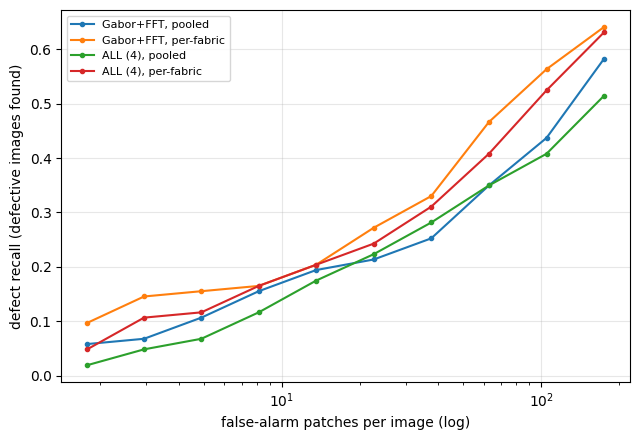

channel/dtype check over all images (channels, dtype): count -> {(1, 'uint8'): 129, (4, 'uint8'): 14}

AUC by FABRIC type (per-fabric model, Gabor+FFT, strict labels):
fabric  defect_patches   AUC
    01             405 0.979
    02              40 0.959
    03             216 0.945
    04              16 0.977

AUC by DEFECT-TYPE code (defect patches of that code vs all clean patches):
defect  defect_patches   AUC
   002              26 0.833
   006              54 0.974
   010             216 0.926
   036             379 0.988

To name the defect types, copy the code -> name table from the AFID paper [Silvestre-Blanes et al., 2019].


In [2]:
# =============================================================================
# WEEK 6 PIPELINE  (run AFTER build_feature_cache.py; reuses its saved files)
# Needs in /kaggle/working: feature_matrix.npy, patch_labels.npy, patch_source.json, defect_index.csv
# Paste each "# %% [CELL ...]" block into its own Kaggle cell and run in order.
#
# What it does
#   W1  fixes the fabric-ID parsing (auto-detects which filename token is the fabric code)
#   W2  recomputes patch/GT overlap so labels can be relaxed (strict >=10% vs any overlap)
#   W3  cross-validated pooled vs PER-FABRIC models, on Gabor+FFT (24 dims) and all 68 dims
#   W4  patch-level AP/AUC tables (strict and relaxed labels) + paired comparisons
#   W5  defect-level evaluation (defect found? false alarms/image), per-fabric thresholds,
#       morphological post-processing, pixel IoU for reference, recall-vs-false-alarm curve
#   W6  extras: channel check, AUC by true fabric type and by true defect code
# =============================================================================


# %% [CELL W1] — Load cache and FIX the fabric / defect-code parsing
import os, json, itertools, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

OUT = os.environ.get("AITEX_OUT", "/kaggle/working")
PATCH, STRIDE = 64, 32               # must match build_feature_cache.py
K_FOLDS, SEEDS = 5, (0, 1, 2)
MIN_TRAIN = 300                      # min clean patches to fit a per-fabric model (else fall back to pooled)
FABRIC_POS = None                    # override: 0/1/2 = which "_"-separated filename token is the fabric code
DEFECT_POS = None                    # override: which token is the defect-type code

try:
    X_all, y_all, src_all = np.asarray(feature_matrix), np.asarray(patch_labels), np.array([str(p) for p in patch_source])
except NameError:
    need = [f"{OUT}/{f}" for f in ("feature_matrix.npy", "patch_labels.npy", "patch_source.json", "defect_index.csv")]
    missing = [p for p in need if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError(
            "Cache files not found: " + ", ".join(os.path.basename(p) for p in missing) + "\n"
            "Kaggle deletes /kaggle/working when the session restarts. FIX: run build_feature_cache.py in THIS session "
            "(about 6 min), then run these cells WITHOUT restarting the kernel. To avoid rebuilding next time, download the "
            "4 files from the Output panel and re-upload them as a dataset, or use Save Version.")
    X_all = np.load(f"{OUT}/feature_matrix.npy"); y_all = np.load(f"{OUT}/patch_labels.npy")
    src_all = np.array(json.load(open(f"{OUT}/patch_source.json")))
N = len(y_all)

def is_normal_src(p):
    lp = p.lower(); return ("nodefect" in lp) or ("no_defect" in lp) or ("good" in lp)
def tokens(p): return os.path.splitext(os.path.basename(p))[0].split("_")

# images in order of appearance, with their patch ranges
_, first_idx, counts = np.unique(src_all, return_index=True, return_counts=True)
order = np.argsort(first_idx); srcs = src_all[first_idx[order]]; starts = first_idx[order]; counts = counts[order]
for s, st, c in zip(srcs, starts, counts): assert (src_all[st:st + c] == s).all(), "patches of an image must be contiguous"
IMG = list(zip(srcs, starts, counts))
def_srcs = [s for s in srcs if not is_normal_src(s)]; nor_srcs = [s for s in srcs if is_normal_src(s)]
print(f"{len(srcs)} images: {len(nor_srcs)} defect-free, {len(def_srcs)} defective | {N} patches")

# ---- show the real filename structure so you can verify the detection ----
print("\nexample filenames:")
for s in nor_srcs[:3] + def_srcs[:5]: print("  ", os.path.relpath(s, os.path.commonpath(list(srcs))))
toks = [tokens(s) for s in def_srcs]
assert all(len(t) == 3 for t in toks), "defective filenames do not have 3 '_' tokens; set FABRIC_POS/DEFECT_POS by hand"
n_unique = [len({t[i] for t in toks}) for i in range(3)]
print("distinct values per filename token (defective images):", dict(enumerate(n_unique)))
if FABRIC_POS is None or DEFECT_POS is None:
    image_pos = int(np.argmax(n_unique)); rest = [i for i in range(3) if i != image_pos]
    FABRIC_POS = min(rest, key=lambda i: n_unique[i]); DEFECT_POS = [i for i in rest if i != FABRIC_POS][0]
print(f"-> token {FABRIC_POS} = FABRIC code ({n_unique[FABRIC_POS]} values), token {DEFECT_POS} = DEFECT-TYPE code "
      f"({n_unique[DEFECT_POS]} values). AFID has 7 fabric types and 12 defect types: CHECK THIS MATCHES.")

def fabric_of(p):
    t = tokens(p)
    return t[FABRIC_POS] if len(t) == 3 else os.path.basename(os.path.dirname(p))
def defect_of(p):
    t = tokens(p); return t[DEFECT_POS] if len(t) == 3 and not is_normal_src(p) else "none"

fab_img = {s: fabric_of(s) for s in srcs}; def_img = {s: defect_of(s) for s in srcs}
fab_patch = np.repeat([fab_img[s] for s in srcs], counts); defc_patch = np.repeat([def_img[s] for s in srcs], counts)
is_def_img = {s: (s in set(def_srcs)) for s in srcs}

tab = pd.crosstab(pd.Series([fab_img[s] for s in srcs], name="fabric"),
                  pd.Series(["defective" if is_def_img[s] else "defect-free" for s in srcs], name="images"))
print("\nimages per fabric type:"); print(tab.to_string())
print("\ndefective images per (defect-type code):"); print(Counter(def_img[s] for s in def_srcs))
print(f"\nfabric types with BOTH defect-free and defective images: {int(((tab > 0).all(axis=1)).sum())} of {len(tab)}")


# %% [CELL W2] — Recompute exact patch/GT overlap (enables relaxed labels + defect-level scoring)
dindex = pd.read_csv(f"{OUT}/defect_index.csv").set_index("path")["mask_path"].to_dict()
ov = np.zeros(N); GRID = {}; MASKS = {}
for s, st, c in IMG:
    im = cv2.imread(s, cv2.IMREAD_GRAYSCALE); H, W = im.shape
    ys = np.arange(0, H - PATCH + 1, STRIDE); xs = np.arange(0, W - PATCH + 1, STRIDE)
    assert len(ys) * len(xs) == c, f"patch grid mismatch for {s}"
    GRID[s] = (len(ys), len(xs), H, W)
    mp = dindex.get(s)
    if is_def_img[s] and isinstance(mp, str):
        m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        if m.shape != im.shape: m = cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST)
        MASKS[s] = m > 0
        ii = cv2.integral(MASKS[s].astype(np.uint8)); Y, Xg = np.meshgrid(ys, xs, indexing="ij")
        tot = ii[Y + PATCH, Xg + PATCH] - ii[Y, Xg + PATCH] - ii[Y + PATCH, Xg] + ii[Y, Xg]
        ov[st:st + c] = (tot / (PATCH * PATCH)).ravel()
clean = ov == 0                                   # truly normal patches (no GT overlap) -> used for fitting
y_strict = (ov >= 0.10).astype(int); y_any = (ov > 0).astype(int)
print(f"agreement with cached strict labels: {(y_strict == y_all).mean()*100:.2f}%")
print(f"defect patches: strict(>=10% overlap)={y_strict.sum()} ({y_strict.mean()*100:.2f}%) | "
      f"relaxed(any overlap)={y_any.sum()} ({y_any.mean()*100:.2f}%)")
print(f"defective images with >=1 strict-defect patch: {sum(y_strict[st:st+c].any() for s,st,c in IMG if is_def_img[s])}/{len(def_srcs)} | "
      f"with >=1 relaxed patch: {sum(y_any[st:st+c].any() for s,st,c in IMG if is_def_img[s])}/{len(def_srcs)}")


# %% [CELL W3] — Cross-validated scoring: pooled vs per-fabric, Gabor+FFT vs all features
COLS = {"Gabor+FFT": np.arange(44, 68), "ALL (4)": np.arange(68)}      # Gabor 44:60, FFT 60:68 (see cache script)

def fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
    return sc, lw, med, mad
def apply(m, X):
    sc, lw, med, mad = m
    return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad     # calibrated on that model's own training scores

def make_folds(seed):
    rng = np.random.RandomState(seed); fold = {}; ctr = 0
    groups = defaultdict(list)
    for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
    for key in sorted(groups):                           # balance fabric x defective across folds
        g = groups[key]; rng.shuffle(g)
        for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
        ctr += len(g)
    return np.repeat([fold[s] for s in srcs], counts)

def run_cv(Xc, mode, seed):
    fold = make_folds(seed); z = np.full(N, np.nan); n_fallback = 0
    for k in range(K_FOLDS):
        te = fold == k; tr = (~te) & clean
        pooled = fit(Xc[tr])
        if mode == "pooled": z[te] = apply(pooled, Xc[te]); continue
        for f in np.unique(fab_patch[te]):
            tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
            if trf.sum() >= MIN_TRAIN: m = fit(Xc[trf])
            else: m = pooled; n_fallback += 1
            z[tef] = apply(m, Xc[tef])
    return fold, z, n_fallback

def fold_metrics(z, fold, y):
    ap, auc = [], []
    for k in range(K_FOLDS):
        te = fold == k
        if 0 < y[te].sum() < te.sum(): ap.append(average_precision_score(y[te], z[te])); auc.append(roc_auc_score(y[te], z[te]))
        else: ap.append(np.nan); auc.append(np.nan)
    return np.array(ap), np.array(auc)

METR = defaultdict(lambda: defaultdict(list)); OOF = {}
for seed in SEEDS:
    for fs, cols in COLS.items():
        Xc = X_all[:, cols]
        for mode in ("pooled", "per-fabric"):
            fold, z, nfb = run_cv(Xc, mode, seed)
            for lab, y in (("strict", y_strict), ("any", y_any)):
                ap, auc = fold_metrics(z, fold, y); METR[(fs, mode)][f"AP_{lab}"] += list(ap); METR[(fs, mode)][f"AUC_{lab}"] += list(auc)
            if seed == SEEDS[0]: OOF[(fs, mode)] = z
            if mode == "per-fabric" and seed == SEEDS[0]: print(f"[{fs}] per-fabric fold/fabric combos that fell back to pooled: {nfb}")
print("done: cross-validated scores computed for", list(OOF))


# %% [CELL W4] — Patch-level results (AP / AUC) and paired comparisons
rows = []
for (fs, mode), d in METR.items():
    rows.append({"features": fs, "model": mode,
                 "AP strict": np.nanmean(d["AP_strict"]), "AUC strict": np.nanmean(d["AUC_strict"]),
                 "AP any-overlap": np.nanmean(d["AP_any"]), "AUC any-overlap": np.nanmean(d["AUC_any"])})
T4 = pd.DataFrame(rows).round(3)
print(f"chance AP: strict={y_strict.mean():.4f}  relaxed={y_any.mean():.4f}")
print(T4.to_string(index=False)); T4.to_csv(f"{OUT}/week6_patch_level.csv", index=False)

def paired(a, b, key="AP_strict"):
    x, y = np.array(METR[a][key]), np.array(METR[b][key]); m = ~np.isnan(x) & ~np.isnan(y); d = x[m] - y[m]
    return f"dAP={d.mean():+.3f}, first wins {np.mean(d > 0)*100:.0f}% of {m.sum()} folds"
print("\nPaired comparisons (strict labels):")
for fs in COLS: print(f"  per-fabric vs pooled [{fs}]: {paired((fs,'per-fabric'),(fs,'pooled'))}")
for mode in ("pooled", "per-fabric"): print(f"  Gabor+FFT vs ALL [{mode}]: {paired(('Gabor+FFT',mode),('ALL (4)',mode))}")


# %% [CELL W5] — Defect-level evaluation, per-fabric thresholds, post-processing
def postprocess(g, post):
    if post == "none": return g
    if post == "open2": return ndi.binary_opening(g, np.ones((2, 2), bool))
    if post == "close3": return ndi.binary_closing(g, np.ones((3, 3), bool))
    return ndi.binary_closing(ndi.binary_opening(g, np.ones((2, 2), bool)), np.ones((3, 3), bool))   # open2+close3
POSTS = ["none", "open2", "close3", "open2+close3"]

def flag(z, q, per_fabric_thr):
    """Flag patches whose score exceeds the (1-q) quantile of CLEAN patches' out-of-fold scores
    (q = target false-positive rate), globally or separately for each fabric."""
    out = np.zeros(N, bool)
    if per_fabric_thr:
        for f in np.unique(fab_patch):
            m = fab_patch == f; out[m] = z[m] > np.quantile(z[m & clean], 1 - q)
    else: out = z > np.quantile(z[clean], 1 - q)
    return out

def evaluate(flagged, post="none", with_iou=True):
    found, ious, fa_all, fa_nor, nor_flagged = [], [], [], [], []
    for s, st, c in IMG:
        R, C, H, W = GRID[s]; g = postprocess(flagged[st:st + c].reshape(R, C), post)
        fa = int((g & (ov[st:st + c].reshape(R, C) == 0)).sum()); fa_all.append(fa)
        if is_def_img[s]:
            found.append(bool((g & (ov[st:st + c].reshape(R, C) > 0)).any()))
            if with_iou:
                pred = np.zeros((H, W), bool)
                for r, cc in zip(*np.nonzero(g)): pred[r*STRIDE:r*STRIDE+PATCH, cc*STRIDE:cc*STRIDE+PATCH] = True
                gt = MASKS[s]; u = (pred | gt).sum(); ious.append((pred & gt).sum() / u if u else np.nan)
        else: fa_nor.append(fa); nor_flagged.append(fa > 0)
    return {"defect_recall": np.mean(found), "false_alarm_patches/img": np.mean(fa_all),
            "normal_imgs_flagged": np.mean(nor_flagged) if nor_flagged else np.nan,
            "pixel_IoU": np.nanmean(ious) if ious else np.nan}

rows = []
for (fs, mode), z in OOF.items():
    for q in (0.01, 0.02, 0.05):
        for pft in (False, True):
            fl = flag(z, q, pft)
            for post in POSTS:
                rows.append({"features": fs, "model": mode, "FPR": q, "threshold": "per-fabric" if pft else "global",
                             "post": post, **evaluate(fl, post)})
T5 = pd.DataFrame(rows); T5.to_csv(f"{OUT}/week6_defect_level.csv", index=False)
pd.set_option("display.width", 200)
print("DEFECT-LEVEL RESULTS, no post-processing, per-fabric threshold (defect_recall = share of defective images where a flagged patch touches the defect):")
print(T5[(T5.post == "none") & (T5.threshold == "per-fabric")].drop(columns=["post", "threshold"]).round(3).to_string(index=False))
print("\nGlobal vs per-fabric threshold (per-fabric model, Gabor+FFT, no post-processing):")
print(T5[(T5.features == "Gabor+FFT") & (T5.model == "per-fabric") & (T5.post == "none")]
      .drop(columns=["features", "model", "post"]).round(3).to_string(index=False))
print("\nEffect of morphological post-processing (per-fabric model, Gabor+FFT, per-fabric threshold):")
print(T5[(T5.features == "Gabor+FFT") & (T5.model == "per-fabric") & (T5.threshold == "per-fabric")]
      .drop(columns=["features", "model", "threshold"]).round(3).to_string(index=False))

# recall vs false-alarm curve (the defect-level analogue of a ROC curve)
plt.figure(figsize=(6.5, 4.5))
for (fs, mode), z in OOF.items():
    pts = [evaluate(flag(z, q, True), "none", with_iou=False) for q in np.geomspace(0.002, 0.2, 10)]
    plt.plot([p["false_alarm_patches/img"] for p in pts], [p["defect_recall"] for p in pts], "o-", ms=3, label=f"{fs}, {mode}")
plt.xscale("log"); plt.xlabel("false-alarm patches per image (log)"); plt.ylabel("defect recall (defective images found)")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/week6_recall_vs_false_alarms.png", dpi=150); plt.show()


# %% [CELL W6] — Extras: channel check, AUC by true fabric type and true defect-type code
cnt = Counter()
for s in srcs:
    a = cv2.imread(s, cv2.IMREAD_UNCHANGED); cnt[(1 if a.ndim == 2 else a.shape[2], str(a.dtype))] += 1
print("channel/dtype check over all images (channels, dtype): count ->", dict(cnt))

z = OOF[("Gabor+FFT", "per-fabric")]
def auc_by(label_arr, tag):
    rows = []
    for v in sorted(set(label_arr)):
        m = (label_arr == v) & (y_strict == 1)
        if m.sum() < 5: continue
        keep = (label_arr == v) | (y_strict == 0) if tag == "defect" else (label_arr == v)
        k = keep & ((y_strict == 1) | clean)
        if len(np.unique(y_strict[k])) == 2: rows.append({tag: v, "defect_patches": int(m.sum()), "AUC": roc_auc_score(y_strict[k], z[k])})
    return pd.DataFrame(rows).round(3)
print("\nAUC by FABRIC type (per-fabric model, Gabor+FFT, strict labels):"); print(auc_by(fab_patch, "fabric").to_string(index=False))
print("\nAUC by DEFECT-TYPE code (defect patches of that code vs all clean patches):"); print(auc_by(defc_patch, "defect").to_string(index=False))
print("\nTo name the defect types, copy the code -> name table from the AFID paper [Silvestre-Blanes et al., 2019].")

In [3]:
# =============================================================================
# PREPROCESSING ABLATION  (does CLAHE + blur actually help?)
# Run AFTER cells W1 and W2 of week6_pipeline.py in the SAME session (it reuses their variables:
# srcs, IMG, counts, src_all, fab_img, fab_patch, is_def_img, ov, clean, GRID, MASKS, y_strict, y_any, N, ...).
# You do NOT need to run W3-W6 first.
#
# For each preprocessing variant it recomputes the 24 Gabor+FFT features on the same patch grid and
# evaluates the same per-fabric model, so the variants differ ONLY in preprocessing.
# Cells: P1 (features) -> P2 (evaluate) -> P3 (before/after figure)
# =============================================================================


# %% [CELL P1] — Recompute Gabor+FFT features for every preprocessing variant
import time
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.filters import gabor_kernel

need = ["srcs", "IMG", "counts", "src_all", "fab_img", "fab_patch", "is_def_img", "ov", "clean",
        "GRID", "MASKS", "y_strict", "y_any", "N", "PATCH", "STRIDE", "K_FOLDS", "SEEDS", "MIN_TRAIN"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run cells W1 and W2 of week6_pipeline.py first (missing: {miss})"

VARIANTS = ["raw", "blur", "median", "clahe", "clahe_blur", "flatten", "flatten_blur"]   # clahe_blur = what we use now
CURRENT = "clahe_blur"

def preprocess(im, v):
    if v == "raw": return im
    if v == "blur": return cv2.GaussianBlur(im, (3, 3), 0)
    if v == "median": return cv2.medianBlur(im, 3)
    if v in ("clahe", "clahe_blur"):
        out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im)
        return cv2.GaussianBlur(out, (3, 3), 0) if v == "clahe_blur" else out
    if v in ("flatten", "flatten_blur"):            # divide by a heavily smoothed copy = remove slow illumination
        bg = cv2.GaussianBlur(im.astype(np.float32), (0, 0), sigmaX=24)
        out = np.clip(im.astype(np.float32) / np.maximum(bg, 1.0) * float(im.mean()), 0, 255).astype(np.uint8)
        return cv2.GaussianBlur(out, (3, 3), 0) if v == "flatten_blur" else out
    raise ValueError(v)

G_KERNELS = [gabor_kernel(f, theta=t).real.astype(np.float32) for f in [0.1, 0.3] for t in [0, np.pi/4, np.pi/2, 3*np.pi/4]]
def fft_feat(p):
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(p.astype(np.float32)))))
    h, w = mag.shape; yy, xx = np.mgrid[0:h, 0:w]; r = np.sqrt((yy - h // 2) ** 2 + (xx - w // 2) ** 2); out = []
    for lo, hi in [(0, 4), (4, 10), (10, 20), (20, max(h, w))]:
        m = (r >= lo) & (r < hi); out += [mag[m].mean() if m.any() else 0.0, mag[m].std() if m.any() else 0.0]
    return np.array(out)

def features_for_image(path, v):
    im0 = cv2.imread(path, cv2.IMREAD_GRAYSCALE); im = preprocess(im0, v); f = im.astype(np.float32) / 255.0
    maps = [cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101) for k in G_KERNELS]
    F = []
    for y in range(0, im.shape[0] - PATCH + 1, STRIDE):
        for x in range(0, im.shape[1] - PATCH + 1, STRIDE):
            g = np.array([s for m in maps for s in (float(m[y:y+PATCH, x:x+PATCH].mean()), float(m[y:y+PATCH, x:x+PATCH].var()))])
            F.append(np.concatenate([g, fft_feat(im[y:y+PATCH, x:x+PATCH])]))
    colprof = im.astype(np.float32).mean(0)
    return np.array(F, np.float32), float(im.mean()), float(colprof.std() / (colprof.mean() + 1e-9))

FEATS, ILLUM = {}, {}
for v in VARIANTS:
    t0 = time.time()
    res = Parallel(n_jobs=-1)(delayed(features_for_image)(s, v) for s, _, _ in IMG)
    FEATS[v] = np.vstack([r[0] for r in res]); assert len(FEATS[v]) == N
    means = pd.Series([r[1] for r in res], index=[s for s, _, _ in IMG]); cvs = np.array([r[2] for r in res])
    fab = pd.Series([fab_img[s] for s, _, _ in IMG], index=means.index)
    between = np.mean([means[fab == f].std() / means[fab == f].mean() for f in fab.unique() if (fab == f).sum() > 1])
    ILLUM[v] = {"between_image_brightness_CV": between, "along_strip_gradient_CV": float(cvs.mean())}
    print(f"{v:13s} features {FEATS[v].shape}  ({time.time()-t0:.0f}s)")

# unit test: the 'current' variant must reproduce the cached Gabor+FFT columns (44:68)
try:
    diff = np.abs(FEATS[CURRENT] - X_all[:, 44:68]).max()
    print(f"\nSANITY: max |recomputed - cached| for '{CURRENT}' = {diff:.2e}  (should be ~0)")
except NameError:
    pass




raw           features (127057, 24)  (90s)
blur          features (127057, 24)  (89s)
median        features (127057, 24)  (86s)
clahe         features (127057, 24)  (89s)
clahe_blur    features (127057, 24)  (91s)
flatten       features (127057, 24)  (93s)
flatten_blur  features (127057, 24)  (93s)

SANITY: max |recomputed - cached| for 'clahe_blur' = 0.00e+00  (should be ~0)


evaluated raw
evaluated blur
evaluated median
evaluated clahe
evaluated clahe_blur
evaluated flatten
evaluated flatten_blur

chance AP: relaxed=0.0164  strict=0.0053   (per-fabric Gabor+FFT model, image-level CV)
               variant  AP relaxed  AUC relaxed  AP strict  AUC strict  recall@1%  FA/img@1%  normal flagged@1%  recall@5%  illum CV between imgs  illum CV along strip
                   raw       0.102        0.789      0.103       0.901      0.136      8.762              0.600      0.311                  0.022                 0.317
                  blur       0.094        0.785      0.094       0.891      0.136      8.762              0.525      0.330                  0.022                 0.317
                median       0.086        0.789      0.079       0.888      0.136      8.762              0.525      0.330                  0.023                 0.320
                 clahe       0.144        0.800      0.164       0.929      0.165      8.762              0.625    

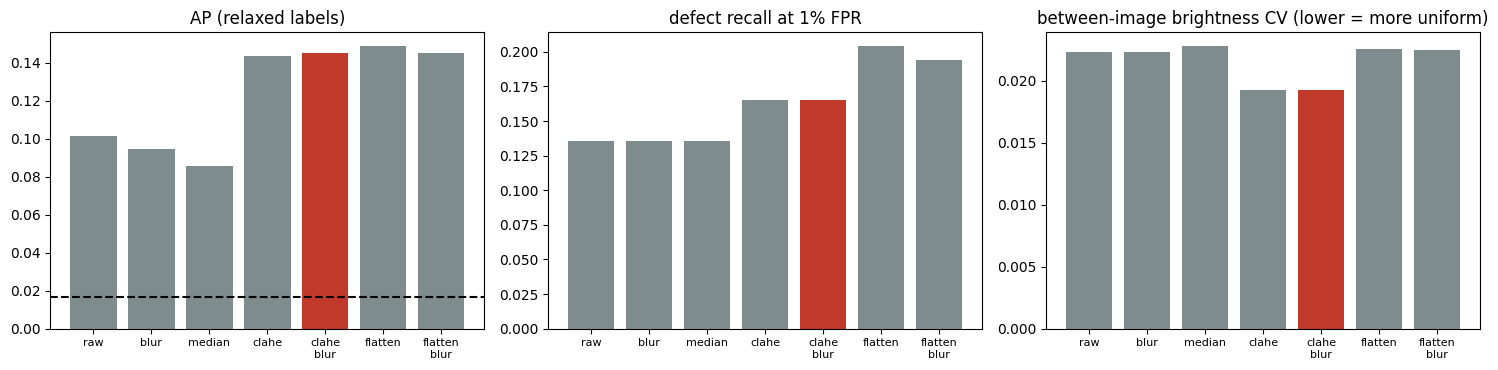

In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from collections import defaultdict

def _fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
    return sc, lw, med, mad
def _apply(m, X):
    sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
def _folds(seed):
    rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
    for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
    for key in sorted(groups):
        g = groups[key]; rng.shuffle(g)
        for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
        ctr += len(g)
    return np.repeat([fold[s] for s in srcs], counts)
def _cv(Xc, seed):
    fold = _folds(seed); z = np.full(N, np.nan)
    for k in range(K_FOLDS):
        te = fold == k; tr = (~te) & clean; pooled = _fit(Xc[tr])
        for f in np.unique(fab_patch[te]):
            tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
            z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])
    return fold, z
def _fold_metric(z, fold, y):
    ap, auc = [], []
    for k in range(K_FOLDS):
        te = fold == k
        if 0 < y[te].sum() < te.sum(): ap.append(average_precision_score(y[te], z[te])); auc.append(roc_auc_score(y[te], z[te]))
        else: ap.append(np.nan); auc.append(np.nan)
    return ap, auc
def _defect_level(z, q):
    flagged = np.zeros(N, bool)
    for f in np.unique(fab_patch):
        m = fab_patch == f; flagged[m] = z[m] > np.quantile(z[m & clean], 1 - q)
    found, fa, nor = [], [], []
    for s, st, c in IMG:
        R, C, _, _ = GRID[s]; g = flagged[st:st + c].reshape(R, C); o = ov[st:st + c].reshape(R, C)
        n_fa = int((g & (o == 0)).sum()); fa.append(n_fa)
        if is_def_img[s]: found.append(bool((g & (o > 0)).any()))
        else: nor.append(n_fa > 0)
    return np.mean(found), np.mean(fa), (np.mean(nor) if nor else np.nan)

PER = {}; rows = []
for v in VARIANTS:
    m = defaultdict(list); z0 = None
    for seed in SEEDS:
        fold, z = _cv(FEATS[v], seed)
        for lab, y in (("strict", y_strict), ("any", y_any)):
            ap, auc = _fold_metric(z, fold, y); m[f"AP_{lab}"] += ap; m[f"AUC_{lab}"] += auc
        if z0 is None: z0 = z
    PER[v] = m; r1, f1, n1 = _defect_level(z0, 0.01); r5, f5, n5 = _defect_level(z0, 0.05)
    rows.append({"variant": v + ("  <- current" if v == CURRENT else ""),
                 "AP relaxed": np.nanmean(m["AP_any"]), "AUC relaxed": np.nanmean(m["AUC_any"]),
                 "AP strict": np.nanmean(m["AP_strict"]), "AUC strict": np.nanmean(m["AUC_strict"]),
                 "recall@1%": r1, "FA/img@1%": f1, "normal flagged@1%": n1, "recall@5%": r5,
                 "illum CV between imgs": ILLUM[v]["between_image_brightness_CV"],
                 "illum CV along strip": ILLUM[v]["along_strip_gradient_CV"]})
    print(f"evaluated {v}")

TB = pd.DataFrame(rows).round(3); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(f"\nchance AP: relaxed={y_any.mean():.4f}  strict={y_strict.mean():.4f}   (per-fabric Gabor+FFT model, image-level CV)")
print(TB.to_string(index=False)); TB.to_csv(f"{OUT}/preprocessing_ablation.csv", index=False)

print("\nPaired comparison vs current preprocessing (relaxed-label AP, per fold):")
base = np.array(PER[CURRENT]["AP_any"])
for v in VARIANTS:
    if v == CURRENT: continue
    x = np.array(PER[v]["AP_any"]); k = ~np.isnan(x) & ~np.isnan(base); d = x[k] - base[k]
    print(f"  {v:13s} dAP = {d.mean():+.4f}   better than current in {np.mean(d > 0)*100:.0f}% of {k.sum()} folds")
best = max(VARIANTS, key=lambda v: np.nanmean(PER[v]["AP_any"]))
print(f"\nBest variant by relaxed-label AP: {best}.  If its paired advantage over '{CURRENT}' is small (<~60% of folds), "
      f"say the variants are comparable and keep the simplest one.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8)); lab = [v.replace("_", "\n") for v in VARIANTS]
cols = ["#c0392b" if v == CURRENT else "#7f8c8d" for v in VARIANTS]
ax[0].bar(lab, [np.nanmean(PER[v]["AP_any"]) for v in VARIANTS], color=cols); ax[0].axhline(y_any.mean(), ls="--", c="k"); ax[0].set_title("AP (relaxed labels)")
ax[1].bar(lab, [r["recall@1%"] for r in rows], color=cols); ax[1].set_title("defect recall at 1% FPR")
ax[2].bar(lab, [ILLUM[v]["between_image_brightness_CV"] for v in VARIANTS], color=cols); ax[2].set_title("between-image brightness CV (lower = more uniform)")
for a in ax: a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/preprocessing_ablation.png", dpi=150);
plt.show()

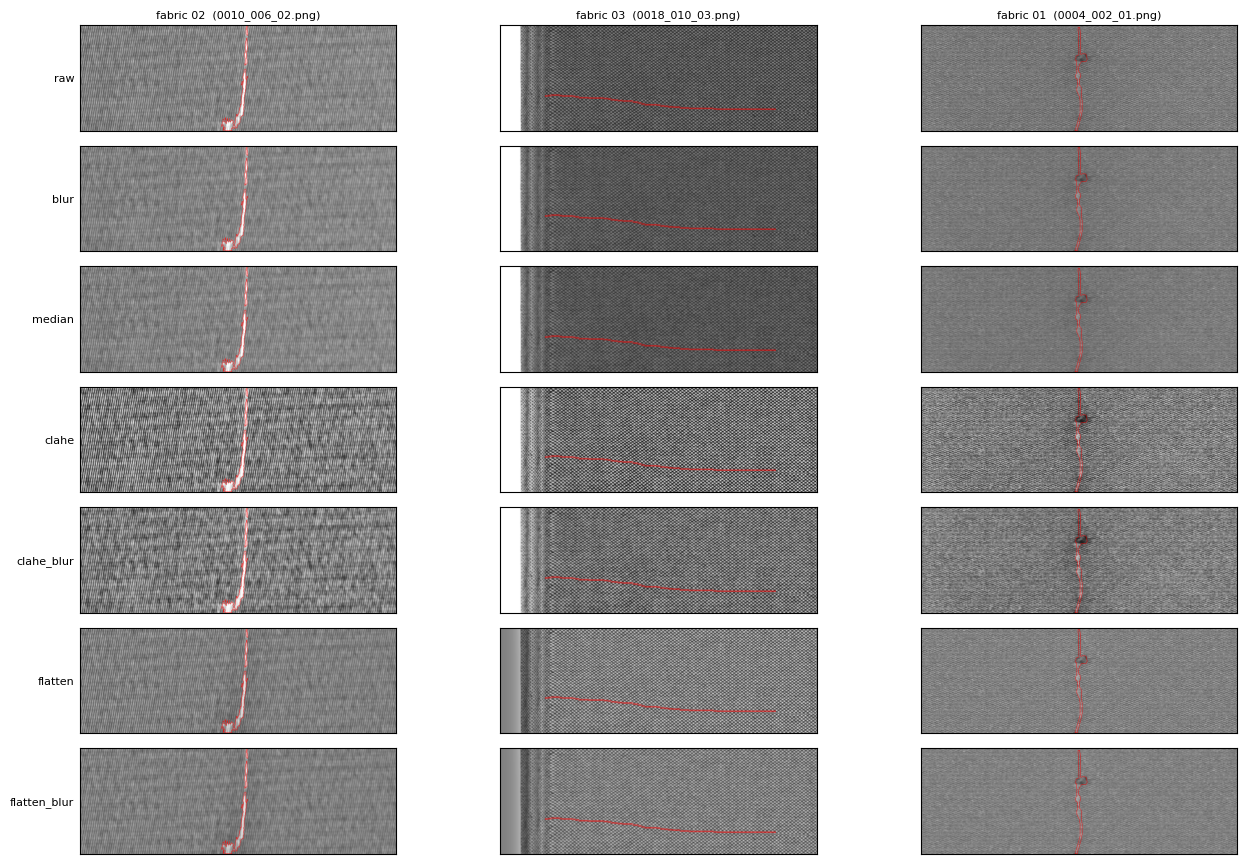

In [4]:



# %% [CELL P3] — Before/after figure on real defects (red outline = ground truth)
fabs = sorted({fab_img[s] for s in MASKS}, key=lambda f: -sum(fab_img[s] == f for s in MASKS))[:3]
picks = [next(s for s in MASKS if fab_img[s] == f) for f in fabs]
fig, axes = plt.subplots(len(VARIANTS), len(picks), figsize=(4.6 * len(picks), 1.25 * len(VARIANTS)))
axes = np.atleast_2d(axes)
for j, s in enumerate(picks):
    im0 = cv2.imread(s, cv2.IMREAD_GRAYSCALE); H, W = im0.shape; wd = min(768, W)
    ys, xs = np.nonzero(MASKS[s]); cx = int(xs.mean()) if len(xs) else W // 2; x0 = int(np.clip(cx - wd // 2, 0, W - wd))
    cnt, _ = cv2.findContours(MASKS[s][:, x0:x0 + wd].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for i, v in enumerate(VARIANTS):
        crop = cv2.cvtColor(preprocess(im0, v)[:, x0:x0 + wd], cv2.COLOR_GRAY2RGB); cv2.drawContours(crop, cnt, -1, (255, 0, 0), 1)
        axes[i, j].imshow(crop); axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if j == 0: axes[i, j].set_ylabel(v, rotation=0, ha="right", va="center", fontsize=8)
        if i == 0: axes[i, j].set_title(f"fabric {fab_img[s]}  ({os.path.basename(s)})", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/preprocessing_before_after.png", dpi=150); plt.show()

In [7]:



# %% [CELL P4] — Image-level bootstrap: is the winning preprocessing really better than the current one?
# (Fold win-rates over 3 seeds are not independent, so we also resample IMAGES, which is the honest unit.)
cand = ["clahe_blur", "flatten", "flatten_blur"]
Z = {v: _cv(FEATS[v], SEEDS[0])[1] for v in cand}
sl = {s: np.arange(st, st + c) for s, st, c in IMG}
rng = np.random.RandomState(0); deltas = {v: [] for v in cand[1:]}
for _ in range(300):
    pick = rng.choice(len(IMG), len(IMG), replace=True)
    ii = np.concatenate([sl[IMG[p][0]] for p in pick])
    if y_any[ii].sum() == 0: continue
    base = average_precision_score(y_any[ii], Z["clahe_blur"][ii])
    for v in cand[1:]: deltas[v].append(average_precision_score(y_any[ii], Z[v][ii]) - base)
print("Bootstrap over images (relaxed-label AP, 300 resamples, seed-0 out-of-fold scores):")
for v, d in deltas.items():
    lo, md, hi = np.percentile(d, [2.5, 50, 97.5])
    print(f"  {v:13s} dAP vs clahe_blur: median {md:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]"
          + ("  -> CI excludes 0" if lo > 0 or hi < 0 else "  -> not distinguishable from 0"))

Bootstrap over images (relaxed-label AP, 300 resamples, seed-0 out-of-fold scores):
  flatten       dAP vs clahe_blur: median +0.0164, 95% CI [-0.0237, +0.0855]  -> not distinguishable from 0
  flatten_blur  dAP vs clahe_blur: median +0.0297, 95% CI [-0.0238, +0.0890]  -> not distinguishable from 0


EXCLUDED (no patch overlaps the mask; name, mask area % of image): [('0106_010_03.png', 0.0)]
defective images: 102 | found at 1% FPR: 0.167 | found at 5% FPR: 0.353

Detection by defect-type code (recall = defective images where a flagged patch touches the defect):
        images  recall_1pct  recall_5pct  mean_gt_area_pct
defect                                                    
019         38        0.000        0.132             0.003
030         13        0.000        0.154             0.015
002          9        0.000        0.111             0.100
010          9        0.333        0.778             2.300
022          9        0.111        0.667             0.029
006          8        1.000        1.000             0.191
025          5        0.000        0.000             0.002
023          5        0.200        0.600             0.087
016          3        1.000        1.000             0.078
027          1        0.000        0.000             0.027
029          1        0.0

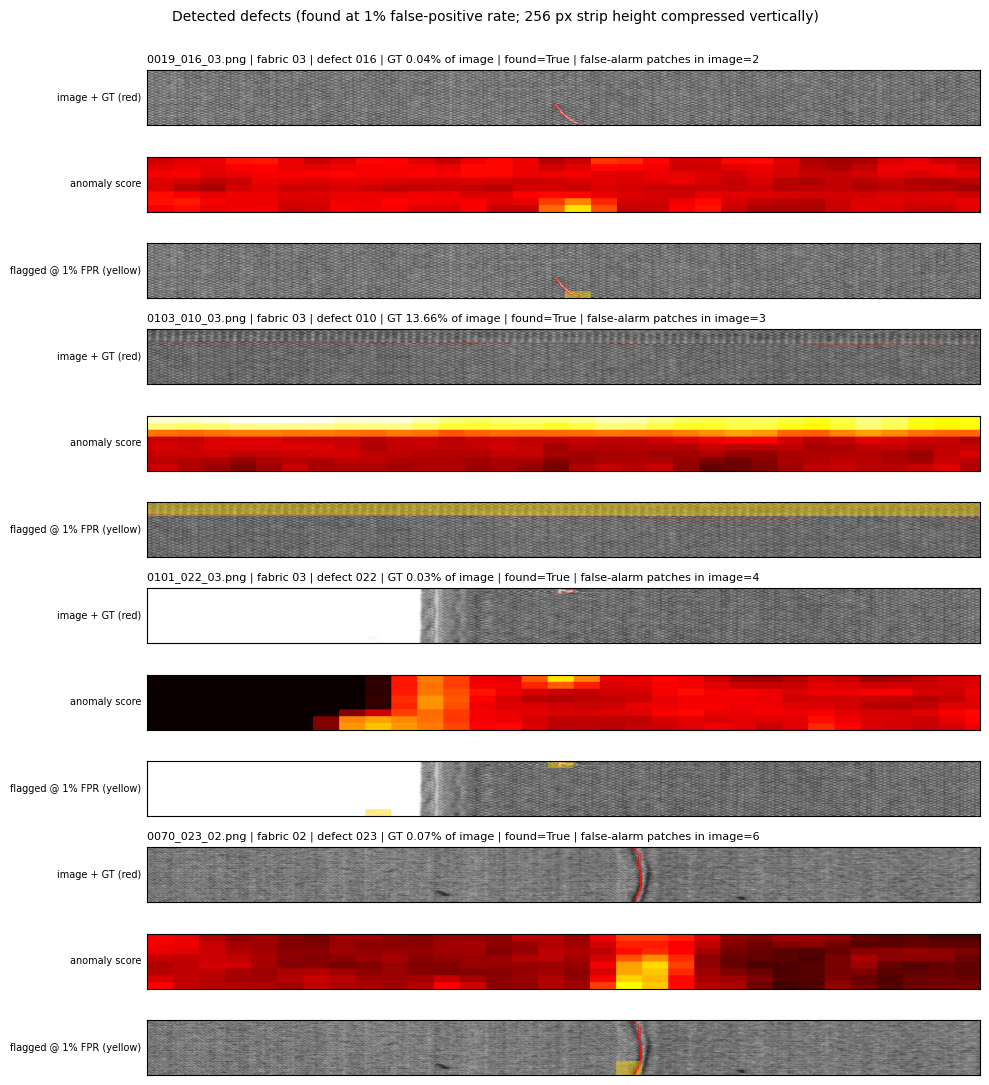

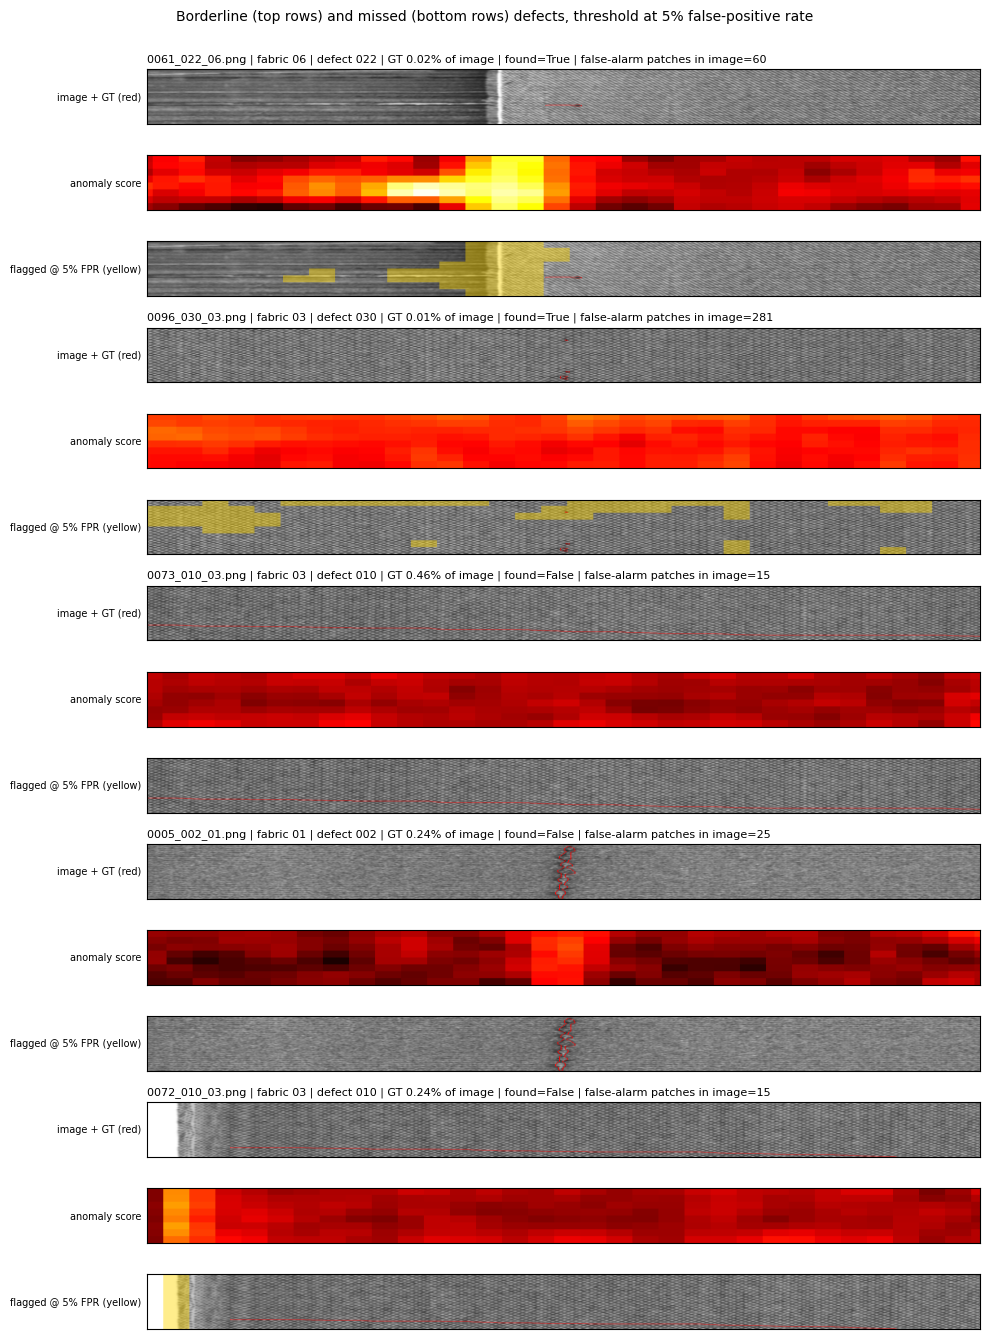

saved qual_detected.png, qual_borderline_missed.png, qualitative_per_image.csv, qualitative_by_defect_type.csv in /kaggle/working


In [8]:
# =============================================================================
# QUALITATIVE RESULTS — what does the pipeline actually find and miss?
# Run AFTER cells W1 and W2 of week6_pipeline.py in the SAME session (needs X_all, srcs, IMG, counts,
# fab_img, fab_patch, is_def_img, def_img, ov, clean, GRID, MASKS, SEEDS, K_FOLDS, PATCH, STRIDE, N, OUT).
# Uses the final configuration: CLAHE+blur features (cached), Gabor+FFT (24 dims), per-fabric model + per-fabric threshold.
#
# Cells: Q1 (scores + per-image outcomes + table by defect type)  ->  Q2 (example figures)
# Examples are chosen by FIXED RULES (printed), not hand-picked: cleanest detections, borderline, and biggest misses.
# =============================================================================

# Q1 — Scores, thresholds, per-image outcomes (fixed: skips images whose mask no patch overlaps)
import os
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from collections import defaultdict
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

need = ["X_all", "srcs", "IMG", "counts", "fab_img", "fab_patch", "is_def_img", "def_img", "ov", "clean",
        "GRID", "MASKS", "SEEDS", "K_FOLDS", "PATCH", "STRIDE", "N", "OUT", "MIN_TRAIN"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run cells W1 and W2 of week6_pipeline.py first (missing: {miss})"

Xc = X_all[:, 44:68]                       # Gabor (44:60) + FFT (60:68)
def _fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
    return sc, lw, med, mad
def _apply(m, X):
    sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
def _folds(seed):
    rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
    for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
    for key in sorted(groups):
        g = groups[key]; rng.shuffle(g)
        for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
        ctr += len(g)
    return np.repeat([fold[s] for s in srcs], counts)

fold = _folds(SEEDS[0]); z = np.full(N, np.nan)           # out-of-fold scores: every image is scored by a model that never saw it
for k in range(K_FOLDS):
    te = fold == k; tr = (~te) & clean; pooled = _fit(Xc[tr])
    for f in np.unique(fab_patch[te]):
        tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
        z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])

THR = {q: {f: np.quantile(z[(fab_patch == f) & clean], 1 - q) for f in np.unique(fab_patch)} for q in (0.01, 0.05)}
def flagged_of(s, st, c, q): return z[st:st + c] > THR[q][fab_img[s]]

rows = []; skipped = []
for s, st, c in IMG:
    if not is_def_img[s] or s not in MASKS: continue
    R, C, H, W = GRID[s]; o = ov[st:st + c]
    if not (o > 0).any():                       # empty / unreachable mask: nothing to detect, exclude and report
        skipped.append((os.path.basename(s), float(MASKS[s].mean() * 100))); continue
    r = {"path": s, "image": os.path.basename(s), "fabric": fab_img[s], "defect": def_img[s], "gt_area_pct": MASKS[s].mean() * 100}
    for q, tag in ((0.01, "1"), (0.05, "5")):
        fl = flagged_of(s, st, c, q)
        r[f"found@{tag}%"] = bool((fl & (o > 0)).any()); r[f"FA@{tag}%"] = int((fl & (o == 0)).sum())
        r[f"hit_patches@{tag}%"] = int((fl & (o > 0)).sum()); r[f"margin@{tag}%"] = float(z[st:st + c][o > 0].max() - THR[q][fab_img[s]])
    rows.append(r)
if skipped: print("EXCLUDED (no patch overlaps the mask; name, mask area % of image):", skipped)
DF = pd.DataFrame(rows); DF.to_csv(f"{OUT}/qualitative_per_image.csv", index=False)
print(f"defective images: {len(DF)} | found at 1% FPR: {DF['found@1%'].mean():.3f} | found at 5% FPR: {DF['found@5%'].mean():.3f}")

T = DF.groupby("defect").agg(images=("image", "count"), recall_1pct=("found@1%", "mean"), recall_5pct=("found@5%", "mean"),
                             mean_gt_area_pct=("gt_area_pct", "mean")).round(3).sort_values("images", ascending=False)
print("\nDetection by defect-type code (recall = defective images where a flagged patch touches the defect):")
print(T.to_string()); T.to_csv(f"{OUT}/qualitative_by_defect_type.csv")
print("\nDetection by fabric type:")
print(DF.groupby("fabric").agg(images=("image", "count"), recall_1pct=("found@1%", "mean"), recall_5pct=("found@5%", "mean")).round(3).to_string())




# %% [CELL Q2] — Example figures (rules for choosing examples are printed below)
det = DF[DF["found@1%"]].sort_values(["FA@1%", "hit_patches@1%"], ascending=[True, False]).head(4)
part = DF[(~DF["found@1%"]) & DF["found@5%"]].sort_values("margin@5%", ascending=False).head(2)
mis = DF[~DF["found@5%"]].sort_values("gt_area_pct", ascending=False).head(3)
print("RULES: detected = found at 1% FPR, fewest false alarms; borderline = found only at 5% FPR, largest score margin;"
      " missed = NOT found even at 5% FPR, largest defect area.")
print(f"candidates: detected={int(DF['found@1%'].sum())}  borderline={int(((~DF['found@1%']) & DF['found@5%']).sum())}  "
      f"missed={int((~DF['found@5%']).sum())}")

def paint(s, st, c, values, binary=False):
    R, C, H, W = GRID[s]; acc = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); k = 0
    for r in range(R):
        for cc in range(C):
            y, x = r * STRIDE, cc * STRIDE; acc[y:y+PATCH, x:x+PATCH] += values[k]; cnt[y:y+PATCH, x:x+PATCH] += 1; k += 1
    cnt[cnt == 0] = 1; return acc / cnt

def draw(df, q, fname, title):
    if len(df) == 0: print("no examples for", title); return
    n = len(df); fig, axes = plt.subplots(3 * n, 1, figsize=(10, 0.85 * 3 * n + 0.6))
    axes = np.atleast_1d(axes); vmax = float(np.nanpercentile(z, 99.7))
    for e, (_, r) in enumerate(df.iterrows()):
        s = r["path"]; st, c = next((a, b) for p, a, b in IMG if p == s); R, C, H, W = GRID[s]
        im = cv2.imread(s, cv2.IMREAD_GRAYSCALE); im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
        heat = paint(s, st, c, z[st:st + c]); fl = paint(s, st, c, flagged_of(s, st, c, q).astype(np.float32)) > 0.5
        ys, xs = np.nonzero(MASKS[s]); cx = int(xs.mean()) if len(xs) else W // 2; wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd))
        sl = (slice(None), slice(x0, x0 + wd)); cnt_, _ = cv2.findContours(MASKS[s][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB); a = rgb.copy(); a[fl[sl]] = (0.55 * a[fl[sl]] + 0.45 * np.array([255, 215, 0])).astype(np.uint8)
        for panel in (rgb, a): cv2.drawContours(panel, cnt_, -1, (255, 0, 0), 1)
        ax = axes[3 * e:3 * e + 3]
        ax[0].imshow(rgb, aspect="auto"); ax[1].imshow(heat[sl], cmap="hot", vmin=-2, vmax=vmax, aspect="auto"); ax[2].imshow(a, aspect="auto")
        for k, lab in enumerate(["image + GT (red)", "anomaly score", f"flagged @ {int(q*100)}% FPR (yellow)"]):
            ax[k].set_yticks([]); ax[k].set_xticks([]); ax[k].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=7)
        ax[0].set_title(f"{r['image']} | fabric {r['fabric']} | defect {r['defect']} | GT {r['gt_area_pct']:.2f}% of image | "
                        f"found={r[f'found@{int(q*100)}%']} | false-alarm patches in image={r[f'FA@{int(q*100)}%']}", fontsize=8, loc="left")
    fig.suptitle(title, fontsize=10, y=1.0); plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=160, bbox_inches="tight"); plt.show()

draw(det, 0.01, "qual_detected.png", "Detected defects (found at 1% false-positive rate; 256 px strip height compressed vertically)")
draw(pd.concat([part, mis]), 0.05, "qual_borderline_missed.png",
     "Borderline (top rows) and missed (bottom rows) defects, threshold at 5% false-positive rate")
print("saved qual_detected.png, qual_borderline_missed.png, qualitative_per_image.csv, qualitative_by_defect_type.csv in", OUT)

In [9]:
# Q3 — Does the highest-scoring patch of an image sit ON the defect?
from scipy.stats import hypergeom
rows = []
for s, st, c in IMG:
    if not is_def_img[s] or s not in MASKS: continue
    o = ov[st:st + c] > 0
    if not o.any(): continue
    order = np.argsort(-z[st:st + c]); hit = o[order]; n, m = c, int(o.sum())
    rows.append({"image": os.path.basename(s), "defect": def_img[s], "fabric": fab_img[s], "area_pct": MASKS[s].mean() * 100,
                 **{f"top{k}": bool(hit[:k].any()) for k in (1, 3, 10)},
                 **{f"chance_top{k}": 1 - hypergeom.pmf(0, n, m, k) for k in (1, 3, 10)}})
P = pd.DataFrame(rows); P.to_csv(f"{OUT}/qualitative_pointing.csv", index=False)
print(f"Images evaluated: {len(P)}.  Hit = a top-k scoring patch of the image overlaps the ground-truth defect.")
print(f"{'':22s}{'top-1':>8s}{'top-3':>8s}{'top-10':>8s}")
print(f"{'pipeline':22s}" + "".join(f"{P[f'top{k}'].mean():8.3f}" for k in (1, 3, 10)))
print(f"{'random patches':22s}" + "".join(f"{P[f'chance_top{k}'].mean():8.3f}" for k in (1, 3, 10)))
P["size"] = pd.cut(P["area_pct"], [0, 0.01, 0.1, 1000], labels=["<0.01% of image", "0.01-0.1%", ">0.1%"])
print("\nBy defect size (hit rate of top-10 patches vs random):")
print(P.groupby("size").apply(lambda d: pd.Series({"images": len(d), "top-1": d["top1"].mean(), "top-10": d["top10"].mean(),
                                                   "random top-10": d["chance_top10"].mean()})).round(3).to_string())

Images evaluated: 102.  Hit = a top-k scoring patch of the image overlaps the ground-truth defect.
                         top-1   top-3  top-10
pipeline                 0.108   0.137   0.216
random patches           0.023   0.058   0.141

By defect size (hit rate of top-10 patches vs random):
                 images  top-1  top-10  random top-10
size                                                 
<0.01% of image    51.0  0.000   0.020          0.044
0.01-0.1%          27.0  0.111   0.222          0.109
>0.1%              24.0  0.333   0.625          0.383


In [1]:
# =============================================================================
# build_feature_cache.py  —  run this ONCE in a fresh Kaggle cell, BEFORE
# descriptor_selection_and_diagnostics.py.
# It rebuilds: patches -> 68-dim features (GLCM 16 / LBP 28 / Gabor 16 / FFT 8),
# labels, and the image each patch came from, then saves them to /kaggle/working
# so the next script can load them even after a kernel restart.
# =============================================================================
import os, re, glob, json, random, time
import numpy as np, pandas as pd, cv2
from joblib import Parallel, delayed
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.filters import gabor_kernel
from scipy import ndimage as ndi

# ---------------- settings ----------------
DATASET_ROOT = os.environ.get("AITEX_ROOT")      # e.g. "/kaggle/input/aitex-fabric-image-database"; None = auto-pick
INPUT_ROOT   = os.environ.get("AITEX_IN", "/kaggle/input")
OUT          = os.environ.get("AITEX_OUT", "/kaggle/working")
MAX_NORMAL_IMAGES = None     # None = ALL defect-free images (141; recommended). 40 = old default, slower is ~10 min total
MAX_DEFECT_IMAGES = None     # None = all mask-matched defective images (recommended: more defect patches)
PATCH, STRIDE, OVERLAP_THR = 64, 32, 0.10
SEED = 42
os.makedirs(OUT, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

# ---------------- 1. find dataset + index files ----------------
def list_images(root):
    return [f for f in glob.glob(os.path.join(root, "**", "*.*"), recursive=True) if f.lower().endswith(IMG_EXT)]

if DATASET_ROOT is None:
    cands = [d for d in glob.glob(os.path.join(INPUT_ROOT, "*")) if os.path.isdir(d)]
    assert cands, f"nothing under {INPUT_ROOT}: add the AITEX dataset to this notebook (Add Input)"
    ds_counts = {d: len(list_images(d)) for d in cands}   # (renamed: 'counts' is used by week6_pipeline.py)
    print("datasets found:", ds_counts)
    DATASET_ROOT = max(ds_counts, key=ds_counts.get)
print("Using DATASET_ROOT =", DATASET_ROOT)
all_images = sorted(list_images(DATASET_ROOT))      # sorted => same image order (and same sample) in every session

def classify_path(p):
    lp = p.lower()
    if "mask" in lp: return "mask"
    if "nodefect" in lp or "no_defect" in lp or "good" in lp: return "normal"
    if "defect" in lp: return "defect"
    return "unknown"

buckets = {"normal": [], "defect": [], "mask": [], "unknown": []}
for f in all_images: buckets[classify_path(f)].append(f)
print({k: len(v) for k, v in buckets.items()})
assert buckets["normal"] and buckets["defect"] and buckets["mask"], "could not find normal/defect/mask folders - check folder names"

mask_lookup = {os.path.splitext(os.path.basename(m))[0]: m for m in buckets["mask"]}
def find_mask_for(p):
    stem = os.path.splitext(os.path.basename(p))[0]
    for cand in (stem, stem + "_mask", stem + "-mask", stem + "_gt", stem.replace("_mask", "").replace("-mask", "")):
        if cand in mask_lookup: return mask_lookup[cand]
    return None

def parse_name(f):
    parts = re.split(r"[_\-]", os.path.splitext(os.path.basename(f))[0])
    return parts[0], (parts[-1] if len(parts) > 2 else "unknown")

df_defects = pd.DataFrame([{"path": f, "fabric_id": parse_name(f)[0], "defect_code": parse_name(f)[1],
                            "mask_path": find_mask_for(f)} for f in sorted(buckets["defect"])])
df_normal = pd.DataFrame([{"path": f, "fabric_id": parse_name(f)[0]} for f in sorted(buckets["normal"])])
print(f"mask-matched defective images: {df_defects['mask_path'].notna().sum()}/{len(df_defects)}")
df_defects.to_csv(f"{OUT}/defect_index.csv", index=False); df_normal.to_csv(f"{OUT}/normal_index.csv", index=False)

matched = df_defects.dropna(subset=["mask_path"])
if MAX_DEFECT_IMAGES: matched = matched.sample(min(MAX_DEFECT_IMAGES, len(matched)), random_state=SEED)
normal_sel = df_normal.sample(min(MAX_NORMAL_IMAGES, len(df_normal)), random_state=SEED) if MAX_NORMAL_IMAGES else df_normal

# ---------------- 2. descriptors (same as Cells 9-12, except Gabor is computed per image, see note) ----------------
GLCM_D, GLCM_A, GLCM_P = [1, 3], [0, np.pi/4, np.pi/2, 3*np.pi/4], ["contrast", "correlation", "energy", "homogeneity"]
LBP_CFG = [(8, 1), (16, 2)]
G_KERNELS = [gabor_kernel(f, theta=t).real.astype(np.float32) for f in [0.1, 0.3] for t in [0, np.pi/4, np.pi/2, 3*np.pi/4]]

def glcm_features(patch, levels=32):
    q = np.clip((patch.astype(np.float32) / 256.0 * levels).astype(np.uint8), 0, levels - 1)
    g = graycomatrix(q, distances=GLCM_D, angles=GLCM_A, levels=levels, symmetric=True, normed=True)
    out = []
    for prop in GLCM_P:
        v = graycoprops(g, prop); out += list(v.mean(1)) + list(v.std(1))
    return np.array(out)                                   # 16

def lbp_features(patch):
    out = []
    for P, R in LBP_CFG:
        l = local_binary_pattern(patch, P, R, method="uniform")
        h, _ = np.histogram(l.ravel(), bins=P + 2, range=(0, P + 2), density=True); out += list(h)
    return np.array(out)                                   # 28

def gabor_maps(im):
    """Filter the WHOLE image once per kernel (fast, no wrap-around artefacts at patch borders);
    the patch descriptor is then the mean/variance of the response inside the patch window.
    NOTE: slightly different from Cell 11 (which convolved each 64x64 patch separately, ~65 ms/patch),
    so do not mix this feature_matrix with one built by the old cells."""
    f = im.astype(np.float32) / 255.0
    return [cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101) for k in G_KERNELS]

def gabor_features(maps, y, x):
    out = []
    for r in maps:
        w = r[y:y+PATCH, x:x+PATCH]; out += [float(w.mean()), float(w.var())]
    return np.array(out)                                   # 16

def fft_features(patch):
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(patch.astype(np.float32)))))
    h, w = mag.shape; yy, xx = np.mgrid[0:h, 0:w]; r = np.sqrt((yy - h//2) ** 2 + (xx - w//2) ** 2)
    out = []
    for lo, hi in [(0, 4), (4, 10), (10, 20), (20, max(h, w))]:
        m = (r >= lo) & (r < hi); out += [mag[m].mean() if m.any() else 0.0, mag[m].std() if m.any() else 0.0]
    return np.array(out)                                   # 8

def combined_features(p, maps, y, x):
    return np.concatenate([glcm_features(p), lbp_features(p), gabor_features(maps, y, x), fft_features(p)])

# ---------------- 3. per-image worker ----------------
def process_image(path, mask_path):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if im is None: return None
    im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
    mask = None
    if mask_path:
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is not None and mask.shape != im.shape:
            mask = cv2.resize(mask, (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    maps = gabor_maps(im)
    F, L = [], []
    for y in range(0, im.shape[0] - PATCH + 1, STRIDE):
        for x in range(0, im.shape[1] - PATCH + 1, STRIDE):
            F.append(combined_features(im[y:y+PATCH, x:x+PATCH], maps, y, x))
            L.append(int((mask[y:y+PATCH, x:x+PATCH] > 0).mean() >= OVERLAP_THR) if mask is not None else 0)
    return np.array(F, np.float32), np.array(L, np.int8)

jobs = [(r.path, None) for r in normal_sel.itertuples()] + [(r.path, r.mask_path) for r in matched.itertuples()]
print(f"processing {len(jobs)} images ({len(normal_sel)} normal + {len(matched)} defective) on all cores...")
t0 = time.time()
res = Parallel(n_jobs=-1, verbose=5)(delayed(process_image)(p, m) for p, m in jobs)

feats, labels, sources = [], [], []
for (p, _), r in zip(jobs, res):
    if r is None: print("unreadable:", p); continue
    feats.append(r[0]); labels.append(r[1]); sources += [p] * len(r[1])
feature_matrix = np.vstack(feats); patch_labels = np.concatenate(labels).astype(int); patch_source = sources

# ---------------- 4. save + report ----------------
np.save(f"{OUT}/feature_matrix.npy", feature_matrix); np.save(f"{OUT}/patch_labels.npy", patch_labels)
json.dump(patch_source, open(f"{OUT}/patch_source.json", "w"))
print(f"\ndone in {time.time()-t0:.0f}s | feature_matrix {feature_matrix.shape} | defect patches {patch_labels.sum()} "
      f"({patch_labels.mean()*100:.2f}%) | saved to {OUT}")
assert feature_matrix.shape[1] == 68

datasets found: {'/kaggle/input/datasets': 354}
Using DATASET_ROOT = /kaggle/input/datasets
{'normal': 141, 'defect': 106, 'mask': 107, 'unknown': 0}
mask-matched defective images: 103/106
processing 244 images (141 normal + 103 defective) on all cores...


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 tasks      | elapsed:   19.6s
[Parallel(n_jobs=-1)]: Done  64 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 154 tasks      | elapsed:  3.9min



done in 366s | feature_matrix (216846, 68) | defect patches 677 (0.31%) | saved to /kaggle/working


[Parallel(n_jobs=-1)]: Done 244 out of 244 | elapsed:  6.1min finished


images: 103 defective, 40 defect-free (prevalence of defective in this set = 0.72)

IMAGE-LEVEL DETECTION (103 defective vs 40 defect-free images; FPR measured on the defect-free images)
       image score   AUC  AUC 95% CI  recall@5%FPR  recall@10%FPR  precision (this set)  precision @10% defective  precision @50% defective  recall@20%FPR
               max 0.475 [0.38,0.59]         0.078          0.107                 0.733                     0.106                     0.516          0.204
         top5 mean 0.471 [0.37,0.58]         0.087          0.136                 0.778                     0.131                     0.576          0.214
max - image median 0.443 [0.33,0.55]         0.107          0.126                 0.765                     0.123                     0.558          0.175
max local contrast 0.440 [0.34,0.53]         0.049          0.097                 0.714                     0.097                     0.493          0.223

NOTE: 72% of the images in this set a

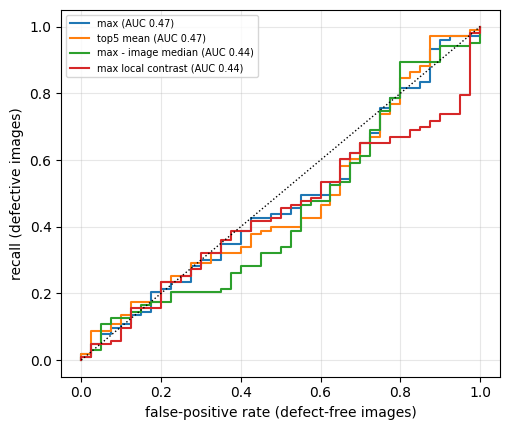

 FPR fabric  share flagged: defect-free images  share flagged: clean parts of defective images  mean z defect-free  mean z defective(clean)
0.01     00                              0.000                                           0.017              -0.515                   -0.127
0.01     01                              0.006                                           0.012              -0.213                    0.397
0.01     02                              0.006                                           0.010               0.188                    0.183
0.01     03                              0.005                                           0.011              -0.838                   -0.541
0.01     04                              0.001                                           0.014               0.750                    0.399
0.01     05                              0.000                                           0.087               0.244                    4.229
0.01     06         

In [10]:
# =============================================================================
# IMAGE-LEVEL DETECTION: is this strip defective or not?
# Run AFTER cells W1 and W2 of week6_pipeline.py in the SAME session (Q1 not required; scores are computed here if missing).
#
# Each image gets ONE score from its out-of-fold patch scores (final config: Gabor+FFT, CLAHE+blur, per-fabric model).
# Four ways to turn patch scores into an image score are compared. Evaluation:
#   - ROC-AUC (defective vs defect-free images), with image-bootstrap 95% CI
#   - recall (TPR) at fixed false-positive rates measured on the defect-free images
#   - precision, at the dataset's own prevalence AND at lower, more realistic prevalences
#   - recall by defect size and by defect type at 10% FPR
# IMPORTANT: the cache has only 40 defect-free images, so every FPR is measured on 40 images (resolution 2.5%).
# =============================================================================


# %% [CELL I1] — Patch scores -> image scores
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy.ndimage import median_filter
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

need = ["X_all", "srcs", "IMG", "counts", "fab_img", "fab_patch", "is_def_img", "def_img", "ov", "clean",
        "GRID", "MASKS", "SEEDS", "K_FOLDS", "N", "OUT", "MIN_TRAIN"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run cells W1 and W2 of week6_pipeline.py first (missing: {miss})"

REUSE_Q1_SCORES = False        # True only if Q1 was run in THIS session on THIS cache (stale scores would give wrong results)
if not (REUSE_Q1_SCORES and "z" in globals() and np.shape(z) == (N,)):   # compute fresh out-of-fold scores
    Xc = X_all[:, 44:68]
    def _fit(X):
        sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
        l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
        return sc, lw, med, mad
    def _apply(m, X):
        sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
    def _folds(seed):
        rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
        for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
        for key in sorted(groups):
            g = groups[key]; rng.shuffle(g)
            for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
            ctr += len(g)
        return np.repeat([fold[s] for s in srcs], counts)
    fold = _folds(SEEDS[0]); z = np.full(N, np.nan)
    for k in range(K_FOLDS):
        te = fold == k; tr = (~te) & clean; pooled = _fit(Xc[tr])
        for f in np.unique(fab_patch[te]):
            tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
            z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])

SCORERS = {
    "max":              lambda g: g.max(),                                               # most anomalous patch
    "top5 mean":        lambda g: np.sort(g.ravel())[::-1][:5].mean(),                   # robust to one noisy patch
    "max - image median": lambda g: g.max() - np.median(g),                              # removes whole-image offsets
    "max local contrast": lambda g: (g - median_filter(g, size=(g.shape[0], 17), mode="nearest")).max(),  # stands out from its neighbours along the strip
}
rows = []
for s, st, c in IMG:
    R, C, H, W = GRID[s]; g = z[st:st + c].reshape(R, C)
    rows.append({"path": s, "image": os.path.basename(s), "y": int(is_def_img[s]), "fabric": fab_img[s], "defect": def_img[s],
                 "area_pct": (MASKS[s].mean() * 100) if s in MASKS else np.nan, **{k: f(g) for k, f in SCORERS.items()}})
IM = pd.DataFrame(rows); IM.to_csv(f"{OUT}/image_level_scores.csv", index=False)
n_def, n_nor = int(IM.y.sum()), int((1 - IM.y).sum())
print(f"images: {n_def} defective, {n_nor} defect-free (prevalence of defective in this set = {n_def/(n_def+n_nor):.2f})")


# %% [CELL I2] — Evaluation
FPRS = (0.05, 0.10, 0.20); PREV = (0.10, 0.50)
def op_point(score, y, fpr):
    thr = np.quantile(score[y == 0], 1 - fpr)                      # threshold giving ~fpr false positives on defect-free images
    flag = score > thr; tp = int((flag & (y == 1)).sum()); fp = int((flag & (y == 0)).sum())
    tpr = tp / max((y == 1).sum(), 1); real_fpr = fp / max((y == 0).sum(), 1)
    return thr, tpr, real_fpr, (tp / (tp + fp) if tp + fp else np.nan)
def prec_at(tpr, fpr, prev): return tpr * prev / (tpr * prev + fpr * (1 - prev)) if (tpr * prev + fpr * (1 - prev)) > 0 else np.nan

y = IM.y.values; rng = np.random.RandomState(0); rows = []
ib_d, ib_n = np.where(y == 1)[0], np.where(y == 0)[0]
for name in SCORERS:
    sc = IM[name].values; auc = roc_auc_score(y, sc)
    boots = []
    for _ in range(500):
        ii = np.r_[rng.choice(ib_d, len(ib_d)), rng.choice(ib_n, len(ib_n))]; boots.append(roc_auc_score(y[ii], sc[ii]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    r = {"image score": name, "AUC": round(auc, 3), "AUC 95% CI": f"[{lo:.2f},{hi:.2f}]"}
    for f in FPRS:
        thr, tpr, rf, prec = op_point(sc, y, f); r[f"recall@{int(f*100)}%FPR"] = round(tpr, 3)
        if f == 0.10:
            r["precision (this set)"] = round(prec, 3)
            for p in PREV: r[f"precision @{int(p*100)}% defective"] = round(prec_at(tpr, rf, p), 3)
    rows.append(r)
T = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(f"\nIMAGE-LEVEL DETECTION ({n_def} defective vs {n_nor} defect-free images; FPR measured on the defect-free images)")
print(T.to_string(index=False)); T.to_csv(f"{OUT}/image_level_results.csv", index=False)
print(f"\nNOTE: {n_def/(n_def+n_nor):.0%} of the images in this set are defective, so 'precision (this set)' looks high even for a "
      "useless detector (guessing 'defective' for every image gives that value). Use AUC and the precision at 10%/50% prevalence.")

best = max(SCORERS, key=lambda k: roc_auc_score(y, IM[k].values)); print(f"\nBest image score by AUC: {best}")
thr, *_ = op_point(IM[best].values, y, 0.10); D = IM[IM.y == 1].copy(); D["found"] = D[best] > thr
D["size"] = pd.cut(D["area_pct"], [0, 0.01, 0.1, 1000], labels=["<0.01% of image", "0.01-0.1%", ">0.1%"])
print(f"\nRecall at 10% FPR ({best}) by defect size:"); print(D.groupby("size", observed=True).found.agg(images="count", recall="mean").round(3).to_string())
print("\nby defect-type code:"); print(D.groupby("defect").found.agg(images="count", recall="mean").round(3).sort_values("images", ascending=False).to_string())
print("\nby fabric:"); print(D.groupby("fabric").found.agg(images="count", recall="mean").round(3).to_string())
print("\ndefect-free images per fabric (used for the FPR):", IM[IM.y == 0].groupby("fabric").size().to_dict())

plt.figure(figsize=(5.2, 4.4))
for name in SCORERS:
    fp, tp, _ = roc_curve(y, IM[name].values); plt.plot(fp, tp, label=f"{name} (AUC {roc_auc_score(y, IM[name].values):.2f})")
plt.plot([0, 1], [0, 1], "k:", lw=1); plt.xlabel("false-positive rate (defect-free images)"); plt.ylabel("recall (defective images)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/image_level_roc.png", dpi=150); plt.show()


# %% [CELL I3] — Why is image-level detection at chance? Do defect-free images simply look different?
# Compare CLEAN patches (no ground-truth overlap) of defect-free images with the clean patches of defective images.
# With no systematic difference, both groups should be flagged at about the nominal 1% / 5% rates.
isdef_patch = np.repeat([is_def_img[s] for s in srcs], counts)
rows = []
for q in (0.01, 0.05):
    thr = {f: np.quantile(z[(fab_patch == f) & clean], 1 - q) for f in np.unique(fab_patch)}
    flag = z > pd.Series(fab_patch).map(thr).values
    for f in list(np.unique(fab_patch)) + ["ALL"]:
        m = clean if f == "ALL" else clean & (fab_patch == f)
        rows.append({"FPR": q, "fabric": f, "share flagged: defect-free images": flag[m & ~isdef_patch].mean(),
                     "share flagged: clean parts of defective images": flag[m & isdef_patch].mean(),
                     "mean z defect-free": z[m & ~isdef_patch].mean(), "mean z defective(clean)": z[m & isdef_patch].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nIf 'defect-free' is clearly ABOVE the nominal rate (or above the defective column), the defect-free images are scored as more\n"
      "abnormal than defective ones for reasons unrelated to defects (borders, margins, seams, different rolls); that makes an image-level\n"
      "test unfair and points to masking those regions out before scoring.")

In [11]:
import cv2
from scipy.ndimage import distance_transform_edt
THR5 = {f: np.quantile(z[(fab_patch == f) & clean], 0.95) for f in np.unique(fab_patch)}
rows = []
for s, st, c in IMG:
    R, C, H, W = GRID[s]; g = z[st:st + c].reshape(R, C); o = ov[st:st + c].reshape(R, C) > 0
    far = (distance_transform_edt(~o) > 4) if o.any() else np.ones((R, C), bool)   # patches > 4*32 px from the defect
    gf = g[far]; im = cv2.imread(s, cv2.IMREAD_GRAYSCALE)
    rows.append({"y": int(is_def_img[s]), "fabric": fab_img[s],
                 "mean z": g.mean(), "p90 z": np.percentile(g, 90), "share>thr5": (g > THR5[fab_img[s]]).mean(),
                 "mean z (far from defect)": gf.mean(), "share>thr5 (far from defect)": (gf > THR5[fab_img[s]]).mean(),
                 "blank fraction": (im > 235).mean(), "image brightness": im.mean(), "image contrast": im.std()})
A = pd.DataFrame(rows); y4 = A.y.values; rng = np.random.RandomState(1); res = []
for col in [c for c in A.columns if c not in ("y", "fabric")]:
    sc = A[col].values; boots = []
    for _ in range(300):
        ii = np.r_[rng.choice(np.where(y4 == 1)[0], (y4 == 1).sum()), rng.choice(np.where(y4 == 0)[0], (y4 == 0).sum())]
        boots.append(roc_auc_score(y4[ii], sc[ii]))
    res.append({"image feature": col, "AUC": round(roc_auc_score(y4, sc), 3), "95% CI": "[%.2f,%.2f]" % tuple(np.percentile(boots, [2.5, 97.5]))})
print(pd.DataFrame(res).sort_values("AUC", ascending=False).to_string(index=False))
print("\nGroup means (0 = defect-free, 1 = defective):"); print(A.groupby("y")[["blank fraction", "image brightness", "image contrast"]].mean().round(3).to_string())

               image feature   AUC      95% CI
                  share>thr5 0.721 [0.62,0.81]
share>thr5 (far from defect) 0.670 [0.58,0.76]
            image brightness 0.613 [0.49,0.73]
                       p90 z 0.587 [0.49,0.69]
                      mean z 0.544 [0.44,0.65]
    mean z (far from defect) 0.505 [0.40,0.61]
              image contrast 0.495 [0.40,0.60]
              blank fraction 0.484 [0.39,0.59]

Group means (0 = defect-free, 1 = defective):
   blank fraction  image brightness  image contrast
y                                                  
0           0.103           125.239          44.960
1           0.104           127.353          46.026


images: 103 defective, 40 defect-free (prevalence of defective in this set = 0.72)

IMAGE-LEVEL DETECTION (103 defective vs 40 defect-free images; FPR measured on the defect-free images)
       image score   AUC  AUC 95% CI  recall@5%FPR  recall@10%FPR  precision (this set)  precision @10% defective  precision @50% defective  recall@20%FPR
               max 0.475 [0.38,0.59]         0.078          0.107                 0.733                     0.106                     0.516          0.204
         top5 mean 0.471 [0.37,0.58]         0.087          0.136                 0.778                     0.131                     0.576          0.214
max - image median 0.443 [0.33,0.55]         0.107          0.126                 0.765                     0.123                     0.558          0.175
max local contrast 0.440 [0.34,0.53]         0.049          0.097                 0.714                     0.097                     0.493          0.223

NOTE: 72% of the images in this set a

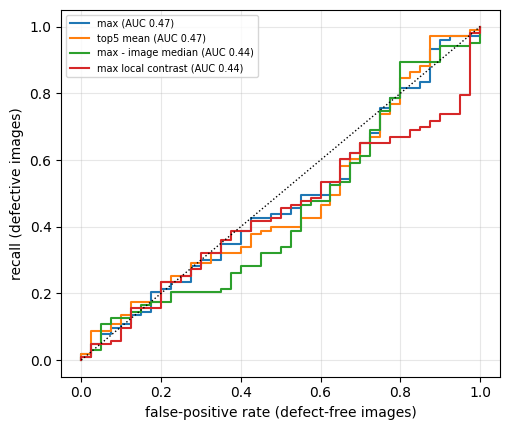

 FPR fabric  share flagged: defect-free images  share flagged: clean parts of defective images  mean z defect-free  mean z defective(clean)
0.01     00                              0.000                                           0.017              -0.515                   -0.127
0.01     01                              0.006                                           0.012              -0.213                    0.397
0.01     02                              0.006                                           0.010               0.188                    0.183
0.01     03                              0.005                                           0.011              -0.838                   -0.541
0.01     04                              0.001                                           0.014               0.750                    0.399
0.01     05                              0.000                                           0.087               0.244                    4.229
0.01     06         

In [12]:
# =============================================================================
# IMAGE-LEVEL DETECTION: is this strip defective or not?
# Run AFTER cells W1 and W2 of week6_pipeline.py in the SAME session (Q1 not required; scores are computed here if missing).
#
# Each image gets ONE score from its out-of-fold patch scores (final config: Gabor+FFT, CLAHE+blur, per-fabric model).
# Four ways to turn patch scores into an image score are compared. Evaluation:
#   - ROC-AUC (defective vs defect-free images), with image-bootstrap 95% CI
#   - recall (TPR) at fixed false-positive rates measured on the defect-free images
#   - precision, at the dataset's own prevalence AND at lower, more realistic prevalences
#   - recall by defect size and by defect type at 10% FPR
# IMPORTANT: the cache has only 40 defect-free images, so every FPR is measured on 40 images (resolution 2.5%).
# =============================================================================


# %% [CELL I1] — Patch scores -> image scores
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy.ndimage import median_filter
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

need = ["X_all", "srcs", "IMG", "fab_img", "fab_patch", "is_def_img", "def_img", "ov", "clean",
        "GRID", "MASKS", "SEEDS", "K_FOLDS", "N", "OUT", "MIN_TRAIN"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run cells W1 and W2 of week6_pipeline.py first (missing: {miss})"
PCOUNT = np.array([c for _, _, c in IMG])          # patches per image (does not depend on the name 'counts', which other cells may overwrite)
assert len(X_all) == N == int(PCOUNT.sum()) == len(ov), "W1/W2 variables are inconsistent: re-run W1 and then W2"
if "feature_matrix" in globals():
    assert len(feature_matrix) == N, ("the cache was REBUILT after W1 ran (feature_matrix has %d patches, W1 used %d). "
                                      "Re-run W1 and then W2, then this cell." % (len(feature_matrix), N))

REUSE_Q1_SCORES = False        # True only if Q1 was run in THIS session on THIS cache (stale scores would give wrong results)
if not (REUSE_Q1_SCORES and "z" in globals() and np.shape(z) == (N,)):   # compute fresh out-of-fold scores
    Xc = X_all[:, 44:68]
    def _fit(X):
        sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
        l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
        return sc, lw, med, mad
    def _apply(m, X):
        sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
    def _folds(seed):
        rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
        for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
        for key in sorted(groups):
            g = groups[key]; rng.shuffle(g)
            for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
            ctr += len(g)
        return np.repeat([fold[s] for s in srcs], PCOUNT)
    fold = _folds(SEEDS[0]); z = np.full(N, np.nan)
    for k in range(K_FOLDS):
        te = fold == k; tr = (~te) & clean; pooled = _fit(Xc[tr])
        for f in np.unique(fab_patch[te]):
            tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
            z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])

SCORERS = {
    "max":              lambda g: g.max(),                                               # most anomalous patch
    "top5 mean":        lambda g: np.sort(g.ravel())[::-1][:5].mean(),                   # robust to one noisy patch
    "max - image median": lambda g: g.max() - np.median(g),                              # removes whole-image offsets
    "max local contrast": lambda g: (g - median_filter(g, size=(g.shape[0], 17), mode="nearest")).max(),  # stands out from its neighbours along the strip
}
rows = []
for s, st, c in IMG:
    R, C, H, W = GRID[s]; g = z[st:st + c].reshape(R, C)
    rows.append({"path": s, "image": os.path.basename(s), "y": int(is_def_img[s]), "fabric": fab_img[s], "defect": def_img[s],
                 "area_pct": (MASKS[s].mean() * 100) if s in MASKS else np.nan, **{k: f(g) for k, f in SCORERS.items()}})
IM = pd.DataFrame(rows); IM.to_csv(f"{OUT}/image_level_scores.csv", index=False)
n_def, n_nor = int(IM.y.sum()), int((1 - IM.y).sum())
print(f"images: {n_def} defective, {n_nor} defect-free (prevalence of defective in this set = {n_def/(n_def+n_nor):.2f})")


# %% [CELL I2] — Evaluation
FPRS = (0.05, 0.10, 0.20); PREV = (0.10, 0.50)
def op_point(score, y, fpr):
    thr = np.quantile(score[y == 0], 1 - fpr)                      # threshold giving ~fpr false positives on defect-free images
    flag = score > thr; tp = int((flag & (y == 1)).sum()); fp = int((flag & (y == 0)).sum())
    tpr = tp / max((y == 1).sum(), 1); real_fpr = fp / max((y == 0).sum(), 1)
    return thr, tpr, real_fpr, (tp / (tp + fp) if tp + fp else np.nan)
def prec_at(tpr, fpr, prev): return tpr * prev / (tpr * prev + fpr * (1 - prev)) if (tpr * prev + fpr * (1 - prev)) > 0 else np.nan

y = IM.y.values; rng = np.random.RandomState(0); rows = []
ib_d, ib_n = np.where(y == 1)[0], np.where(y == 0)[0]
for name in SCORERS:
    sc = IM[name].values; auc = roc_auc_score(y, sc)
    boots = []
    for _ in range(500):
        ii = np.r_[rng.choice(ib_d, len(ib_d)), rng.choice(ib_n, len(ib_n))]; boots.append(roc_auc_score(y[ii], sc[ii]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    r = {"image score": name, "AUC": round(auc, 3), "AUC 95% CI": f"[{lo:.2f},{hi:.2f}]"}
    for f in FPRS:
        thr, tpr, rf, prec = op_point(sc, y, f); r[f"recall@{int(f*100)}%FPR"] = round(tpr, 3)
        if f == 0.10:
            r["precision (this set)"] = round(prec, 3)
            for p in PREV: r[f"precision @{int(p*100)}% defective"] = round(prec_at(tpr, rf, p), 3)
    rows.append(r)
T = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(f"\nIMAGE-LEVEL DETECTION ({n_def} defective vs {n_nor} defect-free images; FPR measured on the defect-free images)")
print(T.to_string(index=False)); T.to_csv(f"{OUT}/image_level_results.csv", index=False)
print(f"\nNOTE: {n_def/(n_def+n_nor):.0%} of the images in this set are defective, so 'precision (this set)' looks high even for a "
      "useless detector (guessing 'defective' for every image gives that value). Use AUC and the precision at 10%/50% prevalence.")

best = max(SCORERS, key=lambda k: roc_auc_score(y, IM[k].values)); print(f"\nBest image score by AUC: {best}")
thr, *_ = op_point(IM[best].values, y, 0.10); D = IM[IM.y == 1].copy(); D["found"] = D[best] > thr
D["size"] = pd.cut(D["area_pct"], [0, 0.01, 0.1, 1000], labels=["<0.01% of image", "0.01-0.1%", ">0.1%"])
print(f"\nRecall at 10% FPR ({best}) by defect size:"); print(D.groupby("size", observed=True).found.agg(images="count", recall="mean").round(3).to_string())
print("\nby defect-type code:"); print(D.groupby("defect").found.agg(images="count", recall="mean").round(3).sort_values("images", ascending=False).to_string())
print("\nby fabric:"); print(D.groupby("fabric").found.agg(images="count", recall="mean").round(3).to_string())
print("\ndefect-free images per fabric (used for the FPR):", IM[IM.y == 0].groupby("fabric").size().to_dict())

plt.figure(figsize=(5.2, 4.4))
for name in SCORERS:
    fp, tp, _ = roc_curve(y, IM[name].values); plt.plot(fp, tp, label=f"{name} (AUC {roc_auc_score(y, IM[name].values):.2f})")
plt.plot([0, 1], [0, 1], "k:", lw=1); plt.xlabel("false-positive rate (defect-free images)"); plt.ylabel("recall (defective images)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig(f"{OUT}/image_level_roc.png", dpi=150); plt.show()


# %% [CELL I3] — Why is image-level detection at chance? Do defect-free images simply look different?
# Compare CLEAN patches (no ground-truth overlap) of defect-free images with the clean patches of defective images.
# With no systematic difference, both groups should be flagged at about the nominal 1% / 5% rates.
isdef_patch = np.repeat([is_def_img[s] for s in srcs], PCOUNT)
rows = []
for q in (0.01, 0.05):
    thr = {f: np.quantile(z[(fab_patch == f) & clean], 1 - q) for f in np.unique(fab_patch)}
    flag = z > pd.Series(fab_patch).map(thr).values
    for f in list(np.unique(fab_patch)) + ["ALL"]:
        m = clean if f == "ALL" else clean & (fab_patch == f)
        rows.append({"FPR": q, "fabric": f, "share flagged: defect-free images": flag[m & ~isdef_patch].mean(),
                     "share flagged: clean parts of defective images": flag[m & isdef_patch].mean(),
                     "mean z defect-free": z[m & ~isdef_patch].mean(), "mean z defective(clean)": z[m & isdef_patch].mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nIf 'defect-free' is clearly ABOVE the nominal rate (or above the defective column), the defect-free images are scored as more\n"
      "abnormal than defective ones for reasons unrelated to defects (borders, margins, seams, different rolls); that makes an image-level\n"
      "test unfair and points to masking those regions out before scoring.")


# %% [CELL I4] — Which whole-image statistics separate defective from defect-free strips? (and is it just brightness / capture?)
import cv2
from scipy.ndimage import distance_transform_edt
THR5 = {f: np.quantile(z[(fab_patch == f) & clean], 0.95) for f in np.unique(fab_patch)}
rows = []
for s, st, c in IMG:
    R, C, H, W = GRID[s]; g = z[st:st + c].reshape(R, C); o = ov[st:st + c].reshape(R, C) > 0
    far = (distance_transform_edt(~o) > 4) if o.any() else np.ones((R, C), bool)   # patches > 4*32 px from the defect
    gf = g[far]; im = cv2.imread(s, cv2.IMREAD_GRAYSCALE)
    rows.append({"y": int(is_def_img[s]), "fabric": fab_img[s],
                 "mean z": g.mean(), "p90 z": np.percentile(g, 90), "share>thr5": (g > THR5[fab_img[s]]).mean(),
                 "mean z (far from defect)": gf.mean(), "share>thr5 (far from defect)": (gf > THR5[fab_img[s]]).mean(),
                 "blank fraction": (im > 235).mean(), "image brightness": im.mean(), "image contrast": im.std()})
A = pd.DataFrame(rows); y4 = A.y.values; rng = np.random.RandomState(1); res = []
for col in [c for c in A.columns if c not in ("y", "fabric")]:
    sc = A[col].values; boots = []
    for _ in range(300):
        ii = np.r_[rng.choice(np.where(y4 == 1)[0], (y4 == 1).sum()), rng.choice(np.where(y4 == 0)[0], (y4 == 0).sum())]
        boots.append(roc_auc_score(y4[ii], sc[ii]))
    res.append({"image feature": col, "AUC": round(roc_auc_score(y4, sc), 3), "95% CI": "[%.2f,%.2f]" % tuple(np.percentile(boots, [2.5, 97.5]))})
print(pd.DataFrame(res).sort_values("AUC", ascending=False).to_string(index=False))
print("\nGroup means (0 = defect-free, 1 = defective):"); print(A.groupby("y")[["blank fraction", "image brightness", "image contrast"]].mean().round(3).to_string())


# %% [CELL I5] — Controls: operating points, AUC within each fabric, and does the score add anything beyond brightness + fabric?
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

def _op(score, y, fpr):
    thr = np.quantile(score[y == 0], 1 - fpr); flag = score > thr
    tp = int((flag & (y == 1)).sum()); fp = int((flag & (y == 0)).sum()); return tp / (y == 1).sum(), fp / (y == 0).sum()
def _prec(tpr, fpr, prev): d = tpr * prev + fpr * (1 - prev); return tpr * prev / d if d > 0 else np.nan

print("1) OPERATING POINTS (FPR measured on defect-free images)")
rows = []
for col in ("share>thr5", "p90 z", "mean z"):
    r = {"image score": col, "AUC": round(roc_auc_score(y4, A[col].values), 3)}
    for f in (0.05, 0.10, 0.20):
        tpr, rf = _op(A[col].values, y4, f); r[f"recall@{int(f*100)}%FPR"] = round(tpr, 3)
        if f == 0.10: r["precision@10% defective"] = round(_prec(tpr, rf, 0.10), 3); r["precision@50% defective"] = round(_prec(tpr, rf, 0.50), 3)
    rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))

print("\n2) AUC WITHIN EACH FABRIC (fabrics with at least 3 images of each class)")
rows = []
for f in sorted(A.fabric.unique()):
    d = A[A.fabric == f]
    if (d.y == 1).sum() >= 3 and (d.y == 0).sum() >= 3:
        rows.append({"fabric": f, "defective": int((d.y == 1).sum()), "defect-free": int((d.y == 0).sum()),
                     "AUC share>thr5": round(roc_auc_score(d.y, d["share>thr5"]), 3), "AUC brightness": round(roc_auc_score(d.y, d["image brightness"]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

print("\n3) CROSS-VALIDATED AUC OF LOGISTIC REGRESSION (does the score add information beyond fabric and brightness?)")
F = pd.get_dummies(A.fabric).astype(float); cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=0); rows = []
sets = {"fabric only": F, "brightness only": A[["image brightness"]], "fabric + brightness": pd.concat([F, A[["image brightness"]]], axis=1),
        "share>thr5 only": A[["share>thr5"]], "share>thr5 + fabric + brightness": pd.concat([F, A[["image brightness", "share>thr5"]]], axis=1),
        "share>thr5 (far) + fabric + brightness": pd.concat([F, A[["image brightness", "share>thr5 (far from defect)"]]], axis=1)}
for name, X in sets.items():
    sc = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X.values, y4, cv=cv, scoring="roc_auc")
    rows.append({"features": name, "CV AUC": round(sc.mean(), 3), "std": round(sc.std(), 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nINTERPRETATION: if 'share>thr5 + fabric + brightness' is clearly above 'fabric + brightness', the anomaly score carries information"
      "\nbeyond capture differences. If not, the 0.77 is mostly fabric/brightness and should not be presented as defect detection.")

images: 103 defective, 40 defect-free
features done in 168s | F34 (127057, 34) | sanity: max |recomputed - cached| on the 24 baseline features = 0.00e+00
MASK: 11.3% of all patches masked; 84 of 143 images have a masked zone; defect-overlapping patches lost to the mask: 39 of 2087 (1.9%)
defective images whose defect lies completely inside the masked zone (counted as MISSED under masking): 0
A baseline                 done in 4s | AP(relaxed) 0.145 | AUC 0.798
B + margin/edge mask       done in 4s | AP(relaxed) 0.179 | AUC 0.805
C thin-defect features     done in 8s | AP(relaxed) 0.157 | AUC 0.825
D thin features + mask     done in 8s | AP(relaxed) 0.182 | AUC 0.835
WEEK 7 COMPARISON  (103 defective / 40 defect-free images; metrics 2-3 use the 102 defective images with a defect patch)
         configuration  patches used % AP (relaxed)  patch AUC           recall@1%           recall@5%            FA/img@1%           top-1 hit          top-10 hit           image AUC image recall@10%FPR


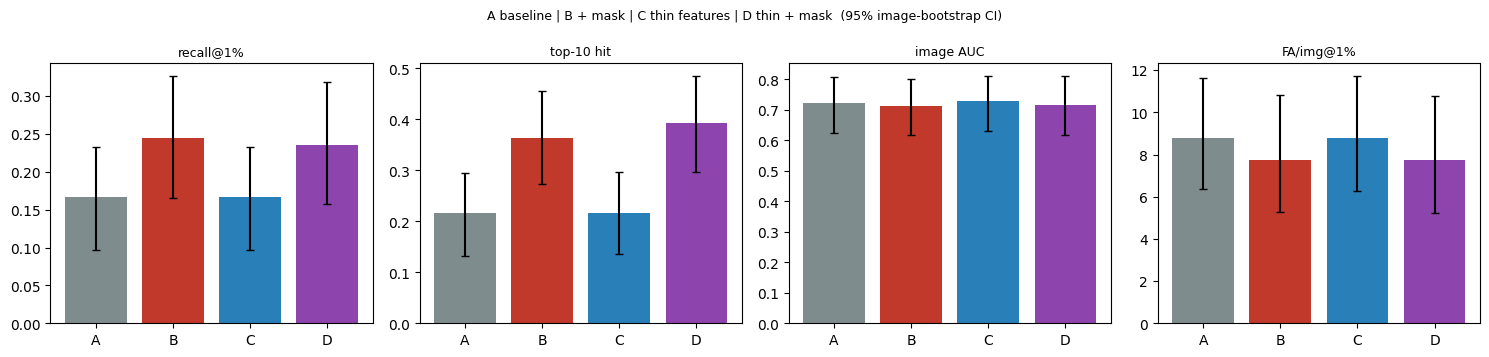

In [13]:
# =============================================================================
# WEEK 7 PIPELINE — one consistent comparison of four configurations on the SAME data and measures
#
#   A  baseline            : 24 Gabor+FFT features, no masking
#   B  + margin/edge mask  : same features, blank margins and the zone around them are excluded
#                            from training, thresholds, scoring and evaluation
#   C  thin-defect features: 34 features = baseline 24 + 95th percentile of |Gabor response| (8)
#                            + column/row profile spread (2), no masking
#   D  C + margin/edge mask
#
# Four measures (all out-of-fold, per-fabric models, per-fabric thresholds):
#   1. patch-level average precision / AUC (relaxed labels: any overlap with the defect)
#   2. defect recall at 1% and 5% false-positive rate, and false-alarm patches per image
#   3. localization: does one of the top-1 / top-10 patches of the image overlap the defect? (vs random)
#   4. image-level: AUC of "share of flagged patches" (defective vs defect-free strips), recall at 10% FPR
# Confidence intervals come from resampling IMAGES (500 bootstrap resamples, shared across configurations
# so the differences to the baseline are paired).
#
# BEFORE RUNNING:
#   * Use the FROZEN cache built with the fixed build_feature_cache.py (all 141 defect-free images).
#   * Run cells W1 and W2 of week6_pipeline.py first, in the SAME session (re-run them after any rebuild).
#   * Cells: K1 (extra features + masks, ~2-4 min) -> K2 (four configurations, the long cell) -> K3 (tables, CIs, figure)
# =============================================================================


# %% [CELL K1] — Extra features (thin-defect) and blank-margin map, in one pass over the images
import os, time
from collections import defaultdict
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import ndimage as ndi
from scipy.stats import hypergeom
from skimage.filters import gabor_kernel
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

need = ["X_all", "srcs", "IMG", "fab_img", "fab_patch", "is_def_img", "ov", "clean", "GRID",
        "SEEDS", "K_FOLDS", "N", "OUT", "MIN_TRAIN", "PATCH", "STRIDE", "y_any"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run cells W1 and W2 of week6_pipeline.py first (missing: {miss})"
PCOUNT = np.array([c for _, _, c in IMG])
assert len(X_all) == N == int(PCOUNT.sum()) == len(ov), "W1/W2 variables are inconsistent: re-run W1 and then W2"
if "feature_matrix" in globals():
    assert len(feature_matrix) == N, "the cache was REBUILT after W1 ran: re-run W1 and then W2"
n_nor = sum(not is_def_img[s] for s in srcs); n_def = sum(is_def_img[s] for s in srcs)
print(f"images: {n_def} defective, {n_nor} defect-free")
if n_nor != 141: print("WARNING: expected the frozen cache with 141 defect-free images; results will not match the final report.")

# Margin detection: a column is 'white' if >=80% of its pixels are >235; a margin is a run of >=48 consecutive white columns
# (a wide, full-height blank band). Thin bright DEFECTS (lines a few pixels wide) are NOT margins and are never masked.
# The margin is then widened by 48 px on each side to cover the fabric edge next to it.
MARGIN_WHITE, MARGIN_ROWFRAC, MARGIN_MINRUN, MARGIN_EDGE_PX = 235, 0.8, 48, 48
from scipy.ndimage import label as _label, binary_dilation as _bdil
G_KERNELS = [gabor_kernel(f, theta=t).real.astype(np.float32) for f in [0.1, 0.3] for t in [0, np.pi/4, np.pi/2, 3*np.pi/4]]
def fft_feat(p):
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(p.astype(np.float32)))))
    h, w = mag.shape; yy, xx = np.mgrid[0:h, 0:w]; r = np.sqrt((yy - h // 2) ** 2 + (xx - w // 2) ** 2); out = []
    for lo, hi in [(0, 4), (4, 10), (10, 20), (20, max(h, w))]:
        m = (r >= lo) & (r < hi); out += [mag[m].mean() if m.any() else 0.0, mag[m].std() if m.any() else 0.0]
    return np.array(out)

def thin_worker(path):
    im0 = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im0), (3, 3), 0)   # same preprocessing as the cache
    f = im.astype(np.float32) / 255.0
    maps = [cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101) for k in G_KERNELS]
    H, W = im.shape; F = []
    for y in range(0, H - PATCH + 1, STRIDE):
        for x in range(0, W - PATCH + 1, STRIDE):
            wins = [m[y:y + PATCH, x:x + PATCH] for m in maps]
            g = [v for w in wins for v in (float(w.mean()), float(w.var()))]                  # 16 (identical to the cache)
            p95 = [float(np.percentile(np.abs(w), 95)) for w in wins]                           # 8  thin-structure response
            pt = f[y:y + PATCH, x:x + PATCH]; prof = [float(pt.mean(0).std()), float(pt.mean(1).std())]   # 2  line-like structure
            F.append(np.concatenate([g, fft_feat(im[y:y + PATCH, x:x + PATCH]), p95, prof]))
    return np.array(F, np.float32)

t0 = time.time()
res = Parallel(n_jobs=-1)(delayed(thin_worker)(s) for s, _, _ in IMG)
F34 = np.vstack(res); assert len(F34) == N
d = np.abs(F34[:, :24] - X_all[:, 44:68]).max()
print(f"features done in {time.time()-t0:.0f}s | F34 {F34.shape} | sanity: max |recomputed - cached| on the 24 baseline features = {d:.2e}"
      + ("" if d < 1e-3 else "   <-- WARNING: differs from the cache, check that the cache matches these images"))

def margin_columns(im0):
    colw = (im0 > MARGIN_WHITE).mean(axis=0) >= MARGIN_ROWFRAC
    lab, n = _label(colw); m = np.zeros_like(colw)
    for i in range(1, n + 1):
        run = lab == i
        if run.sum() >= MARGIN_MINRUN: m |= run
    return _bdil(m, iterations=MARGIN_EDGE_PX) if m.any() else m

VALID = np.ones(N, bool)
for s, st, c in IMG:
    R, C, _, _ = GRID[s]; m = margin_columns(cv2.imread(s, cv2.IMREAD_GRAYSCALE)); cs = np.r_[0, np.cumsum(m)]
    x0 = np.arange(C) * STRIDE; bad = (cs[x0 + PATCH] - cs[x0]) > 0                       # patch columns overlapping a margin
    VALID[st:st + c] = ~np.tile(bad, R)
n_img_masked = sum((~VALID[st:st + c]).any() for _, st, c in IMG)
lost = int(((y_any == 1) & ~VALID).sum())
print(f"MASK: {(~VALID).mean()*100:.1f}% of all patches masked; {n_img_masked} of {len(IMG)} images have a masked zone; "
      f"defect-overlapping patches lost to the mask: {lost} of {int(y_any.sum())} ({lost/max(y_any.sum(),1)*100:.1f}%)")
lost_img = 0
for s, st, c in IMG:
    if is_def_img[s] and (ov[st:st + c] > 0).any() and not ((ov[st:st + c] > 0) & VALID[st:st + c]).any(): lost_img += 1
print(f"defective images whose defect lies completely inside the masked zone (counted as MISSED under masking): {lost_img}")


# %% [CELL K2] — Run the four configurations (this is the long cell)
def _fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
    return sc, lw, med, mad
def _apply(m, X):
    sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
def _folds(seed):
    rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
    for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
    for key in sorted(groups):
        g = groups[key]; rng.shuffle(g)
        for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
        ctr += len(g)
    return np.repeat([fold[s] for s in srcs], PCOUNT)

def image_outcomes(z, valid):
    """Per-image results from out-of-fold scores z, using only VALID patches for thresholds, flags and ranking."""
    fabs = np.unique(fab_patch)
    thr = {q: {f: np.quantile(z[(fab_patch == f) & clean & valid], 1 - q) for f in fabs} for q in (0.01, 0.05)}
    t1, t5 = thr[0.01], thr[0.05]; rows = []
    for s, st, c in IMG:
        zz, v, o = z[st:st + c], valid[st:st + c], ov[st:st + c] > 0; f = fab_img[s]; d = bool(is_def_img[s])
        fl1, fl5 = (zz > t1[f]) & v, (zz > t5[f]) & v
        r = {"defective": d, "fabric": f, "has_gt": bool(d and o.any()), "fa1": int((fl1 & ~o).sum()), "fa5": int((fl5 & ~o).sum()),
             "share5": float(fl5.sum() / max(v.sum(), 1)), "found1": np.nan, "found5": np.nan,
             "top1": np.nan, "top10": np.nan, "chance1": np.nan, "chance10": np.nan}
        if r["has_gt"]:
            ov_ = o & v; r["found1"] = float((fl1 & o).any()); r["found5"] = float((fl5 & o).any())
            if ov_.any():
                order = np.argsort(-np.where(v, zz, -np.inf)); hit = ov_[order]; n, m = int(v.sum()), int(ov_.sum())
                for k in (1, 10):
                    r[f"top{k}"] = float(hit[:k].any()); r[f"chance{k}"] = float(1 - hypergeom.pmf(0, n, m, k))
            else:                                                     # defect entirely inside the masked zone = a miss
                r["top1"] = r["top10"] = 0.0; r["chance1"] = r["chance10"] = 0.0
        rows.append(r)
    return pd.DataFrame(rows)

ALLV = np.ones(N, bool)
CONFIGS = {"A baseline": (X_all[:, 44:68], ALLV), "B + margin/edge mask": (X_all[:, 44:68], VALID),
           "C thin-defect features": (F34, ALLV), "D thin features + mask": (F34, VALID)}
RUN = {}
for name, (Xc, valid) in CONFIGS.items():
    t0 = time.time(); aps, aucs, z0 = [], [], None
    for seed in SEEDS:
        fold = _folds(seed); z = np.full(N, np.nan)
        for k in range(K_FOLDS):
            te = fold == k; tr = (~te) & clean & valid; pooled = _fit(Xc[tr])
            for f in np.unique(fab_patch[te]):
                tef, trf = te & (fab_patch == f), tr & (fab_patch == f)
                z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])
            m = te & valid
            if 0 < y_any[m].sum() < m.sum(): aps.append(average_precision_score(y_any[m], z[m])); aucs.append(roc_auc_score(y_any[m], z[m]))
        if z0 is None: z0 = z
    RUN[name] = {"AP": np.array(aps), "AUC": np.array(aucs), "img": image_outcomes(z0, valid), "z": z0, "valid": valid}
    print(f"{name:26s} done in {time.time()-t0:.0f}s | AP(relaxed) {np.mean(aps):.3f} | AUC {np.mean(aucs):.3f}")


# %% [CELL K3] — Consistent comparison table, bootstrap confidence intervals, paired differences, figure
B_RES = 500; rng = np.random.RandomState(0)
base = RUN["A baseline"]["img"]; idx_d = np.where(base.defective)[0]; idx_n = np.where(~base.defective)[0]

def metrics(df, ii_d, ii_n):
    d = df.iloc[ii_d]; g = d[d.has_gt]; n = df.iloc[ii_n]
    sc = np.r_[d.share5.values, n.share5.values]; y = np.r_[np.ones(len(d)), np.zeros(len(n))]
    thr = np.quantile(n.share5.values, 0.90)
    return {"recall@1%": g.found1.mean(), "recall@5%": g.found5.mean(), "FA/img@1%": df.iloc[np.r_[ii_d, ii_n]].fa1.mean(),
            "top-1 hit": g.top1.mean(), "top-10 hit": g.top10.mean(), "image AUC": roc_auc_score(y, sc), "image recall@10%FPR": (d.share5.values > thr).mean()}

KEYS = list(metrics(base, idx_d, idx_n))
boot = {n: {k: [] for k in KEYS} for n in RUN}
for _ in range(B_RES):
    ii_d = rng.choice(idx_d, len(idx_d)); ii_n = rng.choice(idx_n, len(idx_n))
    for n in RUN:
        m = metrics(RUN[n]["img"], ii_d, ii_n)
        for k in KEYS: boot[n][k].append(m[k])

rows = []
for n in RUN:
    pt = metrics(RUN[n]["img"], idx_d, idx_n); r = {"configuration": n, "patches used %": round(RUN[n]["valid"].mean() * 100, 1),
         "AP (relaxed)": f"{RUN[n]['AP'].mean():.3f}±{RUN[n]['AP'].std():.3f}", "patch AUC": round(RUN[n]["AUC"].mean(), 3)}
    for k in KEYS:
        lo, hi = np.percentile(boot[n][k], [2.5, 97.5]); r[k] = f"{pt[k]:.3f} [{lo:.3f},{hi:.3f}]"
    rows.append(r)
T = pd.DataFrame(rows); pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 40)
print(f"WEEK 7 COMPARISON  ({n_def} defective / {n_nor} defect-free images; metrics 2-3 use the {int(base.has_gt.sum())} defective images with a defect patch)")
print(T.to_string(index=False)); T.to_csv(f"{OUT}/week7_comparison.csv", index=False)

print("\nPAIRED DIFFERENCE vs A baseline (median [95% CI] over image bootstrap; 'CI excludes 0' = reliable change)")
rows = []; verdict = {}
for n in list(RUN)[1:]:
    r = {"configuration": n}; good = 0
    for k in KEYS:
        d = np.array(boot[n][k]) - np.array(boot["A baseline"][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5])
        sign = "+" if lo > 0 else ("-" if hi < 0 else "0"); r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}] {sign}"
        if k != "FA/img@1%" and sign == "+": good += 1
        if k == "FA/img@1%" and sign == "-": good += 1
    verdict[n] = good; rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("\nDECISION RULE: adopt a change only if at least 2 measures improve with a CI that excludes 0 ('+'), and none gets reliably worse ('-').")
for n, g in verdict.items(): print(f"  {n}: {g} measure(s) reliably improved")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6)); labs = [n.split(" ")[0] for n in RUN]; col = ["#7f8c8d", "#c0392b", "#2980b9", "#8e44ad"]
for a, k in zip(ax, ["recall@1%", "top-10 hit", "image AUC", "FA/img@1%"]):
    m = [metrics(RUN[n]["img"], idx_d, idx_n)[k] for n in RUN]; ci = [np.percentile(boot[n][k], [2.5, 97.5]) for n in RUN]
    a.bar(labs, m, color=col, yerr=[[mm - c[0] for mm, c in zip(m, ci)], [c[1] - mm for mm, c in zip(m, ci)]], capsize=3); a.set_title(k, fontsize=9)
plt.suptitle("A baseline | B + mask | C thin features | D thin + mask  (95% image-bootstrap CI)", fontsize=9); plt.tight_layout()
plt.savefig(f"{OUT}/week7_comparison.png", dpi=150); plt.show()

wrote /kaggle/working/week7_tables.tex (paste into the report; each table has a \label)

CHOSEN = D thin features + mask: found at 1% FPR 0.235 (24/102), at 5% FPR 0.412 (42/102); mean false-alarm patches per image at 1% FPR: 7.8

Detection by defect type (chosen configuration):
             images  recall_1pct  recall_5pct  mean_area_pct
defect_type                                                 
019              38        0.000        0.158          0.003
030              13        0.154        0.154          0.015
002               9        0.000        0.111          0.100
010               9        0.667        1.000          2.300
022               9        0.222        0.556          0.029
006               8        1.000        1.000          0.191
025               5        0.200        0.400          0.002
023               5        0.200        1.000          0.087
016               3        1.000        1.000          0.078
027               1        0.000        0.000    

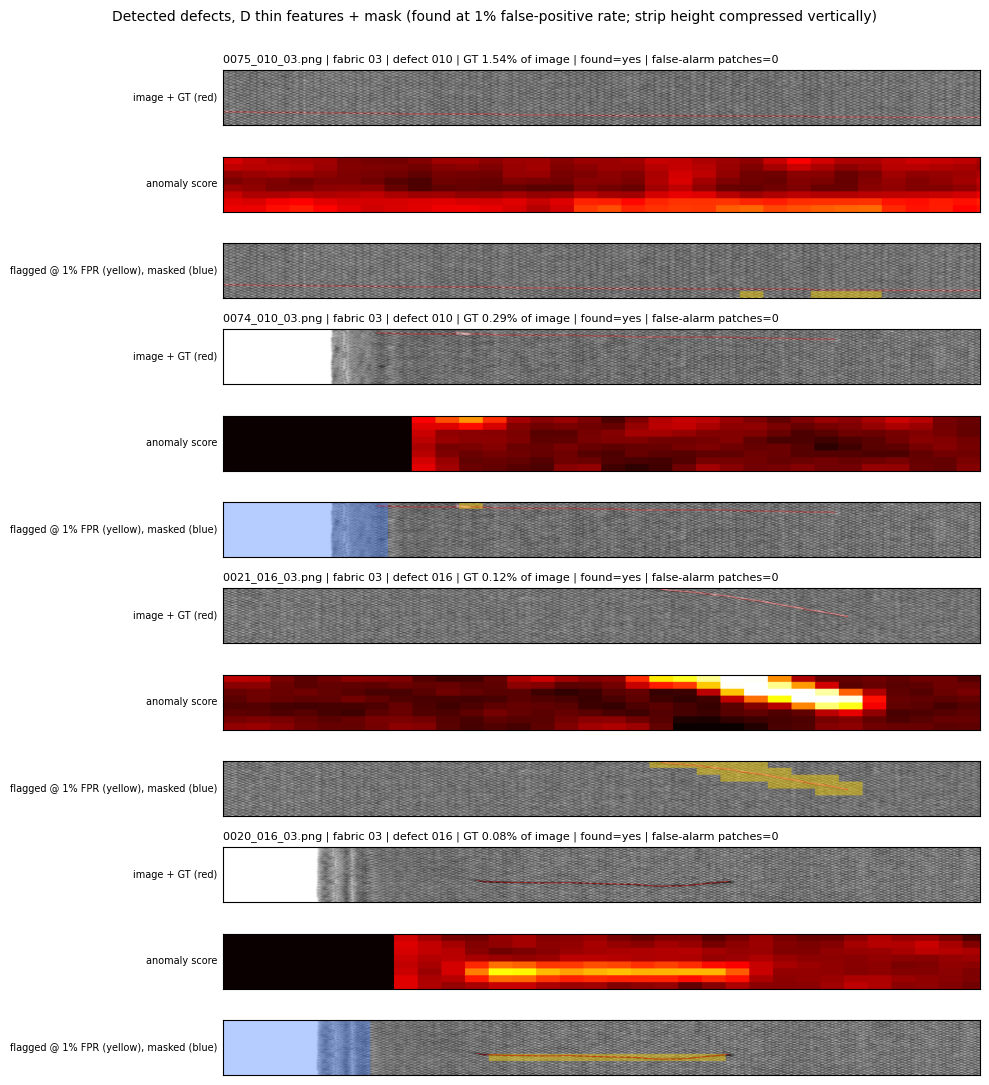

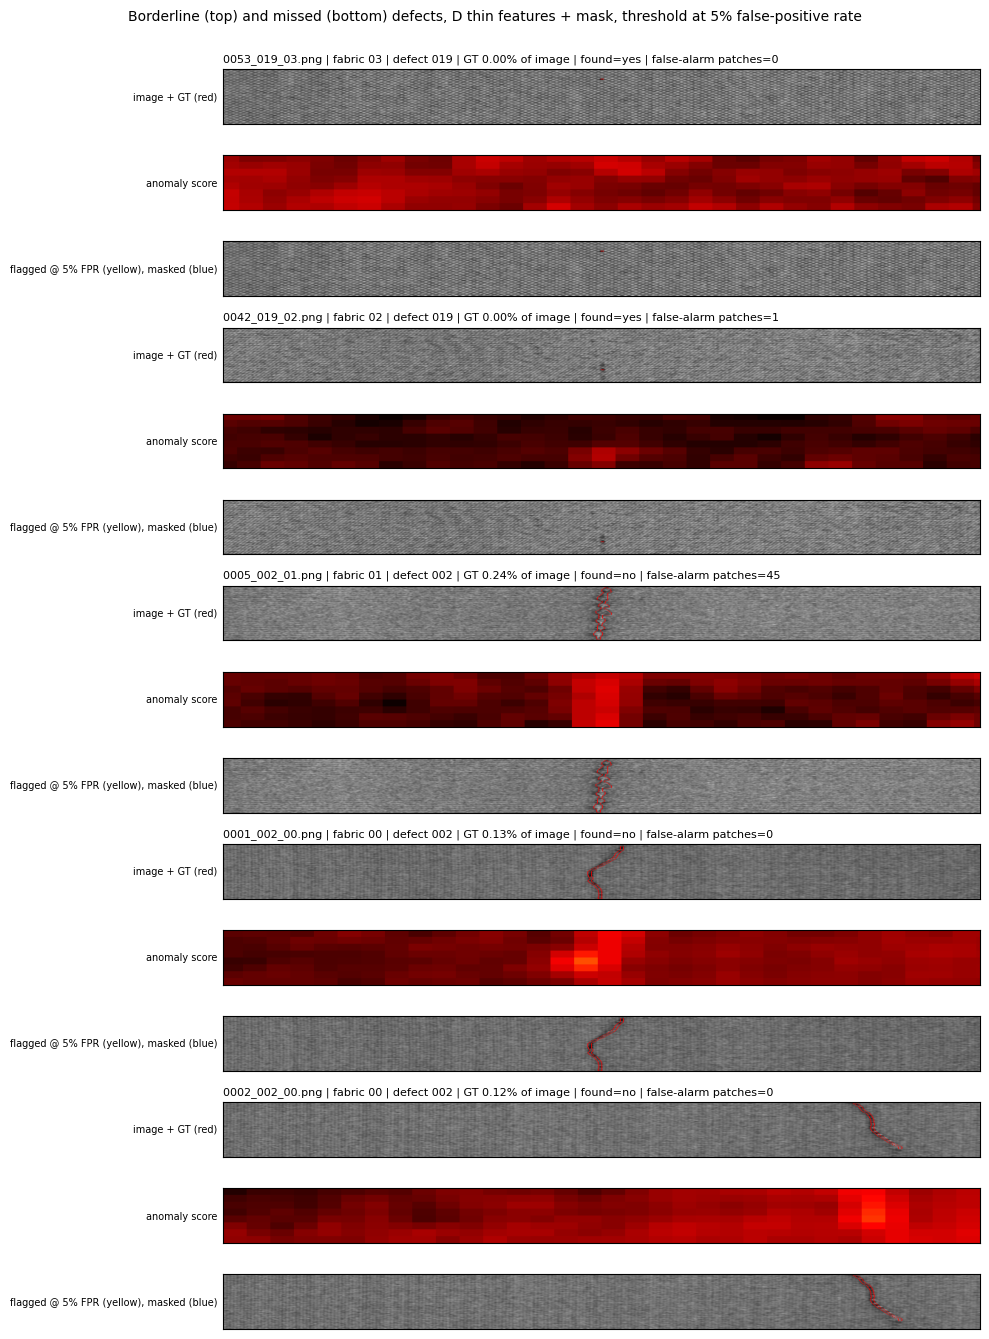

saved final_detected.png and final_borderline_missed.png in /kaggle/working


In [14]:
# =============================================================================
# WEEK 7 — FREEZE STEP: final configuration -> report-ready tables + example figures
# Run AFTER cells K1, K2 and K3 of week7_pipeline.py in the SAME session (it reuses RUN, boot, KEYS, T, ...).
#
# Produces, in /kaggle/working:
#   week7_tables.tex            LaTeX tables (comparison + paired differences) to paste into the report
#   final_per_image.csv         one row per image: found@1%, found@5%, false alarms, top-k, image score ...
#   final_detected.png          cleanest detections (found at 1% FPR, fewest false alarms)
#   final_borderline_missed.png borderline (found only at 5% FPR) and biggest missed defects
# Examples are chosen by FIXED RULES (printed), not by hand. Masked zones are shown in blue.
# =============================================================================


# %% [CELL F1] — Choose the final configuration, export tables and per-image results
import os
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

CHOSEN = "D thin features + mask"      # one of: "A baseline", "B + margin/edge mask", "C thin-defect features", "D thin features + mask"
need = ["RUN", "boot", "KEYS", "T", "IMG", "GRID", "MASKS", "fab_img", "fab_patch", "clean", "ov", "OUT", "PATCH", "STRIDE", "N", "def_img"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run K1, K2 and K3 of week7_pipeline.py first in this session (missing: {miss})"
assert CHOSEN in RUN, f"CHOSEN must be one of {list(RUN)}"
zc, validc, dfi = RUN[CHOSEN]["z"], RUN[CHOSEN]["valid"], RUN[CHOSEN]["img"]

# ---- LaTeX export ----
def tex_escape(x):
    return str(x).replace("%", "\\%").replace("±", "$\\pm$").replace("&", "\\&").replace("_", "\\_").replace("#", "\\#")
def tabular(df, caption, label, colfmt=None, resize=True):
    cols = list(df.columns); colfmt = colfmt or ("l" + "c" * (len(cols) - 1))
    lines = ["\\begin{table}[!ht]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\small"]
    if resize: lines.append("\\resizebox{\\linewidth}{!}{%")
    lines += [f"\\begin{{tabular}}{{{colfmt}}}", "\\toprule", " & ".join(tex_escape(c) for c in cols) + " \\\\", "\\midrule"]
    for _, r in df.iterrows(): lines.append(" & ".join(tex_escape(v) for v in r.values) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}" + ("}" if resize else ""), "\\end{table}", ""]
    return "\n".join(lines)

comp = T.copy(); comp.columns = [c.replace("patches used %", "patches used (%)") for c in comp.columns]
rows = []
for n in list(RUN)[1:]:
    r = {"configuration": n}
    for k in KEYS:
        d = np.array(boot[n][k]) - np.array(boot["A baseline"][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5])
        r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}]" + (" *" if (lo > 0 or hi < 0) else "")
    rows.append(r)
paired = pd.DataFrame(rows)
with open(f"{OUT}/week7_tables.tex", "w") as fh:
    fh.write(tabular(comp, "Consistent comparison of four configurations on all 103 defective and 141 defect-free images (image-level cross-validation, per-fabric models and thresholds). Brackets: 95\\% CI from resampling images.", "tab:w7comp"))
    fh.write(tabular(paired, "Difference to the baseline (median and 95\\% CI over paired image-bootstrap resamples); $*$ = interval excludes 0.", "tab:w7paired"))
print("wrote", f"{OUT}/week7_tables.tex", "(paste into the report; each table has a \\label)")

# ---- per-image results for the chosen configuration ----
E = dfi.copy(); E.insert(0, "image", [os.path.basename(s) for s, _, _ in IMG]); E["path"] = [s for s, _, _ in IMG]
E["st"] = [st for _, st, _ in IMG]; E["c"] = [c for _, _, c in IMG]
E["defect_type"] = [def_img[s] for s, _, _ in IMG]; E["area_pct"] = [(MASKS[s].mean() * 100) if s in MASKS else np.nan for s, _, _ in IMG]
E.drop(columns=["path", "st", "c"]).to_csv(f"{OUT}/final_per_image.csv", index=False)
D = E[E.has_gt]
print(f"\nCHOSEN = {CHOSEN}: found at 1% FPR {D.found1.mean():.3f} ({int(D.found1.sum())}/{len(D)}), at 5% FPR {D.found5.mean():.3f} ({int(D.found5.sum())}/{len(D)}); "
      f"mean false-alarm patches per image at 1% FPR: {E.fa1.mean():.1f}")
bt = D.groupby("defect_type").agg(images=("image", "count"), recall_1pct=("found1", "mean"), recall_5pct=("found5", "mean"), mean_area_pct=("area_pct", "mean")).round(3)
print("\nDetection by defect type (chosen configuration):"); print(bt.sort_values("images", ascending=False).to_string())
bt.to_csv(f"{OUT}/final_by_defect_type.csv")


# %% [CELL F2] — Example figures for the report (fixed selection rules, masked zones in blue)
THR1 = {f: np.quantile(zc[(fab_patch == f) & clean & validc], 0.99) for f in np.unique(fab_patch)}
THR5 = {f: np.quantile(zc[(fab_patch == f) & clean & validc], 0.95) for f in np.unique(fab_patch)}
det = D[D.found1 == 1].sort_values(["fa1", "area_pct"], ascending=[True, False]).head(4)
bord = D[(D.found1 == 0) & (D.found5 == 1)].sort_values("fa5").head(2)
mis = D[D.found5 == 0].sort_values("area_pct", ascending=False).head(3)
print("RULES: detected = found at 1% FPR with the fewest false-alarm patches; borderline = found only at 5% FPR, fewest false alarms; "
      "missed = not found even at 5% FPR, largest defect area.")
print(f"available: detected={int((D.found1==1).sum())}  borderline={int(((D.found1==0)&(D.found5==1)).sum())}  missed={int((D.found5==0).sum())}")

def paint(s, values):
    R, C, H, W = GRID[s]; acc = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); k = 0
    for r in range(R):
        for cc in range(C):
            y, x = r * STRIDE, cc * STRIDE; acc[y:y + PATCH, x:x + PATCH] += values[k]; cnt[y:y + PATCH, x:x + PATCH] += 1; k += 1
    cnt[cnt == 0] = 1; return acc / cnt

def draw(df, thr, q, fname, title):
    if len(df) == 0: print("no examples for", title); return
    n = len(df); fig, axes = plt.subplots(3 * n, 1, figsize=(10, 0.85 * 3 * n + 0.6)); axes = np.atleast_1d(axes)
    vmax = float(np.nanpercentile(zc[validc], 99.7))
    for e, (_, r) in enumerate(df.iterrows()):
        s, st, c = r["path"], r["st"], r["c"]; R, C, H, W = GRID[s]; f = fab_img[s]
        im = cv2.imread(s, cv2.IMREAD_GRAYSCALE); im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
        v = validc[st:st + c]; zz = zc[st:st + c]
        heat = paint(s, np.where(v, zz, np.nan)); heat = np.nan_to_num(heat, nan=-2.0)
        fl = paint(s, ((zz > thr[f]) & v).astype(np.float32)) > 0.5; mk = paint(s, (~v).astype(np.float32)) > 0.5
        ys, xs = np.nonzero(MASKS[s]); cx = int(xs.mean()) if len(xs) else W // 2; wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd))
        sl = (slice(None), slice(x0, x0 + wd)); cnt_, _ = cv2.findContours(MASKS[s][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB); a = rgb.copy()
        a[mk[sl]] = (0.6 * a[mk[sl]] + 0.4 * np.array([70, 130, 255])).astype(np.uint8)            # masked zone = blue
        a[fl[sl]] = (0.55 * a[fl[sl]] + 0.45 * np.array([255, 215, 0])).astype(np.uint8)            # flagged = yellow
        for panel in (rgb, a): cv2.drawContours(panel, cnt_, -1, (255, 0, 0), 1)                    # ground truth = red outline
        ax = axes[3 * e:3 * e + 3]
        ax[0].imshow(rgb, aspect="auto"); ax[1].imshow(heat[sl], cmap="hot", vmin=-2, vmax=vmax, aspect="auto"); ax[2].imshow(a, aspect="auto")
        for k, lab in enumerate(["image + GT (red)", "anomaly score", f"flagged @ {int(q*100)}% FPR (yellow), masked (blue)"]):
            ax[k].set_yticks([]); ax[k].set_xticks([]); ax[k].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=7)
        ax[0].set_title(f"{r['image']} | fabric {f} | defect {r['defect_type']} | GT {r['area_pct']:.2f}% of image | "
                        f"found={'yes' if r[f'found{int(q*100)}'] == 1 else 'no'} | false-alarm patches={int(r[f'fa{int(q*100)}'])}", fontsize=8, loc="left")
    fig.suptitle(title, fontsize=10, y=1.0); plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=200, bbox_inches="tight"); plt.show()

draw(det, THR1, 0.01, "final_detected.png", f"Detected defects, {CHOSEN} (found at 1% false-positive rate; strip height compressed vertically)")
draw(pd.concat([bord, mis]), THR5, 0.05, "final_borderline_missed.png", f"Borderline (top) and missed (bottom) defects, {CHOSEN}, threshold at 5% false-positive rate")
print("saved final_detected.png and final_borderline_missed.png in", OUT)

In [15]:
# =============================================================================
# SMALL-PATCH EXPERIMENT — do 32x32 patches (stride 16) see the thin defects that 64x64 patches miss?
# Run AFTER cells K1, K2 and K3 of week7_pipeline.py (the version with the corrected margin mask) in the SAME session.
# It reuses RUN, boot, metrics(), B_RES from K2/K3, so the new configurations are compared PAIRED with the 64x64 ones.
#
#   E  32x32 patches, no mask       F  32x32 patches + the same margin mask
# Features per 32x32 patch (34): for each of the 8 Gabor maps mean, variance and max |response| (24)
#                                + 4 radial FFT bands, mean and std (8) + column/row profile spread (2).
# Fair-comparison notes:
#   * nominal false-positive rate per patch is the same (1% / 5%); a 32 px patch covers 1/4 of the area of a 64 px patch and there are
#     about 4.3x as many patches, so the false-alarm AREA is roughly comparable (false-alarm patch COUNTS are not).
#   * the localization test uses the top-40 patches here (top-10 for 64 px patches): the same total area.
# Cells: SP1 (features, a few minutes) -> SP2 (evaluation) -> SP3 (comparison table with paired CIs)
# =============================================================================


# %% [CELL SP1] — 32x32 / stride-16 features, overlap with the ground truth, margin mask
import os, time
from collections import defaultdict
import numpy as np, pandas as pd, cv2
from joblib import Parallel, delayed
from scipy import ndimage as ndi
from scipy.stats import hypergeom
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler

need = ["RUN", "boot", "KEYS", "metrics", "B_RES", "IMG", "MASKS", "dindex", "fab_img", "is_def_img", "srcs",
        "SEEDS", "K_FOLDS", "MIN_TRAIN", "OUT", "G_KERNELS", "margin_columns", "idx_d", "idx_n"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run W1, W2 and K1-K3 of week7_pipeline.py first (missing: {miss})"
P2, S2 = 32, 16
KTOP2 = 40                                                                     # same total area as top-10 at 64 px
BANDS2 = [(0, 2), (2, 5), (5, 10), (10, 32)]
_yy, _xx = np.mgrid[0:P2, 0:P2]; _r = np.sqrt((_yy - P2 // 2) ** 2 + (_xx - P2 // 2) ** 2)
BANDM = np.stack([((_r >= lo) & (_r < hi)).ravel() for lo, hi in BANDS2]).astype(np.float32); BANDM /= BANDM.sum(1, keepdims=True)

def sp_worker(path, mask_path):
    im0 = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im0), (3, 3), 0)    # same preprocessing as the cache
    f = im.astype(np.float32) / 255.0; H, W = f.shape; R = (H - P2) // S2 + 1; C = (W - P2) // S2 + 1
    sel = (slice(P2 // 2, P2 // 2 + S2 * R, S2), slice(P2 // 2, P2 // 2 + S2 * C, S2))                    # window centres of a (P2 x P2) window
    feats = []
    for k in G_KERNELS:
        m = cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101)
        mu = cv2.boxFilter(m, -1, (P2, P2), normalize=True)[sel]; sq = cv2.boxFilter(m * m, -1, (P2, P2), normalize=True)[sel]
        mx = cv2.dilate(np.abs(m), np.ones((P2, P2), np.uint8))[sel]
        feats += [mu, np.maximum(sq - mu * mu, 0), mx]                                                      # 3 x 8 maps = 24
    win = sliding_window_view(f, (P2, P2))[::S2, ::S2][:R, :C]                                              # (R, C, 32, 32)
    flat = win.reshape(R * C, P2, P2)
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(flat), axes=(-2, -1)))).reshape(R * C, -1).astype(np.float32)
    bm = mag @ BANDM.T; bs = np.sqrt(np.maximum((mag * mag) @ BANDM.T - bm * bm, 0))                          # 4 + 4 = 8
    prof = np.stack([win.mean(axis=2).std(axis=-1).ravel(), win.mean(axis=3).std(axis=-1).ravel()], 1)       # 2
    F = np.concatenate([np.stack([x.ravel() for x in feats], 1), bm, bs, prof], 1).astype(np.float32)
    ovf = np.zeros(R * C, np.float32)
    if mask_path:
        mk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mk is not None:
            if mk.shape != im0.shape: mk = cv2.resize(mk, (W, H), interpolation=cv2.INTER_NEAREST)
            ii = cv2.integral((mk > 0).astype(np.uint8)); Y, X = np.meshgrid(np.arange(0, H - P2 + 1, S2), np.arange(0, W - P2 + 1, S2), indexing="ij")
            ovf = ((ii[Y + P2, X + P2] - ii[Y, X + P2] - ii[Y + P2, X] + ii[Y, X]) / (P2 * P2)).ravel().astype(np.float32)
    m_cols = margin_columns(im0); cs = np.r_[0, np.cumsum(m_cols)]; x0 = np.arange(C) * S2
    valid = np.tile(~((cs[x0 + P2] - cs[x0]) > 0), R)                                                         # same margin rule as the 64 px version
    return F, ovf, valid, (R, C, H, W)

t0 = time.time()
res = Parallel(n_jobs=-1)(delayed(sp_worker)(s, (dindex.get(s) if (is_def_img[s] and isinstance(dindex.get(s), str)) else None)) for s, _, _ in IMG)
F2 = np.vstack([r[0] for r in res]); OV2 = np.concatenate([r[1] for r in res]); VALID2 = np.concatenate([r[2] for r in res]); GRID2 = {}
IMG2 = []; st = 0
for (s, _, _), r in zip(IMG, res):
    n = len(r[1]); IMG2.append((s, st, n)); GRID2[s] = r[3]; st += n
N2 = len(F2); PC2 = np.array([c for _, _, c in IMG2]); fab2 = np.repeat([fab_img[s] for s, _, _ in IMG2], PC2)
clean2 = OV2 == 0; yany2 = OV2 > 0
print(f"features done in {time.time()-t0:.0f}s | {N2} patches of {P2}x{P2} (stride {S2}), {F2.shape[1]} features | "
      f"defect patches {int(yany2.sum())} ({yany2.mean()*100:.2f}%) | masked {(~VALID2).mean()*100:.1f}% | "
      f"defect patches lost to the mask {int((yany2 & ~VALID2).sum())} ({(yany2 & ~VALID2).sum()/max(yany2.sum(),1)*100:.1f}%)")


# %% [CELL SP2] — Evaluate E and F (same measures as K2)
def _fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9
    return sc, lw, med, mad
def _apply(m, X):
    sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
def _folds2(seed):
    rng = np.random.RandomState(seed); fold = {}; ctr = 0; groups = defaultdict(list)
    for s in srcs: groups[(fab_img[s], is_def_img[s])].append(s)
    for key in sorted(groups):
        g = groups[key]; rng.shuffle(g)
        for j, s in enumerate(g): fold[s] = (ctr + j) % K_FOLDS
        ctr += len(g)
    return np.repeat([fold[s] for s, _, _ in IMG2], PC2)

def outcomes2(z, valid):
    fabs = np.unique(fab2); t = {q: {f: np.quantile(z[(fab2 == f) & clean2 & valid], 1 - q) for f in fabs} for q in (0.01, 0.05)}; rows = []
    for s, st, c in IMG2:
        zz, v, o = z[st:st + c], valid[st:st + c], OV2[st:st + c] > 0; f = fab_img[s]; d = bool(is_def_img[s])
        fl1, fl5 = (zz > t[0.01][f]) & v, (zz > t[0.05][f]) & v
        r = {"defective": d, "fabric": f, "has_gt": bool(d and o.any()), "fa1": int((fl1 & ~o).sum()), "fa5": int((fl5 & ~o).sum()),
             "share5": float(fl5.sum() / max(v.sum(), 1)), "found1": np.nan, "found5": np.nan, "top1": np.nan, "top10": np.nan, "chance1": np.nan, "chance10": np.nan}
        if r["has_gt"]:
            ov_ = o & v; r["found1"] = float((fl1 & o).any()); r["found5"] = float((fl5 & o).any())
            if ov_.any():
                order = np.argsort(-np.where(v, zz, -np.inf)); hit = ov_[order]; n_, m_ = int(v.sum()), int(ov_.sum())
                r["top1"] = float(hit[:1].any()); r["chance1"] = float(1 - hypergeom.pmf(0, n_, m_, 1))
                r["top10"] = float(hit[:KTOP2].any()); r["chance10"] = float(1 - hypergeom.pmf(0, n_, m_, KTOP2))      # 'top10' = top-40 here (equal area)
            else: r["top1"] = r["top10"] = 0.0; r["chance1"] = r["chance10"] = 0.0
        rows.append(r)
    return pd.DataFrame(rows)

CONF2 = {"E 32px patches": np.ones(N2, bool), "F 32px patches + mask": VALID2}; RUN2 = {}
for name, valid in CONF2.items():
    t0 = time.time(); aps, aucs, z0 = [], [], None
    for seed in SEEDS[:1]:                                            # one seed keeps this tractable (933k patches)
        fold = _folds2(seed); z = np.full(N2, np.nan)
        for k in range(K_FOLDS):
            te = fold == k; tr = (~te) & clean2 & valid; pooled = _fit(F2[tr])
            for f in np.unique(fab2[te]):
                tef, trf = te & (fab2 == f), tr & (fab2 == f)
                z[tef] = _apply(_fit(F2[trf]) if trf.sum() >= MIN_TRAIN else pooled, F2[tef])
            m = te & valid
            if 0 < yany2[m].sum() < m.sum(): aps.append(average_precision_score(yany2[m], z[m])); aucs.append(roc_auc_score(yany2[m], z[m]))
        z0 = z
    RUN2[name] = {"AP": np.array(aps), "AUC": np.array(aucs), "img": outcomes2(z0, valid), "valid": valid}
    print(f"{name:24s} done in {time.time()-t0:.0f}s | AP(relaxed) {np.mean(aps):.3f} | patch AUC {np.mean(aucs):.3f}")


# %% [CELL SP3] — Paired comparison with the 64 px configurations
rng = np.random.RandomState(0); boot2 = {n: {k: [] for k in KEYS} for n in RUN2}
for _ in range(B_RES):                                                # identical resampling sequence to K3 -> paired with `boot`
    ii_d = rng.choice(idx_d, len(idx_d)); ii_n = rng.choice(idx_n, len(idx_n))
    for n in RUN2:
        m = metrics(RUN2[n]["img"], ii_d, ii_n)
        for k in KEYS: boot2[n][k].append(m[k])
ALLB = {**boot, **boot2}; ALLR = {**RUN, **RUN2}; rows = []
for n in ALLR:
    pt = metrics(ALLR[n]["img"], idx_d, idx_n); r = {"configuration": n, "AP (relaxed)": f"{ALLR[n]['AP'].mean():.3f}±{ALLR[n]['AP'].std():.3f}"}
    for k in KEYS:
        lo, hi = np.percentile(ALLB[n][k], [2.5, 97.5]); r[k] = f"{pt[k]:.3f} [{lo:.3f},{hi:.3f}]"
    rows.append(r)
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 40)
print("COMPARISON (64 px: A-D from K3; 32 px: E, F).  'top-10 hit' = top-10 patches at 64 px, top-40 at 32 px (equal area)")
print(pd.DataFrame(rows).to_string(index=False))
print("\nPAIRED DIFFERENCE of the 32 px configurations vs 'A baseline' and vs 'D thin features + mask' (median [95% CI]; * = excludes 0)")
rows = []
for n in RUN2:
    for ref in ("A baseline", "D thin features + mask"):
        r = {"configuration": n, "vs": ref.split(" ")[0]}
        for k in KEYS:
            d = np.array(boot2[n][k]) - np.array(boot[ref][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5]); r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}]" + (" *" if (lo > 0 or hi < 0) else "")
        rows.append(r)
print(pd.DataFrame(rows).to_string(index=False))
print("\nDECISION RULE (as before): adopt only if >= 2 measures improve with a CI excluding 0 and none gets reliably worse. "
      "Otherwise report the 32 px result as 'tested, comparable' and keep the 64 px configuration.")

features done in 46s | 546690 patches of 32x32 (stride 16), 34 features | defect patches 5080 (0.93%) | masked 11.1% | defect patches lost to the mask 41 (0.8%)
E 32px patches           done in 9s | AP(relaxed) 0.146 | patch AUC 0.879
F 32px patches + mask    done in 8s | AP(relaxed) 0.197 | patch AUC 0.885
COMPARISON (64 px: A-D from K3; 32 px: E, F).  'top-10 hit' = top-10 patches at 64 px, top-40 at 32 px (equal area)
         configuration AP (relaxed)           recall@1%           recall@5%              FA/img@1%           top-1 hit          top-10 hit           image AUC image recall@10%FPR
            A baseline  0.145±0.195 0.167 [0.097,0.233] 0.353 [0.257,0.453]   8.762 [6.360,11.634] 0.108 [0.050,0.175] 0.216 [0.132,0.294] 0.721 [0.624,0.809] 0.301 [0.087,0.602]
  B + margin/edge mask  0.179±0.212 0.245 [0.166,0.327] 0.412 [0.317,0.510]   7.762 [5.293,10.817] 0.206 [0.137,0.287] 0.363 [0.272,0.456] 0.714 [0.617,0.802] 0.340 [0.097,0.558]
C thin-defect features  0.157±0.216 0.

check passed: z reproduces the stored results for F 32px patches + mask
wrote /kaggle/working/final_f_tables.tex

F 32px patches + mask: defect found at 1% FPR 0.343 (35/102), at 5% FPR 0.735 (75/102); false-alarm patches/img at 1% FPR: 33.6 (= 34k px of a 1,049k px strip)

Detection by defect type:
             images  recall_1pct  recall_5pct  mean_area_pct
defect_type                                                 
019              38        0.132        0.526          0.003
030              13        0.231        0.692          0.015
002               9        0.000        0.889          0.100
010               9        1.000        1.000          2.300
022               9        0.333        0.667          0.029
006               8        1.000        1.000          0.191
025               5        0.200        1.000          0.002
023               5        0.200        1.000          0.087
016               3        1.000        1.000          0.078
027               1        1

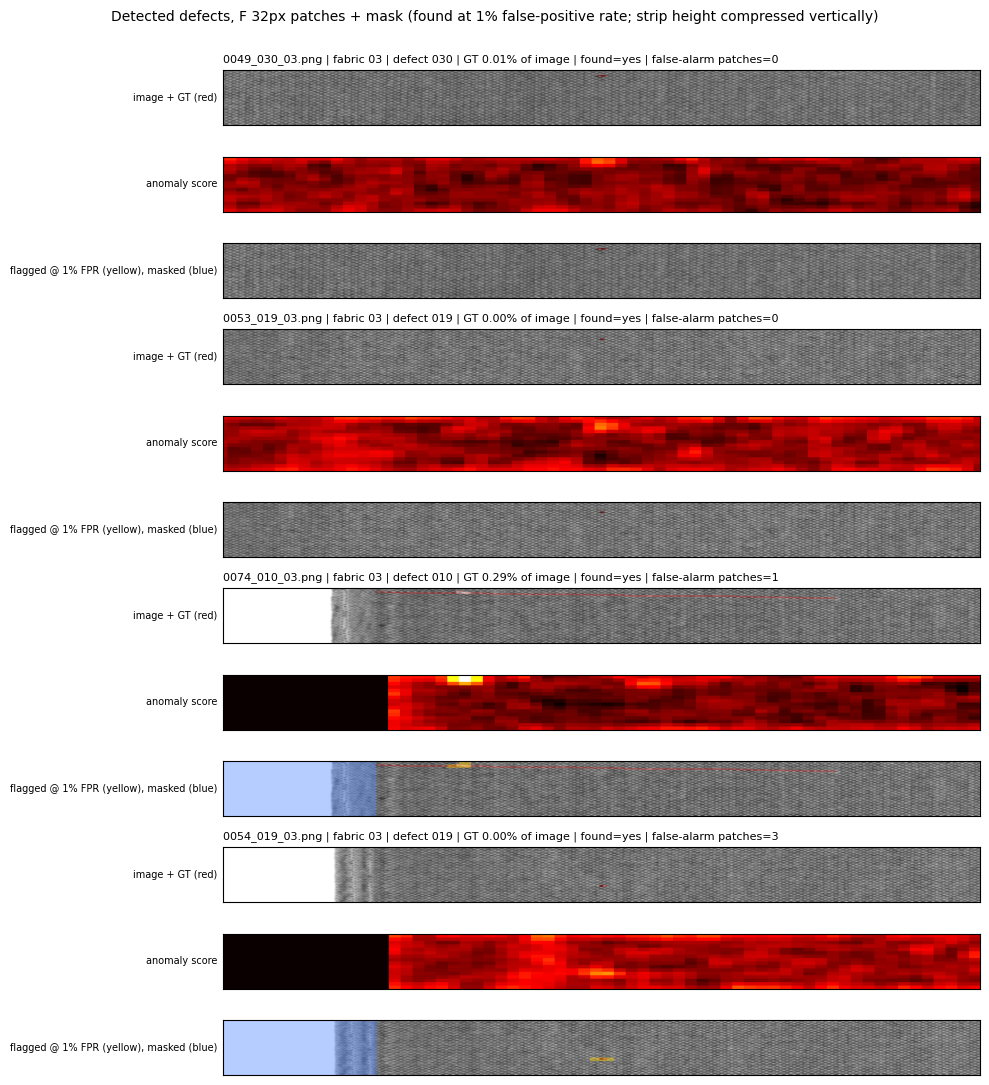

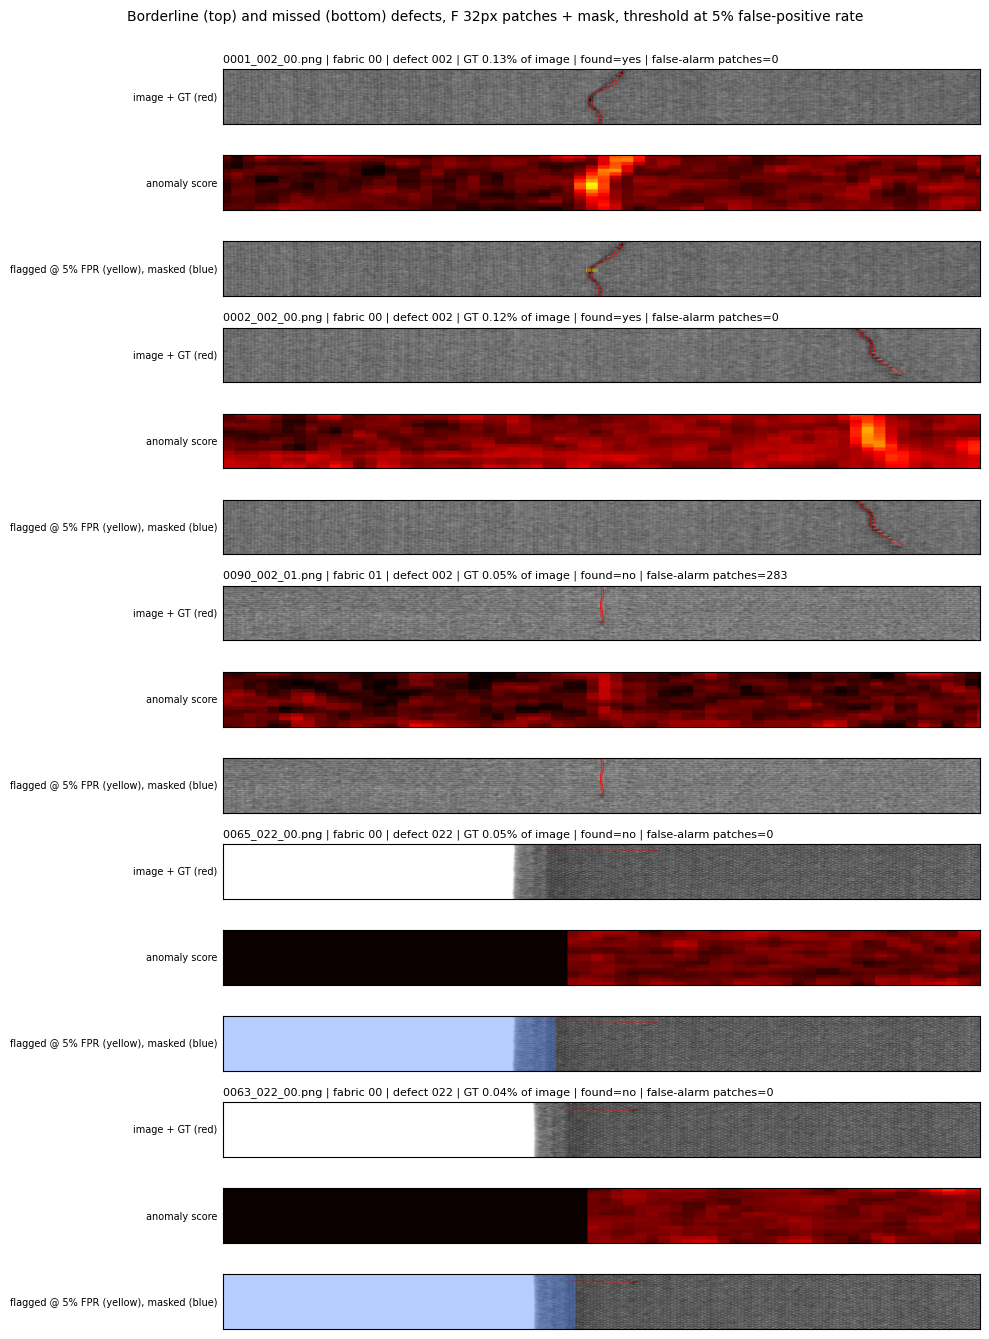

saved final_f_detected.png and final_f_borderline_missed.png in /kaggle/working


In [16]:
# =============================================================================
# FINAL STEP FOR THE 32x32 CONFIGURATION ("F 32px patches + mask")
# Run AFTER cells SP1, SP2 and SP3 of smallpatch_experiment.py in the SAME session.
# If your SP2 was run with an OLDER version of the file, first run this single line (before anything else overwrites z):
#       assert z.shape == (N2,); RUN2["F 32px patches + mask"]["z"] = z
#
# Produces in /kaggle/working:
#   final_f_tables.tex             LaTeX tables for all six configurations (comparison + paired differences)
#   final_f_per_image.csv          one row per image
#   final_f_by_defect_type.csv     detection by true defect-type code
#   final_f_detected.png           cleanest detections (found at 1% FPR, fewest false alarms)
#   final_f_borderline_missed.png  borderline (found only at 5% FPR) and largest missed defects
# Examples are chosen by FIXED RULES (printed). Masked zones are shown in blue; ground truth is outlined in red.
# =============================================================================


# %% [CELL FF1] — Tables and per-image results
import os
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt

CH = "F 32px patches + mask"
need = ["RUN", "RUN2", "boot", "boot2", "ALLB", "ALLR", "KEYS", "metrics", "idx_d", "idx_n", "IMG2", "GRID2", "MASKS", "fab_img", "fab2",
        "clean2", "OV2", "OUT", "P2", "S2", "def_img", "N2", "outcomes2", "is_def_img"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run SP1-SP3 of smallpatch_experiment.py first (missing: {miss})"
validc = RUN2[CH]["valid"]
zc = RUN2[CH].get("z") if "z" in RUN2[CH] else (z if "z" in globals() else None)
assert zc is not None and np.shape(zc) == (N2,), "scores for F are not available: run  RUN2['F 32px patches + mask']['z'] = z  right after SP2"
chk = outcomes2(zc, validc)
assert abs(chk.found1.mean() - RUN2[CH]["img"].found1.mean()) < 1e-9, "z does not belong to configuration F (it was overwritten); re-run SP2"
print("check passed: z reproduces the stored results for", CH)

def tex_escape(x): return str(x).replace("%", "\\%").replace("±", "$\\pm$").replace("&", "\\&").replace("_", "\\_").replace("#", "\\#")
def tabular(df, caption, label):
    cols = list(df.columns); L = ["\\begin{table}[!ht]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\small", "\\resizebox{\\linewidth}{!}{%",
                                  "\\begin{tabular}{l" + "c" * (len(cols) - 1) + "}", "\\toprule", " & ".join(tex_escape(c) for c in cols) + " \\\\", "\\midrule"]
    for _, r in df.iterrows(): L.append(" & ".join(tex_escape(v) for v in r.values) + " \\\\")
    return "\n".join(L + ["\\bottomrule", "\\end{tabular}}", "\\end{table}", ""])

rows = []
for n in ALLR:
    pt = metrics(ALLR[n]["img"], idx_d, idx_n); r = {"configuration": n, "AP (relaxed)": f"{ALLR[n]['AP'].mean():.3f}±{ALLR[n]['AP'].std():.3f}"}
    for k in KEYS:
        lo, hi = np.percentile(ALLB[n][k], [2.5, 97.5]); r[k] = f"{pt[k]:.3f} [{lo:.3f},{hi:.3f}]"
    rows.append(r)
comp = pd.DataFrame(rows)
def paired_rows(names, ref):
    out = []
    for n in names:
        r = {"configuration": n}
        for k in KEYS:
            d = np.array(ALLB[n][k]) - np.array(ALLB[ref][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5]); r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}]" + (" *" if (lo > 0 or hi < 0) else "")
        out.append(r)
    return pd.DataFrame(out)
pa = paired_rows([n for n in ALLR if n != "A baseline"], "A baseline")
pd_ = paired_rows([n for n in ALLR if n not in ("A baseline", "D thin features + mask")], "D thin features + mask")
with open(f"{OUT}/final_f_tables.tex", "w") as fh:
    fh.write(tabular(comp, "Comparison of six configurations on all 103 defective and 141 defect-free images (image-level cross-validation, per-fabric models and thresholds); brackets: 95\\% CI from resampling images. The top-10 hit rate uses the top-10 patches for 64 px and the top-40 patches for 32 px (equal area); false-alarm patch counts are not comparable between patch sizes.", "tab:fcomp"))
    fh.write(tabular(pa, "Difference to the 64 px baseline A (median and 95\\% CI over paired image-bootstrap resamples); $*$ = interval excludes 0.", "tab:fvsA"))
    fh.write(tabular(pd_, "Difference to configuration D (64 px, thin features, mask); $*$ = interval excludes 0.", "tab:fvsD"))
print("wrote", f"{OUT}/final_f_tables.tex")

E = RUN2[CH]["img"].copy(); E.insert(0, "image", [os.path.basename(s) for s, _, _ in IMG2]); E["path"] = [s for s, _, _ in IMG2]
E["st"] = [st for _, st, _ in IMG2]; E["c"] = [c for _, _, c in IMG2]; E["defect_type"] = [def_img[s] for s, _, _ in IMG2]
E["area_pct"] = [(MASKS[s].mean() * 100) if s in MASKS else np.nan for s, _, _ in IMG2]
E.drop(columns=["path", "st", "c"]).to_csv(f"{OUT}/final_f_per_image.csv", index=False); D = E[E.has_gt]
print(f"\n{CH}: defect found at 1% FPR {D.found1.mean():.3f} ({int(D.found1.sum())}/{len(D)}), at 5% FPR {D.found5.mean():.3f} ({int(D.found5.sum())}/{len(D)}); "
      f"false-alarm patches/img at 1% FPR: {E.fa1.mean():.1f} (= {E.fa1.mean()*P2*P2/1000:.0f}k px of a 1,049k px strip)")
bt = D.groupby("defect_type").agg(images=("image", "count"), recall_1pct=("found1", "mean"), recall_5pct=("found5", "mean"), mean_area_pct=("area_pct", "mean")).round(3)
print("\nDetection by defect type:"); print(bt.sort_values("images", ascending=False).to_string()); bt.to_csv(f"{OUT}/final_f_by_defect_type.csv")


# %% [CELL FF2] — Example figures
THR1 = {f: np.quantile(zc[(fab2 == f) & clean2 & validc], 0.99) for f in np.unique(fab2)}
THR5 = {f: np.quantile(zc[(fab2 == f) & clean2 & validc], 0.95) for f in np.unique(fab2)}
det = D[D.found1 == 1].sort_values(["fa1", "area_pct"], ascending=[True, False]).head(4)
bord = D[(D.found1 == 0) & (D.found5 == 1)].sort_values("fa5").head(2)
mis = D[D.found5 == 0].sort_values("area_pct", ascending=False).head(3)
print("RULES: detected = found at 1% FPR with the fewest false-alarm patches; borderline = found only at 5% FPR, fewest false alarms; "
      "missed = not found even at 5% FPR, largest defect area.")
print(f"available: detected={int((D.found1==1).sum())}  borderline={int(((D.found1==0)&(D.found5==1)).sum())}  missed={int((D.found5==0).sum())}")

def paint2(s, values):
    R, C, H, W = GRID2[s]; acc = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); k = 0
    for r in range(R):
        for cc in range(C):
            y, x = r * S2, cc * S2; acc[y:y + P2, x:x + P2] += values[k]; cnt[y:y + P2, x:x + P2] += 1; k += 1
    cnt[cnt == 0] = 1; return acc / cnt

def draw2(df, thr, q, fname, title):
    if len(df) == 0: print("no examples for", title); return
    n = len(df); fig, axes = plt.subplots(3 * n, 1, figsize=(10, 0.85 * 3 * n + 0.6)); axes = np.atleast_1d(axes)
    vmax = float(np.nanpercentile(zc[validc], 99.7)); qq = int(q * 100)
    for e, (_, r) in enumerate(df.iterrows()):
        s, st, c = r["path"], r["st"], r["c"]; R, C, H, W = GRID2[s]; f = fab_img[s]
        im = cv2.imread(s, cv2.IMREAD_GRAYSCALE); im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
        v = validc[st:st + c]; zz = zc[st:st + c]
        heat = np.nan_to_num(paint2(s, np.where(v, zz, np.nan)), nan=-2.0)
        fl = paint2(s, ((zz > thr[f]) & v).astype(np.float32)) > 0.5; mk = paint2(s, (~v).astype(np.float32)) > 0.5
        ys, xs = np.nonzero(MASKS[s]); cx = int(xs.mean()) if len(xs) else W // 2; wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd))
        sl = (slice(None), slice(x0, x0 + wd)); cnt_, _ = cv2.findContours(MASKS[s][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB); a = rgb.copy()
        a[mk[sl]] = (0.6 * a[mk[sl]] + 0.4 * np.array([70, 130, 255])).astype(np.uint8); a[fl[sl]] = (0.55 * a[fl[sl]] + 0.45 * np.array([255, 215, 0])).astype(np.uint8)
        for panel in (rgb, a): cv2.drawContours(panel, cnt_, -1, (255, 0, 0), 1)
        ax = axes[3 * e:3 * e + 3]
        ax[0].imshow(rgb, aspect="auto"); ax[1].imshow(heat[sl], cmap="hot", vmin=-2, vmax=vmax, aspect="auto"); ax[2].imshow(a, aspect="auto")
        for k, lab in enumerate(["image + GT (red)", "anomaly score", f"flagged @ {qq}% FPR (yellow), masked (blue)"]):
            ax[k].set_yticks([]); ax[k].set_xticks([]); ax[k].set_ylabel(lab, rotation=0, ha="right", va="center", fontsize=7)
        ax[0].set_title(f"{r['image']} | fabric {f} | defect {r['defect_type']} | GT {r['area_pct']:.2f}% of image | "
                        f"found={'yes' if r[f'found{qq}'] == 1 else 'no'} | false-alarm patches={int(r[f'fa{qq}'])}", fontsize=8, loc="left")
    fig.suptitle(title, fontsize=10, y=1.0); plt.tight_layout(); plt.savefig(f"{OUT}/{fname}", dpi=200, bbox_inches="tight"); plt.show()

draw2(det, THR1, 0.01, "final_f_detected.png", f"Detected defects, {CH} (found at 1% false-positive rate; strip height compressed vertically)")
draw2(pd.concat([bord, mis]), THR5, 0.05, "final_f_borderline_missed.png", f"Borderline (top) and missed (bottom) defects, {CH}, threshold at 5% false-positive rate")
print("saved final_f_detected.png and final_f_borderline_missed.png in", OUT)

helpers ready | seeds (10, 11, 12, 13, 14) | ablation seeds (10, 11, 12) | false-alarm budget (patches per image): 5 (64 px) / 20 (32 px), equal area
seed 10 done (25s)
seed 11 done (51s)
seed 12 done (75s)
seed 13 done (102s)
seed 14 done (125s)

TABLE 1  Configurations A-F, averaged over seeds (10, 11, 12, 13, 14); [95% CI] from the paired image bootstrap (500 resamples)
  configuration           recall@1%           recall@5%       clean find@1%       clean find@5%           top-1 hit          top-10 hit           image AUC image recall@10%FPR FA area@1% (%)
     A baseline 0.175 [0.105,0.240] 0.384 [0.289,0.477] 0.039 [0.007,0.072] 0.002 [0.000,0.006] 0.120 [0.062,0.186] 0.216 [0.131,0.292] 0.709 [0.605,0.801] 0.233 [0.121,0.617]           3.44
     B A + mask 0.229 [0.153,0.312] 0.424 [0.331,0.514] 0.120 [0.061,0.178] 0.055 [0.019,0.091] 0.200 [0.133,0.279] 0.355 [0.261,0.443] 0.707 [0.607,0.800] 0.262 [0.136,0.573]           3.04
C thin features 0.180 [0.108,0.248] 0.367 [0.273,0.

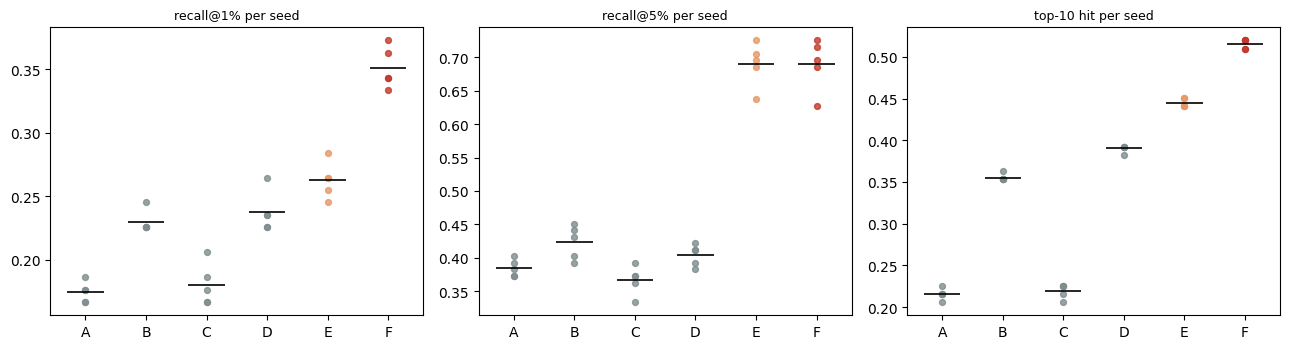

32 px variant done: F full (34 features)
32 px variant done: - Gabor max
32 px variant done: - Gabor mean+var
32 px variant done: - FFT
32 px variant done: - row/col profiles
32 px variant done: Gabor only (24)
32 px variant done: FFT only (8)
32 px variant done: Gabor max only (8)

TABLE 3  Feature-family ablation of the final system (32 px, mask; seeds (10, 11, 12))
       configuration           recall@1%           recall@5%       clean find@1%       clean find@5%           top-1 hit          top-10 hit           image AUC image recall@10%FPR FA area@1% (%)
F full (34 features) 0.359 [0.275,0.450] 0.670 [0.576,0.745] 0.219 [0.150,0.296] 0.049 [0.013,0.091] 0.314 [0.222,0.398] 0.516 [0.424,0.606] 0.713 [0.618,0.802] 0.320 [0.199,0.607]           3.30
         - Gabor max 0.310 [0.223,0.399] 0.582 [0.484,0.660] 0.190 [0.123,0.262] 0.023 [0.003,0.052] 0.278 [0.196,0.363] 0.422 [0.327,0.512] 0.706 [0.612,0.795] 0.311 [0.175,0.602]           3.30
    - Gabor mean+var 0.353 [0.265,0.443] 

In [17]:
# =============================================================================
# WEEK 8 PIPELINE — make the final result solid
#   Day 1  W8-B  Robustness: configurations A-F re-run with FIVE NEW cross-validation seeds (never used before),
#                paired tests of B, C, D, E, F against A (and F against D), per-seed spread
#   Day 2  W8-C  Ablations: (a) which feature family of the final 32 px system matters; (b) which classical descriptor
#                families (GLCM, LBP, Gabor, FFT) matter at 64 px - the justification of the classical choices
#   Day 3  W8-D  Stricter measures (clean find under a false-alarm budget, pixel coverage of the defect) and a fix for
#                high-background images (per-image score normalization), judged by the Week 7 decision rule
#
# RUN AFTER (same session): W1, W2 of week6_pipeline.py;  K1, K2, K3 of week7_pipeline.py;  SP1, SP2, SP3 of smallpatch_experiment.py.
# Seeds: configurations were SELECTED with seed 0 in Week 7; this week uses seeds 10-14, so the final numbers are not the
# ones the choice was made on.  Cells: W8-A (checks, helpers) -> W8-B -> W8-C -> W8-D.   Writes CSV/LaTeX tables to OUT.
# =============================================================================


# %% [CELL W8-A] — Checks and helpers
import os, time
from collections import defaultdict
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

need = ["X_all", "F34", "F2", "VALID", "VALID2", "srcs", "IMG", "IMG2", "GRID", "GRID2", "MASKS", "fab_img", "fab_patch", "fab2", "clean", "clean2",
        "is_def_img", "K_FOLDS", "MIN_TRAIN", "OUT", "PATCH", "STRIDE", "P2", "S2", "image_outcomes", "outcomes2", "_folds", "_folds2", "_fit", "_apply", "N", "N2"]
miss = [n for n in need if n not in globals()]
assert not miss, f"run W1, W2, K1-K3 and SP1-SP3 first in this session (missing: {miss})"
assert len(F2) == N2 and len(F34) == N and len(X_all) == N, "arrays are inconsistent: re-run W1/W2 and K1 after any cache rebuild"

SEEDS8 = (10, 11, 12, 13, 14)          # NEW seeds, not used for any earlier decision
SEEDS_ABL = SEEDS8[:3]                  # ablations use three of them
B_RES8 = 500
BUDGET64, BUDGET32 = 5, 20             # false-alarm budget per image for the 'clean find' measure: 5 x 4096 px = 20 x 1024 px (equal area)
ALLV, ALLV2 = np.ones(N, bool), np.ones(N2, bool)

def cv_z(Xc, valid, clean_, fab_, folds):
    """Out-of-fold anomaly scores: per-fabric Ledoit-Wolf Mahalanobis model fitted on clean, valid training patches."""
    z = np.full(len(Xc), np.nan)
    for k in range(K_FOLDS):
        te = folds == k; tr = (~te) & clean_ & valid; pooled = _fit(Xc[tr])
        for f in np.unique(fab_[te]):
            tef, trf = te & (fab_ == f), tr & (fab_ == f)
            z[tef] = _apply(_fit(Xc[trf]) if trf.sum() >= MIN_TRAIN else pooled, Xc[tef])
    return z

HW = {s: GRID[s][2] * GRID[s][3] for s, _, _ in IMG}
def finish_df(df, grid32):
    """Add the stricter / comparable columns to a per-image outcome table."""
    T = BUDGET32 if grid32 else BUDGET64; pp = (P2 * P2) if grid32 else (PATCH * PATCH); L = IMG2 if grid32 else IMG
    df = df.copy()
    df["clean1"] = np.where(df.has_gt, ((df.found1 == 1) & (df.fa1 <= T)).astype(float), np.nan)
    df["clean5"] = np.where(df.has_gt, ((df.found5 == 1) & (df.fa5 <= T)).astype(float), np.nan)
    df["fa1_area"] = df.fa1.values * pp / np.array([HW[s] for s, _, _ in L]) * 100            # false-alarm area, % of the strip
    return df

def agg_outcomes(dfs):
    base = dfs[0].copy()
    for c in [c for c in base.columns if c not in ("defective", "fabric", "has_gt")]:
        base[c] = np.mean([d[c].astype(float).values for d in dfs], axis=0)
    return base

KEYS8 = ["recall@1%", "recall@5%", "clean find@1%", "clean find@5%", "top-1 hit", "top-10 hit", "image AUC", "image recall@10%FPR"]
def metrics8(df, ii_d, ii_n):
    d = df.iloc[ii_d]; g = d[d.has_gt]; n = df.iloc[ii_n]
    sc = np.r_[d.share5.values, n.share5.values]; y = np.r_[np.ones(len(d)), np.zeros(len(n))]; thr = np.quantile(n.share5.values, 0.90)
    return {"recall@1%": g.found1.mean(), "recall@5%": g.found5.mean(), "clean find@1%": g.clean1.mean(), "clean find@5%": g.clean5.mean(),
            "top-1 hit": g.top1.mean(), "top-10 hit": g.top10.mean(), "image AUC": roc_auc_score(y, sc), "image recall@10%FPR": (d.share5.values > thr).mean(),
            "FA area@1% (%)": df.iloc[np.r_[ii_d, ii_n]].fa1_area.mean()}

def bootstrap(dfs, B=B_RES8, seed=0):
    """Paired image bootstrap: the SAME resamples for every configuration."""
    ref = next(iter(dfs.values())); idx_d_, idx_n_ = np.where(ref.defective)[0], np.where(~ref.defective)[0]; rng = np.random.RandomState(seed)
    keys = KEYS8 + ["FA area@1% (%)"]; out = {n: {k: [] for k in keys} for n in dfs}
    for _ in range(B):
        ii_d = rng.choice(idx_d_, len(idx_d_)); ii_n = rng.choice(idx_n_, len(idx_n_))
        for n, df in dfs.items():
            m = metrics8(df, ii_d, ii_n)
            for k in keys: out[n][k].append(m[k])
    return out, idx_d_, idx_n_

def summary_table(dfs, boots, idx_d_, idx_n_, extra=None):
    rows = []
    for n, df in dfs.items():
        pt = metrics8(df, idx_d_, idx_n_); r = {"configuration": n}
        for k in KEYS8:
            lo, hi = np.percentile(boots[n][k], [2.5, 97.5]); r[k] = f"{pt[k]:.3f} [{lo:.3f},{hi:.3f}]"
        r["FA area@1% (%)"] = f"{pt['FA area@1% (%)']:.2f}"
        if extra and n in extra: r.update(extra[n])
        rows.append(r)
    return pd.DataFrame(rows)

def paired_table(boots, cand, ref, keys=KEYS8):
    rows = []
    for n in cand:
        r = {"configuration": n, "vs": ref}
        for k in keys:
            d = np.array(boots[n][k]) - np.array(boots[ref][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5])
            r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}]" + (" *" if (lo > 0 or hi < 0) else "")
        rows.append(r)
    return pd.DataFrame(rows)

def verdict8(boots, cand, ref):
    better = worse = 0
    for k in KEYS8:
        d = np.array(boots[cand][k]) - np.array(boots[ref][k]); lo, hi = np.percentile(d, [2.5, 97.5])
        better += int(lo > 0); worse += int(hi < 0)
    return better, worse, ("ADOPT" if better >= 2 and worse == 0 else ("REJECT (worse)" if worse > 0 else "comparable, do not adopt"))

def to_tex(df, caption, label):
    esc = lambda x: str(x).replace("%", "\\%").replace("&", "\\&").replace("_", "\\_").replace("#", "\\#")
    cols = list(df.columns); L = ["\\begin{table}[!ht]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}", "\\small", "\\resizebox{\\linewidth}{!}{%",
                                  "\\begin{tabular}{l" + "c" * (len(cols) - 1) + "}", "\\toprule", " & ".join(esc(c) for c in cols) + " \\\\", "\\midrule"]
    for _, r in df.iterrows(): L.append(" & ".join(esc(v) for v in r.values) + " \\\\")
    return "\n".join(L + ["\\bottomrule", "\\end{tabular}}", "\\end{table}", ""])

pd.set_option("display.width", 320); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 38)
TEX = []
print("helpers ready | seeds", SEEDS8, "| ablation seeds", SEEDS_ABL, "| false-alarm budget (patches per image):", BUDGET64, "(64 px) /", BUDGET32, "(32 px), equal area")


# %% [CELL W8-B] — Day 1: configurations A-F with five new seeds, paired tests, per-seed spread
CFG1 = {"A baseline": (X_all[:, 44:68], ALLV, False), "B A + mask": (X_all[:, 44:68], VALID, False), "C thin features": (F34, ALLV, False),
        "D C + mask": (F34, VALID, False), "E 32 px": (F2, ALLV2, True), "F 32 px + mask": (F2, VALID2, True)}
PER = {n: [] for n in CFG1}; Z_FIRST = {}; Z_F = []
t0 = time.time()
for seed in SEEDS8:
    for n, (Xc, valid, g32) in CFG1.items():
        if g32: z = cv_z(Xc, valid, clean2, fab2, _folds2(seed)); df = outcomes2(z, valid)
        else:   z = cv_z(Xc, valid, clean, fab_patch, _folds(seed)); df = image_outcomes(z, valid)
        PER[n].append(finish_df(df, g32))
        if seed == SEEDS8[0] and n in ("A baseline", "D C + mask", "F 32 px + mask"): Z_FIRST[n] = z
        if n == "F 32 px + mask": Z_F.append(z)
    print(f"seed {seed} done ({time.time()-t0:.0f}s)")

AGG1 = {n: agg_outcomes(PER[n]) for n in CFG1}
BOOT1, IDX_D, IDX_N = bootstrap(AGG1)
T1 = summary_table(AGG1, BOOT1, IDX_D, IDX_N)
print(f"\nTABLE 1  Configurations A-F, averaged over seeds {SEEDS8}; [95% CI] from the paired image bootstrap ({B_RES8} resamples)")
print(T1.to_string(index=False)); T1.to_csv(f"{OUT}/week8_table1_configs.csv", index=False)

print("\nPer-seed spread (point estimates per seed; mean ± std over the five seeds):")
rows = []
for n in CFG1:
    r = {"configuration": n}
    for k in ["recall@1%", "recall@5%", "top-10 hit", "image AUC"]:
        v = [metrics8(d, IDX_D, IDX_N)[k] for d in PER[n]]; r[k] = f"{np.mean(v):.3f} ± {np.std(v):.3f}  (min {np.min(v):.3f}, max {np.max(v):.3f})"
    rows.append(r)
T1b = pd.DataFrame(rows); print(T1b.to_string(index=False)); T1b.to_csv(f"{OUT}/week8_table1b_seed_spread.csv", index=False)

P1 = pd.concat([paired_table(BOOT1, [n for n in CFG1 if n != "A baseline"], "A baseline"), paired_table(BOOT1, ["F 32 px + mask", "E 32 px"], "D C + mask")])
print("\nTABLE 2  Paired differences (median [95% CI]; * = interval excludes 0). B and D vs A are the tests that were missing in Week 7.")
print(P1.to_string(index=False)); P1.to_csv(f"{OUT}/week8_table2_paired.csv", index=False)
print("\nDecision rule (>=2 measures reliably better, none reliably worse):")
for n in CFG1:
    if n != "A baseline": print(f"  {n:18s} vs A:", verdict8(BOOT1, n, "A baseline"))
print("  F 32 px + mask     vs D:", verdict8(BOOT1, "F 32 px + mask", "D C + mask"))
TEX += [to_tex(T1, "Configurations A--F averaged over five new cross-validation seeds; brackets: 95\\% CI from a paired image bootstrap.", "tab:w8configs"),
        to_tex(P1, "Paired differences (median and 95\\% CI); $*$ = interval excludes 0.", "tab:w8paired")]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6)); names = list(CFG1); col = ["#7f8c8d"] * 4 + ["#e59866", "#c0392b"]
for a, k in zip(ax, ["recall@1%", "recall@5%", "top-10 hit"]):
    for i, n in enumerate(names):
        v = [metrics8(d, IDX_D, IDX_N)[k] for d in PER[n]]; a.scatter([i] * len(v), v, c=col[i], s=18, alpha=.8); a.hlines(np.mean(v), i - .3, i + .3, colors="k", lw=1.2)
    a.set_xticks(range(6)); a.set_xticklabels([n.split(" ")[0] for n in names]); a.set_title(k + " per seed", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT}/week8_seed_spread.png", dpi=150); plt.show()


# %% [CELL W8-C] — Day 2: ablations
def run_variant(Xc, valid, g32, seeds):
    dfs = []
    for seed in seeds:
        if g32: z = cv_z(Xc, valid, clean2, fab2, _folds2(seed)); dfs.append(finish_df(outcomes2(z, valid), True))
        else:   z = cv_z(Xc, valid, clean, fab_patch, _folds(seed)); dfs.append(finish_df(image_outcomes(z, valid), False))
    return agg_outcomes(dfs)

# (a) Feature families of the final 32 px system (columns of F2: Gabor (mean, var, max) x 8 maps = 0..23, FFT = 24..31, profiles = 32..33)
gm, gv, gx = [3 * k for k in range(8)], [3 * k + 1 for k in range(8)], [3 * k + 2 for k in range(8)]; fft_c, prof_c = list(range(24, 32)), [32, 33]
ALL32 = list(range(34))
V32 = {"F full (34 features)": ALL32,
       "- Gabor max": [c for c in ALL32 if c not in gx], "- Gabor mean+var": gx + fft_c + prof_c, "- FFT": [c for c in ALL32 if c not in fft_c],
       "- row/col profiles": [c for c in ALL32 if c not in prof_c], "Gabor only (24)": list(range(24)), "FFT only (8)": fft_c, "Gabor max only (8)": gx}
AG32 = {}
for n, cols in V32.items():
    AG32[n] = AGG1["F 32 px + mask"] if (n.startswith("F full") and tuple(SEEDS_ABL) == tuple(SEEDS8)) else run_variant(F2[:, cols], VALID2, True, SEEDS_ABL); print("32 px variant done:", n)
BOOT_A32, ID32, IN32 = bootstrap(AG32)
TA = summary_table(AG32, BOOT_A32, ID32, IN32)
print(f"\nTABLE 3  Feature-family ablation of the final system (32 px, mask; seeds {SEEDS_ABL})"); print(TA.to_string(index=False)); TA.to_csv(f"{OUT}/week8_table3_ablation32.csv", index=False)
PA = paired_table(BOOT_A32, [n for n in V32 if not n.startswith("F full")], "F full (34 features)")
print("\nPaired difference to the full feature set (negative * = the removed part mattered):"); print(PA.to_string(index=False)); PA.to_csv(f"{OUT}/week8_table3b_ablation32_paired.csv", index=False)
TEX += [to_tex(TA, "Feature-family ablation of the final $32$ px system with mask (three seeds).", "tab:w8abl32"), to_tex(PA, "Differences to the full feature set; $*$ = interval excludes 0.", "tab:w8abl32p")]

# (b) Classical descriptor families at 64 px (cache columns: GLCM 0-15, LBP 16-43, Gabor 44-59, FFT 60-67), with the corrected mask
fam = {"GLCM": list(range(0, 16)), "LBP": list(range(16, 44)), "Gabor": list(range(44, 60)), "FFT": list(range(60, 68))}
V64 = {"GLCM only": fam["GLCM"], "LBP only": fam["LBP"], "GLCM + LBP": fam["GLCM"] + fam["LBP"], "Gabor only": fam["Gabor"], "FFT only": fam["FFT"],
       "Gabor + FFT (Week 6 choice)": fam["Gabor"] + fam["FFT"], "All four (68)": list(range(68))}
AG64 = {n: run_variant(X_all[:, cols], VALID, False, SEEDS_ABL) for n, cols in V64.items()}; print("64 px descriptor ablation done")
BOOT_A64, ID64, IN64 = bootstrap(AG64)
TB = summary_table(AG64, BOOT_A64, ID64, IN64)
print(f"\nTABLE 4  Classical descriptor families at 64 px with the corrected mask (seeds {SEEDS_ABL})"); print(TB.to_string(index=False)); TB.to_csv(f"{OUT}/week8_table4_descriptors64.csv", index=False)
PB = paired_table(BOOT_A64, [n for n in V64 if not n.startswith("Gabor + FFT")], "Gabor + FFT (Week 6 choice)")
print("\nPaired difference to Gabor + FFT:"); print(PB.to_string(index=False)); PB.to_csv(f"{OUT}/week8_table4b_descriptors64_paired.csv", index=False)
TEX += [to_tex(TB, "Classical descriptor families at $64$ px with the corrected mask (three seeds).", "tab:w8desc"), to_tex(PB, "Differences to Gabor + FFT; $*$ = interval excludes 0.", "tab:w8descp")]


# %% [CELL W8-D] — Day 3: stricter measures and per-image score normalization
# (a) Pixel coverage: share of the defect's pixels that lie inside flagged patches (first new seed, per-fabric thresholds)
def coverage_per_image(z, valid, L, G, fabp, cleang, P, S, q):
    thr = {f: np.quantile(z[(fabp == f) & cleang & valid], 1 - q) for f in np.unique(fabp)}; out = []
    for s, st, c in L:
        if not (is_def_img[s] and s in MASKS and MASKS[s].any()): out.append(np.nan); continue
        R, C, H, W = G[s]; fl = ((z[st:st + c] > thr[fab_img[s]]) & valid[st:st + c]).reshape(R, C); pred = np.zeros((H, W), bool)
        for r_, c_ in zip(*np.nonzero(fl)): pred[r_ * S:r_ * S + P, c_ * S:c_ * S + P] = True
        out.append((pred & MASKS[s]).sum() / MASKS[s].sum())
    return np.array(out)
COV = {}
for n, (z, valid, L, G, fabp, cl, P, S) in {"A baseline": (Z_FIRST["A baseline"], ALLV, IMG, GRID, fab_patch, clean, PATCH, STRIDE),
                                            "D C + mask": (Z_FIRST["D C + mask"], VALID, IMG, GRID, fab_patch, clean, PATCH, STRIDE),
                                            "F 32 px + mask": (Z_FIRST["F 32 px + mask"], VALID2, IMG2, GRID2, fab2, clean2, P2, S2)}.items():
    COV[n] = {q: coverage_per_image(z, valid, L, G, fabp, cl, P, S, q) for q in (0.01, 0.05)}
rng = np.random.RandomState(0); rows = []
for n in COV:
    r = {"configuration": n}
    for q in (0.01, 0.05):
        v = COV[n][q]; v = v[~np.isnan(v)]; bs = [np.mean(rng.choice(v, len(v))) for _ in range(500)]
        r[f"pixel coverage @{int(q*100)}% FPR"] = f"{v.mean():.3f} [{np.percentile(bs,2.5):.3f},{np.percentile(bs,97.5):.3f}]"
    rows.append(r)
TC = pd.DataFrame(rows); print("\nTABLE 5  Pixel coverage of the defect by flagged patches (share of the defect's pixels covered; first new seed)"); print(TC.to_string(index=False))
TC.to_csv(f"{OUT}/week8_table5_coverage.csv", index=False); TEX.append(to_tex(TC, "Share of the defect's pixels covered by flagged patches (mean over defective images, 95\\% CI).", "tab:w8cov"))

# (b) Per-image score normalization for the final configuration F (addresses images with a high background score level)
def norm_per_image(z, valid, L, mode):
    zn = z.copy()
    for s, st, c in L:
        v = valid[st:st + c]
        if v.sum() < 5: continue
        zz = z[st:st + c]; med = np.median(zz[v])
        zn[st:st + c] = zz - med if mode == "median" else (zz - med) / (1.4826 * np.median(np.abs(zz[v] - med)) + 1e-6)
    return zn
NV = {"F 32 px + mask": [finish_df(d, True) for d in PER["F 32 px + mask"]]}
for mode, name in (("median", "F + per-image median"), ("mad", "F + per-image median/MAD")):
    NV[name] = [finish_df(outcomes2(norm_per_image(z, VALID2, IMG2, mode), VALID2), True) for z in Z_F]
AGN = {n: agg_outcomes(v) for n, v in NV.items()}; BOOTN, IDN, INN = bootstrap(AGN)
TN = summary_table(AGN, BOOTN, IDN, INN)
print(f"\nTABLE 6  Per-image score normalization for F (seeds {SEEDS8})"); print(TN.to_string(index=False)); TN.to_csv(f"{OUT}/week8_table6_normalization.csv", index=False)
PN = paired_table(BOOTN, ["F + per-image median", "F + per-image median/MAD"], "F 32 px + mask"); print("\nPaired difference to F:"); print(PN.to_string(index=False))
for n in ("F + per-image median", "F + per-image median/MAD"): print(f"  {n}: ", verdict8(BOOTN, n, "F 32 px + mask"))
TEX += [to_tex(TN, "Per-image score normalization for configuration F (five seeds).", "tab:w8norm"), to_tex(PN, "Differences to F; $*$ = interval excludes 0.", "tab:w8normp")]

with open(f"{OUT}/week8_tables.tex", "w") as fh: fh.write("\n".join(TEX))
print(f"\nwrote {OUT}/week8_tables.tex and the CSV tables (week8_table*.csv)")

In [1]:
# =============================================================================
# FINAL PIPELINE — Adaptive Fabric Surface Defect Detection and Localization (Project 17, Group 7)
# ONE standalone script: raw AITEX images -> final results, figures, tables.  No other cell or file is needed.
# Paste it into ONE Kaggle cell (the AITEX dataset must be attached) and run.  Everything is written to
# /kaggle/working/final_outputs/ and zipped to /kaggle/working/final_outputs.zip.
#
# What it does
#   FP1  index the data (fabric / defect-type codes from the filename, mask matching)
#   FP2  features: 32x32 stride-16 patches (final system, 34 features) and 64x64 stride-32 (baseline, 24 features),
#        CLAHE + blur, margin mask, overlap with the ground truth          (cached, ~3-6 min the first time)
#   FP3  FRESH-SEED validation (seeds 20-24, never used for any decision):
#        A baseline | F 32 px + mask | F-N (F + per-image median/MAD normalisation) | G-N (24 Gabor features only, exploratory)
#        + deployment-style thresholds that use NO ground-truth masks (defect-free images only)
#   FP4  statistics: five-seed means, paired image-bootstrap CIs, decision-rule verdicts, pixel coverage
#   FP5  checks: the 14 four-channel images, detection by fabric and by defect type (names from DEFECT_NAMES)
#   FP6  figures: comparison chart, REAL example figures (detected / borderline / missed) for F-N
#   FP7  results manifest (every number for the report) and the zip file
# =============================================================================
import os, re, glob, json, time, zipfile
from collections import defaultdict, Counter
import numpy as np, pandas as pd, cv2
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage as ndi
from scipy.stats import hypergeom
from skimage.filters import gabor_kernel
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# ----------------------------- settings -----------------------------
INPUT_ROOT = os.environ.get("AITEX_IN", "/kaggle/input")
DATASET_ROOT = os.environ.get("AITEX_ROOT")                  # None = auto-pick the input folder with the most images
WORK = os.environ.get("AITEX_OUT", "/kaggle/working")
OUT = os.path.join(WORK, "final_outputs"); os.makedirs(OUT, exist_ok=True)
SEEDS_FINAL = tuple(int(x) for x in os.environ.get("FP_SEEDS", "20,21,22,23,24").split(","))   # fresh seeds
K_FOLDS, MIN_TRAIN, B_RES = 5, 300, int(os.environ.get("FP_BOOT", "500"))
REBUILD = False                                               # True = recompute the feature cache
# Fill from the AFID paper (Silvestre-Blanes et al., 2019): code string -> name, e.g. {"002": "<name>", ...}. Empty = codes only.
DEFECT_NAMES = {}
BUDGET = {64: 5, 32: 20}                                      # false-alarm budget per image ('clean find'), equal area
MARGIN_WHITE, MARGIN_ROWFRAC, MARGIN_MINRUN, MARGIN_EDGE_PX = 235, 0.8, 48, 48
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
np.random.seed(0)
def log(*a): print(*a, flush=True)


# %% [FP1] ---------------------------------------------------------------- index the data
def list_images(root): return sorted(f for f in glob.glob(os.path.join(root, "**", "*.*"), recursive=True) if f.lower().endswith(IMG_EXT))
if DATASET_ROOT is None:
    cands = [d for d in glob.glob(os.path.join(INPUT_ROOT, "*")) if os.path.isdir(d)]; assert cands, f"no dataset under {INPUT_ROOT}"
    cnt = {d: len(list_images(d)) for d in cands}; DATASET_ROOT = max(cnt, key=cnt.get)
log("DATASET_ROOT =", DATASET_ROOT)
def kind_of(p):
    lp = p.lower()
    if "mask" in lp: return "mask"
    if "nodefect" in lp or "no_defect" in lp or "good" in lp: return "normal"
    if "defect" in lp: return "defect"
    return "unknown"
files = list_images(DATASET_ROOT); B = defaultdict(list)
for f in files: B[kind_of(f)].append(f)
assert B["normal"] and B["defect"] and B["mask"], f"could not find normal/defect/mask folders: { {k: len(v) for k, v in B.items()} }"
mask_lookup = {os.path.splitext(os.path.basename(m))[0]: m for m in B["mask"]}
def find_mask(p):
    st = os.path.splitext(os.path.basename(p))[0]
    for c in (st, st + "_mask", st + "-mask", st + "_gt", st.replace("_mask", "").replace("-mask", "")):
        if c in mask_lookup: return mask_lookup[c]
    return None
toks = lambda p: os.path.splitext(os.path.basename(p))[0].split("_")
dtok = [toks(p) for p in B["defect"]]; assert all(len(t) == 3 for t in dtok), "defective filenames must have 3 '_' tokens"
nu = [len({t[i] for t in dtok}) for i in range(3)]; ipos = int(np.argmax(nu)); rest = [i for i in range(3) if i != ipos]
FPOS = min(rest, key=lambda i: nu[i]); DPOS = [i for i in rest if i != FPOS][0]
log(f"filename tokens: distinct values {nu} -> fabric code = token {FPOS} ({nu[FPOS]} values), defect-type code = token {DPOS} ({nu[DPOS]} values)")
rows = []
for p in B["normal"]:
    t = toks(p); rows.append({"path": p, "is_def": False, "mask": None, "fabric": t[FPOS] if len(t) == 3 else os.path.basename(os.path.dirname(p)), "defect": "none"})
for p in B["defect"]:
    t = toks(p); m = find_mask(p)
    if m is not None: rows.append({"path": p, "is_def": True, "mask": m, "fabric": t[FPOS], "defect": t[DPOS]})
META = pd.DataFrame(rows).sort_values("path").reset_index(drop=True)
log(f"images: {int((~META.is_def).sum())} defect-free, {int(META.is_def.sum())} defective with a mask (of {len(B['defect'])} defective files)")
log(pd.crosstab(META.fabric, META.is_def.map({True: "defective", False: "defect-free"})).to_string())
if (~META.is_def).sum() != 141 or META.is_def.sum() != 103: log("NOTE: expected 141 defect-free and 103 defective images; numbers will differ from the report.")
IS_DEF = META.is_def.values; FAB = META.fabric.values; DEF = META.defect.values; PATHS = META.path.tolist()


# %% [FP2] ---------------------------------------------------------------- features (cached)
G_KERNELS = [gabor_kernel(f, theta=t).real.astype(np.float32) for f in (0.1, 0.3) for t in (0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)]
BANDS = {32: [(0, 2), (2, 5), (5, 10), (10, 32)], 64: [(0, 4), (4, 10), (10, 20), (20, 64)]}
def band_matrix(P):
    yy, xx = np.mgrid[0:P, 0:P]; r = np.sqrt((yy - P // 2) ** 2 + (xx - P // 2) ** 2)
    M = np.stack([((r >= lo) & (r < hi)).ravel() for lo, hi in BANDS[P]]).astype(np.float32); return M / M.sum(1, keepdims=True)
def margin_columns(im0):
    colw = (im0 > MARGIN_WHITE).mean(axis=0) >= MARGIN_ROWFRAC; lab, n = ndi.label(colw); m = np.zeros_like(colw)
    for i in range(1, n + 1):
        run = lab == i
        if run.sum() >= MARGIN_MINRUN: m |= run
    return ndi.binary_dilation(m, iterations=MARGIN_EDGE_PX) if m.any() else m

def extract(path, mask_path, P, S, kind):
    """kind 'final34' (Gabor mean/var/max x8, FFT bands 8, profiles 2) or 'base24' (Gabor mean/var x8, FFT bands 8)."""
    im0 = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im0), (3, 3), 0)       # CLAHE + 3x3 blur
    f = im.astype(np.float32) / 255.0; H, W = f.shape; R = (H - P) // S + 1; C = (W - P) // S + 1
    sel = (slice(P // 2, P // 2 + S * R, S), slice(P // 2, P // 2 + S * C, S)); feats = []                  # centres of the P x P windows
    for k in G_KERNELS:
        m = cv2.filter2D(f, -1, k, borderType=cv2.BORDER_REFLECT_101)
        mu = cv2.boxFilter(m, -1, (P, P), normalize=True)[sel]; sq = cv2.boxFilter(m * m, -1, (P, P), normalize=True)[sel]
        feats += [mu, np.maximum(sq - mu * mu, 0)]
        if kind == "final34": feats.append(cv2.dilate(np.abs(m), np.ones((P, P), np.uint8))[sel])
    win = sliding_window_view(f, (P, P))[::S, ::S][:R, :C]; flat = win.reshape(R * C, P, P)
    mag = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(flat), axes=(-2, -1)))).reshape(R * C, -1).astype(np.float32)
    BM = band_matrix(P); bm = mag @ BM.T; bs = np.sqrt(np.maximum((mag * mag) @ BM.T - bm * bm, 0))
    cols = [np.stack([x.ravel() for x in feats], 1), bm, bs]
    if kind == "final34": cols.append(np.stack([win.mean(axis=2).std(axis=-1).ravel(), win.mean(axis=3).std(axis=-1).ravel()], 1))
    ovf = np.zeros(R * C, np.float32)
    if mask_path:
        mk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mk.shape != im0.shape: mk = cv2.resize(mk, (W, H), interpolation=cv2.INTER_NEAREST)
        ii = cv2.integral((mk > 0).astype(np.uint8)); Y, X = np.meshgrid(np.arange(0, H - P + 1, S), np.arange(0, W - P + 1, S), indexing="ij")
        ovf = ((ii[Y + P, X + P] - ii[Y, X + P] - ii[Y + P, X] + ii[Y, X]) / (P * P)).ravel().astype(np.float32)
    mc = margin_columns(im0); cs = np.r_[0, np.cumsum(mc)]; x0 = np.arange(C) * S
    valid = np.tile(~((cs[x0 + P] - cs[x0]) > 0), R)
    return np.concatenate(cols, 1).astype(np.float32), ovf, valid, (R, C, H, W)

CACHE = os.path.join(WORK, "final_cache.npz"); SETUPS = {32: ("final34", 16), 64: ("base24", 32)}; GR = {}
def build_grid(P):
    kind, S = SETUPS[P]; t0 = time.time()
    res = Parallel(n_jobs=-1)(delayed(extract)(p, m, P, S, kind) for p, m in zip(PATHS, META["mask"]))
    F = np.vstack([r[0] for r in res]); ov = np.concatenate([r[1] for r in res]); va = np.concatenate([r[2] for r in res])
    shapes = [r[3] for r in res]; log(f"  {P}x{P}: {len(F)} patches x {F.shape[1]} features in {time.time()-t0:.0f}s"); return F, ov, va, shapes
if os.path.exists(CACHE) and not REBUILD:
    z_ = np.load(CACHE, allow_pickle=True)
    if list(z_["paths"]) == PATHS: GR = {P: (z_[f"F{P}"], z_[f"ov{P}"], z_[f"va{P}"], [tuple(x) for x in z_[f"sh{P}"]]) for P in (32, 64)}; log("feature cache loaded")
if not GR:
    log("building features ..."); GR = {P: build_grid(P) for P in (32, 64)}
    np.savez_compressed(CACHE, paths=np.array(PATHS), **{f"F{P}": GR[P][0] for P in GR}, **{f"ov{P}": GR[P][1] for P in GR},
                        **{f"va{P}": GR[P][2] for P in GR}, **{f"sh{P}": np.array(GR[P][3]) for P in GR})
class Grid:
    def __init__(s, P):
        s.P = P; s.S = SETUPS[P][1]; s.F, s.ov, s.valid, s.shapes = GR[P]; s.pc = np.array([r * c for r, c, _, _ in s.shapes])
        s.st = np.r_[0, np.cumsum(s.pc)[:-1]]; s.fab = np.repeat(FAB, s.pc); s.isdef = np.repeat(IS_DEF, s.pc)
        s.clean = s.ov == 0; s.N = len(s.F); s.px = P * P
    def folds(s, seed):
        rng = np.random.RandomState(seed); fold = {}; ctr = 0; grp = defaultdict(list)
        for i in range(len(PATHS)): grp[(FAB[i], IS_DEF[i])].append(i)
        for key in sorted(grp):
            g = grp[key]; rng.shuffle(g)
            for j, i in enumerate(g): fold[i] = (ctr + j) % K_FOLDS
            ctr += len(g)
        return np.repeat([fold[i] for i in range(len(PATHS))], s.pc)
G32, G64 = Grid(32), Grid(64); ALLT = {32: np.ones(G32.N, bool), 64: np.ones(G64.N, bool)}
log(f"masked patches (32 px): {(~G32.valid).mean()*100:.1f}% | defect patches lost to the mask: {int(((G32.ov>0)&~G32.valid).sum())} of {int((G32.ov>0).sum())}")


# %% [FP3] ---------------------------------------------------------------- scoring and per-image outcomes
def _fit(X):
    sc = StandardScaler().fit(X); A = sc.transform(X); lw = LedoitWolf().fit(A)
    l = np.log(lw.mahalanobis(A) + 1e-9); med = np.median(l); mad = 1.4826 * np.median(np.abs(l - med)) + 1e-9; return sc, lw, med, mad
def _apply(m, X): sc, lw, med, mad = m; return (np.log(lw.mahalanobis(sc.transform(X)) + 1e-9) - med) / mad
def cv_z(G, cols, valid, seed):
    """Out-of-fold scores: per-fabric Ledoit-Wolf Mahalanobis model on clean, valid training patches of the other folds."""
    X = G.F[:, cols]; fold = G.folds(seed); z = np.full(G.N, np.nan)
    for k in range(K_FOLDS):
        te = fold == k; tr = (~te) & G.clean & valid; pooled = _fit(X[tr])
        for f in np.unique(G.fab[te]):
            tef, trf = te & (G.fab == f), tr & (G.fab == f)
            z[tef] = _apply(_fit(X[trf]) if trf.sum() >= MIN_TRAIN else pooled, X[tef])
    return z
def norm_mad(G, z, valid):
    zn = z.copy()
    for i in range(len(PATHS)):
        a, b = G.st[i], G.st[i] + G.pc[i]; v = valid[a:b]
        if v.sum() < 5: continue
        zz = z[a:b]; med = np.median(zz[v]); zn[a:b] = (zz - med) / (1.4826 * np.median(np.abs(zz[v] - med)) + 1e-6)
    return zn
MASKS = {i: (cv2.imread(META["mask"][i], cv2.IMREAD_GRAYSCALE) > 0) for i in range(len(PATHS)) if IS_DEF[i]}
HW = [r[2] * r[3] for r in G32.shapes]

def thresholds(G, z, valid, q, mode):
    """Per-fabric threshold = (1-q) quantile of out-of-fold scores of clean patches ('clean', uses the masks to define clean patches
    of defective images) or of patches of DEFECT-FREE images only ('deploy', uses no ground truth at all)."""
    sel = (G.clean if mode == "clean" else ~G.isdef) & valid
    return {f: np.quantile(z[(G.fab == f) & sel], 1 - q) for f in np.unique(G.fab)}
def outcomes(G, z, valid, mode="clean"):
    t1, t5 = thresholds(G, z, valid, 0.01, mode), thresholds(G, z, valid, 0.05, mode); rows = []; kt = 10 if G.P == 64 else 40
    for i in range(len(PATHS)):
        a, b = G.st[i], G.st[i] + G.pc[i]; zz, v, o = z[a:b], valid[a:b], G.ov[a:b] > 0; f = FAB[i]; d = bool(IS_DEF[i])
        fl1, fl5 = (zz > t1[f]) & v, (zz > t5[f]) & v
        r = {"defective": d, "fabric": f, "has_gt": bool(d and o.any()), "fa1": int((fl1 & ~o).sum()), "fa5": int((fl5 & ~o).sum()),
             "share5": float(fl5.sum() / max(v.sum(), 1)), "found1": np.nan, "found5": np.nan, "top1": np.nan, "topk": np.nan}
        if r["has_gt"]:
            ov_ = o & v; r["found1"] = float((fl1 & o).any()); r["found5"] = float((fl5 & o).any())
            if ov_.any(): hit = ov_[np.argsort(-np.where(v, zz, -np.inf))]; r["top1"] = float(hit[:1].any()); r["topk"] = float(hit[:kt].any())
            else: r["top1"] = r["topk"] = 0.0
        rows.append(r)
    df = pd.DataFrame(rows); T = BUDGET[G.P]
    df["clean1"] = np.where(df.has_gt, ((df.found1 == 1) & (df.fa1 <= T)).astype(float), np.nan)
    df["clean5"] = np.where(df.has_gt, ((df.found5 == 1) & (df.fa5 <= T)).astype(float), np.nan)
    df["fa_area"] = df.fa1.values * G.px / np.array(HW) * 100; return df

ORDER = ["A baseline (64 px)", "F (32 px + mask)", "F-N (F + normalisation)", "G-N (24 Gabor feat., exploratory)", "A, deployment thresholds", "F-N, deployment thresholds"]
PER = {n: [] for n in ORDER}; Z1 = {}
t0 = time.time()
for seed in SEEDS_FINAL:
    zA = cv_z(G64, list(range(24)), ALLT[64], seed); zF = cv_z(G32, list(range(34)), G32.valid, seed); zG = cv_z(G32, list(range(24)), G32.valid, seed)
    zFN, zGN = norm_mad(G32, zF, G32.valid), norm_mad(G32, zG, G32.valid)
    outs = {"A baseline (64 px)": outcomes(G64, zA, ALLT[64]), "F (32 px + mask)": outcomes(G32, zF, G32.valid), "F-N (F + normalisation)": outcomes(G32, zFN, G32.valid),
            "G-N (24 Gabor feat., exploratory)": outcomes(G32, zGN, G32.valid), "A, deployment thresholds": outcomes(G64, zA, ALLT[64], "deploy"),
            "F-N, deployment thresholds": outcomes(G32, zFN, G32.valid, "deploy")}
    for n in ORDER: PER[n].append(outs[n])
    if seed == SEEDS_FINAL[0]: Z1 = {"A": zA, "F": zF, "FN": zFN}
    log(f"seed {seed} done ({time.time()-t0:.0f}s)")


# %% [FP4] ---------------------------------------------------------------- statistics
def agg(dfs):
    b = dfs[0].copy()
    for c in [c for c in b.columns if c not in ("defective", "fabric", "has_gt")]: b[c] = np.mean([d[c].astype(float).values for d in dfs], axis=0)
    return b
AG = {n: agg(PER[n]) for n in ORDER}; KEYS = ["recall@1%", "recall@5%", "clean find@1%", "clean find@5%", "top-1 hit", "top-k hit", "image AUC", "image recall@10%FPR"]
def metrics(df, ii_d, ii_n):
    d = df.iloc[ii_d]; g = d[d.has_gt]; n = df.iloc[ii_n]; sc = np.r_[d.share5.values, n.share5.values]; y = np.r_[np.ones(len(d)), np.zeros(len(n))]
    return {"recall@1%": g.found1.mean(), "recall@5%": g.found5.mean(), "clean find@1%": g.clean1.mean(), "clean find@5%": g.clean5.mean(), "top-1 hit": g.top1.mean(),
            "top-k hit": g.topk.mean(), "image AUC": roc_auc_score(y, sc), "image recall@10%FPR": (d.share5.values > np.quantile(n.share5.values, .9)).mean(),
            "FA area@1% (%)": df.iloc[np.r_[ii_d, ii_n]].fa_area.mean()}
ref = AG[ORDER[0]]; IDX_D, IDX_N = np.where(ref.defective)[0], np.where(~ref.defective)[0]; rng = np.random.RandomState(0)
BOOT = {n: {k: [] for k in KEYS + ["FA area@1% (%)"]} for n in ORDER}
for _ in range(B_RES):
    ii_d, ii_n = rng.choice(IDX_D, len(IDX_D)), rng.choice(IDX_N, len(IDX_N))
    for n in ORDER:
        m = metrics(AG[n], ii_d, ii_n)
        for k in BOOT[n]: BOOT[n][k].append(m[k])
rows = []
for n in ORDER:
    pt = metrics(AG[n], IDX_D, IDX_N); r = {"configuration": n}
    for k in KEYS: lo, hi = np.percentile(BOOT[n][k], [2.5, 97.5]); r[k] = f"{pt[k]:.3f} [{lo:.3f},{hi:.3f}]"
    r["FA area@1% (%)"] = f"{pt['FA area@1% (%)']:.2f}"; rows.append(r)
T_MAIN = pd.DataFrame(rows); pd.set_option("display.width", 320); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 36)
log(f"\nTABLE 1  FINAL RESULTS on fresh seeds {SEEDS_FINAL} ({int(ref.defective.sum())} defective, {int((~ref.defective).sum())} defect-free images; 95% paired image-bootstrap CI)")
log(T_MAIN.to_string(index=False)); T_MAIN.to_csv(f"{OUT}/table1_final.csv", index=False)
def paired(cand, base):
    r = {"configuration": cand, "vs": base}; better = worse = 0
    for k in KEYS:
        d = np.array(BOOT[cand][k]) - np.array(BOOT[base][k]); lo, md, hi = np.percentile(d, [2.5, 50, 97.5]); star = lo > 0 or hi < 0
        r[k] = f"{md:+.3f} [{lo:+.3f},{hi:+.3f}]" + (" *" if star else ""); better += int(lo > 0); worse += int(hi < 0)
    r["verdict"] = "ADOPT" if better >= 2 and worse == 0 else ("worse" if worse else "comparable"); return r
T_PAIR = pd.DataFrame([paired(*x) for x in [(ORDER[1], ORDER[0]), (ORDER[2], ORDER[0]), (ORDER[2], ORDER[1]), (ORDER[3], ORDER[2]),
                                            (ORDER[4], ORDER[0]), (ORDER[5], ORDER[2]), (ORDER[5], ORDER[0])]])
log("\nTABLE 2  Paired differences (median [95% CI]; * = excludes 0; verdict by the decision rule: >=2 measures reliably better and none reliably worse)")
log(T_PAIR.to_string(index=False)); T_PAIR.to_csv(f"{OUT}/table2_paired.csv", index=False)
log("\nPer-seed spread (recall@1%, recall@5%, top-k hit):")
SPREAD = []
for n in ORDER[:4]:
    r = {"configuration": n}
    for k in ["recall@1%", "recall@5%", "top-k hit"]: v = [metrics(d, IDX_D, IDX_N)[k] for d in PER[n]]; r[k] = f"{np.mean(v):.3f} ± {np.std(v):.3f} (min {np.min(v):.3f}, max {np.max(v):.3f})"
    SPREAD.append(r)
T_SPREAD = pd.DataFrame(SPREAD); log(T_SPREAD.to_string(index=False)); T_SPREAD.to_csv(f"{OUT}/table3_seed_spread.csv", index=False)

def coverage(G, z, valid, q):
    thr = thresholds(G, z, valid, q, "clean"); out = []
    for i in range(len(PATHS)):
        if not (IS_DEF[i] and MASKS[i].any()): out.append(np.nan); continue
        R, C, H, W = G.shapes[i]; a, b = G.st[i], G.st[i] + G.pc[i]; fl = ((z[a:b] > thr[FAB[i]]) & valid[a:b]).reshape(R, C); pred = np.zeros((H, W), bool)
        for r_, c_ in zip(*np.nonzero(fl)): pred[r_ * G.S:r_ * G.S + G.P, c_ * G.S:c_ * G.S + G.P] = True
        out.append((pred & MASKS[i]).sum() / MASKS[i].sum())
    return np.array(out)
rows = []
for n, (G, z, v) in {"A baseline (64 px)": (G64, Z1["A"], ALLT[64]), "F (32 px + mask)": (G32, Z1["F"], G32.valid), "F-N (F + normalisation)": (G32, Z1["FN"], G32.valid)}.items():
    r = {"configuration": n}
    for q in (0.01, 0.05):
        c = coverage(G, z, v, q); c = c[~np.isnan(c)]; bs = [np.mean(np.random.RandomState(j).choice(c, len(c))) for j in range(300)]
        r[f"pixel coverage @{int(q*100)}% FPR"] = f"{c.mean():.3f} [{np.percentile(bs,2.5):.3f},{np.percentile(bs,97.5):.3f}]"
    rows.append(r)
T_COV = pd.DataFrame(rows); log(f"\nTABLE 4  Pixel coverage of the defect by flagged patches (first fresh seed)"); log(T_COV.to_string(index=False)); T_COV.to_csv(f"{OUT}/table4_coverage.csv", index=False)


# %% [FP5] ---------------------------------------------------------------- checks
log("\nCHECK 1  four-channel images")
ch = []
for i, p in enumerate(PATHS):
    a = cv2.imread(p, cv2.IMREAD_UNCHANGED); nch = 1 if a.ndim == 2 else a.shape[2]
    info = {"image": os.path.basename(p), "channels": nch, "defective": bool(IS_DEF[i]), "fabric": FAB[i]}
    if nch == 4: info["alpha_constant"] = bool(a[..., 3].min() == a[..., 3].max()); info["rgb_equal"] = bool(np.array_equal(a[..., 0], a[..., 1]) and np.array_equal(a[..., 1], a[..., 2]))
    ch.append(info)
CH = pd.DataFrame(ch); four = CH[CH.channels == 4]; CH.to_csv(f"{OUT}/check_channels.csv", index=False)
log(f"{len(four)} four-channel images ({int(four.defective.sum())} defective, {int((~four.defective).sum())} defect-free); "
    f"alpha constant in {int(four.alpha_constant.sum()) if len(four) else 0}, R=G=B in {int(four.rgb_equal.sum()) if len(four) else 0}")
if len(four):
    FNd = AG[ORDER[2]].copy(); FNd["four"] = (CH.channels == 4).values
    g = FNd[FNd.has_gt].groupby("four").agg(images=("found1", "count"), recall1=("found1", "mean"), recall5=("found5", "mean"))
    h = FNd[~FNd.defective].groupby("four").agg(defect_free_images=("share5", "count"), mean_share_flagged=("share5", "mean"))
    log("F-N detection by channel count (defective images):"); log(g.round(3).to_string()); log("share of patches flagged in defect-free images:"); log(h.round(4).to_string())

log("\nCHECK 2  detection by fabric type and by defect type (F-N)")
D1 = AG[ORDER[2]].copy(); D1["defect_type"] = DEF; D1["name"] = [DEFECT_NAMES.get(c, "") for c in DEF]; D1["area_pct"] = [(MASKS[i].mean() * 100) if i in MASKS else np.nan for i in range(len(PATHS))]
Dd = D1[D1.has_gt]
BF = Dd.groupby("fabric").agg(images=("found1", "count"), recall_1pct=("found1", "mean"), recall_5pct=("found5", "mean")).round(3)
BT = Dd.groupby(["defect_type", "name"]).agg(images=("found1", "count"), recall_1pct=("found1", "mean"), recall_5pct=("found5", "mean"), mean_area_pct=("area_pct", "mean")).round(3).sort_values("images", ascending=False)
log(BF.to_string()); log(BT.to_string()); BF.to_csv(f"{OUT}/by_fabric.csv"); BT.to_csv(f"{OUT}/by_defect_type.csv")
D1.drop(columns=[]).assign(image=[os.path.basename(p) for p in PATHS]).to_csv(f"{OUT}/per_image_FN.csv", index=False)
if not DEFECT_NAMES: log("(defect-type names are empty: fill DEFECT_NAMES from the AFID paper and re-run this cell)")


# %% [FP6] ---------------------------------------------------------------- figures
names = ["A baseline (64 px)", "F (32 px + mask)", "F-N (F + normalisation)", "G-N (24 Gabor feat., exploratory)", "F-N, deployment thresholds"]; lab = ["A\n64 px", "F\n32 px+mask", "F-N\n+norm.", "G-N\n24 Gabor", "F-N\ndeploy thr."]
col = ["#7f8c8d", "#c0392b", "#7b1e1e", "#2980b9", "#e59866"]; fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, k in zip(ax, ["recall@1%", "recall@5%", "top-k hit", "image AUC"]):
    m = np.array([metrics(AG[n], IDX_D, IDX_N)[k] for n in names]); ci = np.array([np.percentile(BOOT[n][k], [2.5, 97.5]) for n in names])
    a.bar(range(5), m, color=col, yerr=[m - ci[:, 0], ci[:, 1] - m], capsize=3, error_kw=dict(lw=.8)); a.set_title(k, fontsize=9)
    for i, v in enumerate(m): a.text(i, ci[i, 1] + .01, f"{v:.2f}", ha="center", fontsize=7)
    a.set_xticks(range(5)); a.set_xticklabels(lab, fontsize=7)
plt.suptitle(f"Fresh seeds {SEEDS_FINAL}: mean over seeds, 95% paired image-bootstrap CI", fontsize=9); plt.tight_layout(); plt.savefig(f"{OUT}/fig_comparison.png", dpi=200); plt.close()

zc, valid = Z1["FN"], G32.valid; THR1, THR5 = thresholds(G32, zc, valid, 0.01, "clean"), thresholds(G32, zc, valid, 0.05, "clean")
E = D1.assign(path=PATHS, i=range(len(PATHS))); Eg = E[E.has_gt]; ch1 = PER[ORDER[2]][0]; Eg = Eg.assign(found1_s=ch1.found1.values[Eg.i], found5_s=ch1.found5.values[Eg.i], fa1_s=ch1.fa1.values[Eg.i], fa5_s=ch1.fa5.values[Eg.i])
det = Eg[Eg.found1_s == 1].sort_values(["fa1_s", "area_pct"], ascending=[True, False]).head(4)
bord = Eg[(Eg.found1_s == 0) & (Eg.found5_s == 1)].sort_values("fa5_s").head(2); mis = Eg[Eg.found5_s == 0].sort_values("area_pct", ascending=False).head(3)
log("\nexample rules: detected = found at 1% FPR with fewest false alarms; borderline = found only at 5%; missed = not found at 5%, largest defect | "
    f"available: {int((Eg.found1_s==1).sum())} / {int(((Eg.found1_s==0)&(Eg.found5_s==1)).sum())} / {int((Eg.found5_s==0).sum())}")
def paint(i, values):
    R, C, H, W = G32.shapes[i]; acc = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); k = 0
    for r in range(R):
        for cc in range(C): y, x = r * G32.S, cc * G32.S; acc[y:y + 32, x:x + 32] += values[k]; cnt[y:y + 32, x:x + 32] += 1; k += 1
    cnt[cnt == 0] = 1; return acc / cnt
def draw(df, thr, q, fn, title):
    if len(df) == 0: return
    n = len(df); fig, axes = plt.subplots(3 * n, 1, figsize=(10, .85 * 3 * n + .6)); axes = np.atleast_1d(axes); vmax = float(np.nanpercentile(zc[valid], 99.7)); qq = int(q * 100)
    for e, (_, r) in enumerate(df.iterrows()):
        i = int(r["i"]); a, b = G32.st[i], G32.st[i] + G32.pc[i]; R, C, H, W = G32.shapes[i]; f = FAB[i]
        im = cv2.imread(PATHS[i], cv2.IMREAD_GRAYSCALE); im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
        v = valid[a:b]; zz = zc[a:b]; heat = np.nan_to_num(paint(i, np.where(v, zz, np.nan)), nan=-2.0)
        fl = paint(i, ((zz > thr[f]) & v).astype(np.float32)) > .5; mk = paint(i, (~v).astype(np.float32)) > .5
        ys, xs = np.nonzero(MASKS[i]); cx = int(xs.mean()) if len(xs) else W // 2; wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd)); sl = (slice(None), slice(x0, x0 + wd))
        cnt_, _ = cv2.findContours(MASKS[i][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB); aa = rgb.copy(); aa[mk[sl]] = (.6 * aa[mk[sl]] + .4 * np.array([70, 130, 255])).astype(np.uint8)
        aa[fl[sl]] = (.55 * aa[fl[sl]] + .45 * np.array([255, 215, 0])).astype(np.uint8)
        for pnl in (rgb, aa): cv2.drawContours(pnl, cnt_, -1, (255, 0, 0), 1)
        ax = axes[3 * e:3 * e + 3]; ax[0].imshow(rgb, aspect="auto"); ax[1].imshow(heat[sl], cmap="hot", vmin=-2, vmax=vmax, aspect="auto"); ax[2].imshow(aa, aspect="auto")
        for k_, lb in enumerate(["image + GT (red)", "anomaly score (F-N)", f"flagged @ {qq}% FPR (yellow), masked (blue)"]):
            ax[k_].set_xticks([]); ax[k_].set_yticks([]); ax[k_].set_ylabel(lb, rotation=0, ha="right", va="center", fontsize=7)
        ax[0].set_title(f"{os.path.basename(PATHS[i])} | fabric {f} | defect {r['defect_type']} | GT {r['area_pct']:.2f}% of strip | "
                        f"found={'yes' if r['found1_s' if q == .01 else 'found5_s'] == 1 else 'no'} | false-alarm patches={int(r['fa1_s' if q == .01 else 'fa5_s'])}", fontsize=8, loc="left")
    fig.suptitle(title, fontsize=10, y=1.0); plt.tight_layout(); plt.savefig(f"{OUT}/{fn}", dpi=200, bbox_inches="tight"); plt.close()
draw(det, THR1, .01, "fig_examples_detected.png", "Detected defects, F-N (found at 1% false-positive rate; strip height compressed vertically)")
draw(pd.concat([bord, mis]), THR5, .05, "fig_examples_borderline_missed.png", "Borderline (top) and missed (bottom) defects, F-N, threshold at 5% false-positive rate")


# %% [FP7] ---------------------------------------------------------------- manifest and zip
def num(n, k): pt = metrics(AG[n], IDX_D, IDX_N)[k]; lo, hi = np.percentile(BOOT[n][k], [2.5, 97.5]); return {"value": round(float(pt), 4), "ci95": [round(float(lo), 4), round(float(hi), 4)]}
MAN = {"seeds": list(SEEDS_FINAL), "images": {"defective": int(IS_DEF.sum()), "defect_free": int((~IS_DEF).sum())},
       "configs": {n: {k: num(n, k) for k in KEYS} for n in ORDER}, "paired": T_PAIR.to_dict(orient="records"),
       "mask": {"masked_pct_32px": round(float((~G32.valid).mean() * 100), 2), "defect_patches_lost": int(((G32.ov > 0) & ~G32.valid).sum()), "defect_patches": int((G32.ov > 0).sum())},
       "four_channel_images": int(len(four))}
json.dump(MAN, open(f"{OUT}/results_manifest.json", "w"), indent=1)
with zipfile.ZipFile(os.path.join(WORK, "final_outputs.zip"), "w", zipfile.ZIP_DEFLATED) as z_:
    for f in sorted(glob.glob(os.path.join(OUT, "*"))): z_.write(f, os.path.basename(f))
log(f"\nDONE. {len(os.listdir(OUT))} files in {OUT}; zipped to {os.path.join(WORK, 'final_outputs.zip')}")
log("Download final_outputs.zip NOW (Output panel, or: from IPython.display import FileLink; FileLink('/kaggle/working/final_outputs.zip')).")

DATASET_ROOT = /kaggle/input/datasets
filename tokens: distinct values [106, 12, 8] -> fabric code = token 2 (8 values), defect-type code = token 1 (12 values)
images: 141 defect-free, 103 defective with a mask (of 106 defective files)
is_def  defect-free  defective
fabric                        
00               20          7
01               21         12
02               20         38
03               20         30
04               20          9
05               20          1
06               20          6
building features ...
  32x32: 933015 patches x 34 features in 82s
  64x64: 216846 patches x 24 features in 68s
masked patches (32 px): 11.5% | defect patches lost to the mask: 41 of 5080
seed 20 done (35s)
seed 21 done (69s)
seed 22 done (103s)
seed 23 done (137s)
seed 24 done (172s)

TABLE 1  FINAL RESULTS on fresh seeds (20, 21, 22, 23, 24) (103 defective, 141 defect-free images; 95% paired image-bootstrap CI)
                    configuration           recall@1%           reca

In [2]:
# ===== ADD-ON CELL: detection pictures for the adopted system (F) and F-N, plus a gallery of ALL defective images =====
# Run AFTER final_pipeline.py in the same session (uses PER, Z1, D1, G32, META, PATHS, FAB, MASKS, OUT, paint, draw, thresholds).
import zipfile
from matplotlib.backends.backend_pdf import PdfPages

CFG = {"F":  ("F (32 px + mask)", Z1["F"]),
       "FN": ("F-N (F + normalisation)", Z1["FN"])}          # first fresh seed (same seed the pipeline used for its figures)

def build_examples(key, n_det=4, n_bord=2, n_mis=3):
    global zc                                                  # draw() reads the globals zc and valid
    cfg, zc = CFG[key]; v_ = G32.valid
    o = PER[cfg][0]
    E = D1.assign(path=PATHS, i=range(len(PATHS)))
    Eg = E[E.has_gt].copy()
    for c in ["found1", "found5", "fa1", "fa5"]:
        Eg[c + "_s"] = o[c].values[Eg.i.values]
    t1, t5 = thresholds(G32, zc, v_, 0.01, "clean"), thresholds(G32, zc, v_, 0.05, "clean")
    det  = Eg[Eg.found1_s == 1].sort_values(["fa1_s", "area_pct"], ascending=[True, False]).head(n_det)
    bord = Eg[(Eg.found1_s == 0) & (Eg.found5_s == 1)].sort_values("fa5_s").head(n_bord)
    mis  = Eg[Eg.found5_s == 0].sort_values("area_pct", ascending=False).head(n_mis)
    print(f"[{key}] found@1%: {int((Eg.found1_s==1).sum())} | only @5%: {int(((Eg.found1_s==0)&(Eg.found5_s==1)).sum())} "
          f"| missed @5%: {int((Eg.found5_s==0).sum())}  (of {len(Eg)} defective images)")
    draw(det, t1, .01, f"fig_examples_detected_{key}.png", f"Detected defects, {cfg} (found at 1% FPR, fewest false alarms)")
    draw(pd.concat([bord, mis]), t5, .05, f"fig_examples_borderline_missed_{key}.png",
         f"Borderline (top) and missed (bottom) defects, {cfg}, threshold at 5% FPR")

def gallery(key, per_page=6):
    """One PDF page = per_page defective images: crop around the defect, GT outline (red), flagged @1% (yellow), extra flagged @5% (orange)."""
    cfg, z = CFG[key]; v_ = G32.valid; o = PER[cfg][0]
    t1, t5 = thresholds(G32, z, v_, 0.01, "clean"), thresholds(G32, z, v_, 0.05, "clean")
    idx = [i for i in range(len(PATHS)) if bool(o.has_gt.values[i])]
    idx.sort(key=lambda i: (FAB[i], PATHS[i])); rows = []
    with PdfPages(f"{OUT}/gallery_all_defective_{key}.pdf") as pdf:
        for p in range(0, len(idx), per_page):
            chunk = idx[p:p + per_page]; fig, axes = plt.subplots(per_page, 1, figsize=(10, 1.9 * per_page)); axes = np.atleast_1d(axes)
            for ax, i in zip(axes, chunk):
                a, b = G32.st[i], G32.st[i] + G32.pc[i]; zz, vv = z[a:b], v_[a:b]
                im = cv2.imread(PATHS[i], cv2.IMREAD_GRAYSCALE)
                im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
                f1 = paint(i, ((zz > t1[FAB[i]]) & vv).astype(np.float32)) > .5
                f5 = paint(i, ((zz > t5[FAB[i]]) & vv).astype(np.float32)) > .5
                H, W = im.shape; ys, xs = np.nonzero(MASKS[i]); cx = int(xs.mean()) if len(xs) else W // 2
                wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd)); sl = (slice(None), slice(x0, x0 + wd))
                rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB)
                rgb[f5[sl] & ~f1[sl]] = (.55 * rgb[f5[sl] & ~f1[sl]] + .45 * np.array([255, 140, 0])).astype(np.uint8)
                rgb[f1[sl]] = (.55 * rgb[f1[sl]] + .45 * np.array([255, 215, 0])).astype(np.uint8)
                cnt, _ = cv2.findContours(MASKS[i][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(rgb, cnt, -1, (255, 0, 0), 1)
                found1, found5 = o.found1.values[i] == 1, o.found5.values[i] == 1
                res = "FOUND @1%" if found1 else ("found only @5%" if found5 else "MISSED")
                ax.imshow(rgb, aspect="auto"); ax.set_xticks([]); ax.set_yticks([])
                ax.set_title(f"{os.path.basename(PATHS[i])} | fabric {FAB[i]} | defect {DEF[i]} | GT {MASKS[i].mean()*100:.3f}% of strip | {res}", fontsize=7, loc="left")
                rows.append({"image": os.path.basename(PATHS[i]), "fabric": FAB[i], "defect_type": DEF[i], "gt_area_pct": MASKS[i].mean() * 100,
                             "found_1pct": bool(found1), "found_5pct": bool(found5), "false_alarm_patches_1pct": int(o.fa1.values[i])})
            for ax in axes[len(chunk):]: ax.axis("off")
            fig.suptitle(f"{cfg}: red = ground truth, yellow = flagged at 1% FPR, orange = extra flagged at 5% FPR", fontsize=8, y=0.995)
            plt.tight_layout(); pdf.savefig(fig, dpi=150); plt.close(fig)
    R = pd.DataFrame(rows); R.to_csv(f"{OUT}/per_image_outcomes_{key}.csv", index=False)
    print(f"[{key}] gallery of {len(R)} defective images -> gallery_all_defective_{key}.pdf | found@1%: {R.found_1pct.sum()}, found@5%: {R.found_5pct.sum()}, missed: {(~R.found_5pct).sum()}")
    return R

for k in ("F", "FN"):
    build_examples(k); gallery(k)

with zipfile.ZipFile(os.path.join(WORK, "final_outputs.zip"), "w", zipfile.ZIP_DEFLATED) as z_:
    for f in sorted(glob.glob(os.path.join(OUT, "*"))): z_.write(f, os.path.basename(f))
print("Re-zipped. Files now in", OUT, ":", sorted(os.listdir(OUT)))

[F] found@1%: 42 | only @5%: 30 | missed @5%: 30  (of 102 defective images)
[F] gallery of 102 defective images -> gallery_all_defective_F.pdf | found@1%: 42, found@5%: 72, missed: 30
[FN] found@1%: 48 | only @5%: 35 | missed @5%: 19  (of 102 defective images)
[FN] gallery of 102 defective images -> gallery_all_defective_FN.pdf | found@1%: 48, found@5%: 83, missed: 19
Re-zipped. Files now in /kaggle/working/final_outputs : ['by_defect_type.csv', 'by_fabric.csv', 'check_channels.csv', 'fig_comparison.png', 'fig_examples_borderline_missed.png', 'fig_examples_borderline_missed_F.png', 'fig_examples_borderline_missed_FN.png', 'fig_examples_detected.png', 'fig_examples_detected_F.png', 'fig_examples_detected_FN.png', 'gallery_all_defective_F.pdf', 'gallery_all_defective_FN.pdf', 'per_image_FN.csv', 'per_image_outcomes_F.csv', 'per_image_outcomes_FN.csv', 'results_manifest.json', 'table1_final.csv', 'table2_paired.csv', 'table3_seed_spread.csv', 'table4_coverage.csv']


In [3]:
# ===== FIX CELL: redraw example figures + galleries (display fixes only; no numbers change) =====
def paint(i, values):
    """0/1 input -> union of patches (a single flagged patch must show); otherwise overlap-average (heat maps)."""
    R, C, H, W = G32.shapes[i]; v = np.asarray(values, np.float32); binary = np.isin(v, (0, 1)).all()
    out = np.zeros((H, W), np.float32); cnt = np.zeros((H, W), np.float32); k = 0
    for r in range(R):
        for c in range(C):
            y, x = r * G32.S, c * G32.S
            if binary: out[y:y + 32, x:x + 32] = np.maximum(out[y:y + 32, x:x + 32], v[k])
            else: out[y:y + 32, x:x + 32] += v[k]; cnt[y:y + 32, x:x + 32] += 1
            k += 1
    if binary: return out
    cnt[cnt == 0] = 1; return out / cnt

def draw(df, thr, q, fn, title):
    if len(df) == 0: return
    sname = "F-N" if "F-N" in title else "F"
    n = len(df); fig, axes = plt.subplots(3 * n, 1, figsize=(10, .85 * 3 * n + .6)); axes = np.atleast_1d(axes)
    vmax = float(np.nanpercentile(zc[valid], 99.7)); qq = int(q * 100)
    for e, (_, r) in enumerate(df.iterrows()):
        i = int(r["i"]); a, b = G32.st[i], G32.st[i] + G32.pc[i]; R, C, H, W = G32.shapes[i]; f = FAB[i]
        im = cv2.imread(PATHS[i], cv2.IMREAD_GRAYSCALE); im = cv2.GaussianBlur(cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(im), (3, 3), 0)
        v = valid[a:b]; zz = zc[a:b]; heat = np.nan_to_num(paint(i, np.where(v, zz, np.nan)), nan=-2.0)
        fl = paint(i, ((zz > thr[f]) & v).astype(np.float32)) > .5; mk = paint(i, (~v).astype(np.float32)) > .5
        ys, xs = np.nonzero(MASKS[i]); cx = int(xs.mean()) if len(xs) else W // 2; wd = min(1024, W); x0 = int(np.clip(cx - wd // 2, 0, W - wd)); sl = (slice(None), slice(x0, x0 + wd))
        cnt_, _ = cv2.findContours(MASKS[i][sl].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        rgb = cv2.cvtColor(im[sl], cv2.COLOR_GRAY2RGB); aa = rgb.copy(); aa[mk[sl]] = (.6 * aa[mk[sl]] + .4 * np.array([70, 130, 255])).astype(np.uint8)
        aa[fl[sl]] = (.55 * aa[fl[sl]] + .45 * np.array([255, 215, 0])).astype(np.uint8)
        for pnl in (rgb, aa): cv2.drawContours(pnl, cnt_, -1, (255, 0, 0), 1)
        ax = axes[3 * e:3 * e + 3]; ax[0].imshow(rgb, aspect="auto"); ax[1].imshow(heat[sl], cmap="hot", vmin=-2, vmax=vmax, aspect="auto"); ax[2].imshow(aa, aspect="auto")
        for k_, lb in enumerate(["image + GT (red)", f"anomaly score ({sname})", f"flagged @ {qq}% FPR (yellow), masked (blue)"]):
            ax[k_].set_xticks([]); ax[k_].set_yticks([]); ax[k_].set_ylabel(lb, rotation=0, ha="right", va="center", fontsize=7)
        ax[0].set_title(f"{os.path.basename(PATHS[i])} | fabric {f} | defect {r['defect_type']} | GT {r['area_pct']:.2f}% of strip | "
                        f"found={'yes' if r['found1_s' if q == .01 else 'found5_s'] == 1 else 'no'} | false-alarm patches={int(r['fa1_s' if q == .01 else 'fa5_s'])}", fontsize=8, loc="left")
    fig.suptitle(title, fontsize=10, y=1.0); plt.tight_layout(); plt.savefig(f"{OUT}/{fn}", dpi=200, bbox_inches="tight"); plt.close()

for k in ("F", "FN"):                     # build_examples / gallery come from the previous add-on cell
    build_examples(k); gallery(k)
for stale in ("fig_examples_detected.png", "fig_examples_borderline_missed.png"):   # old unsuffixed F-N figures (had the bug)
    if os.path.exists(f"{OUT}/{stale}"): os.remove(f"{OUT}/{stale}")
with zipfile.ZipFile(os.path.join(WORK, "final_outputs.zip"), "w", zipfile.ZIP_DEFLATED) as z_:
    for f in sorted(glob.glob(os.path.join(OUT, "*"))): z_.write(f, os.path.basename(f))
print("Re-zipped:", sorted(os.listdir(OUT)))

[F] found@1%: 42 | only @5%: 30 | missed @5%: 30  (of 102 defective images)
[F] gallery of 102 defective images -> gallery_all_defective_F.pdf | found@1%: 42, found@5%: 72, missed: 30
[FN] found@1%: 48 | only @5%: 35 | missed @5%: 19  (of 102 defective images)
[FN] gallery of 102 defective images -> gallery_all_defective_FN.pdf | found@1%: 48, found@5%: 83, missed: 19
Re-zipped: ['by_defect_type.csv', 'by_fabric.csv', 'check_channels.csv', 'fig_comparison.png', 'fig_examples_borderline_missed_F.png', 'fig_examples_borderline_missed_FN.png', 'fig_examples_detected_F.png', 'fig_examples_detected_FN.png', 'gallery_all_defective_F.pdf', 'gallery_all_defective_FN.pdf', 'per_image_FN.csv', 'per_image_outcomes_F.csv', 'per_image_outcomes_FN.csv', 'results_manifest.json', 'table1_final.csv', 'table2_paired.csv', 'table3_seed_spread.csv', 'table4_coverage.csv']


In [5]:
# CHECK: does the drawn flagged region agree with found@1% / found@5%?  (F-N, seed 20; change cfg for F)
cfg, z = CFG["FN"]; o = PER[cfg][0]; v_ = G32.valid
t1, t5 = thresholds(G32, z, v_, 0.01, "clean"), thresholds(G32, z, v_, 0.05, "clean")
bad = []
for i in range(len(PATHS)):
    if not bool(o.has_gt.values[i]): continue
    a, b = G32.st[i], G32.st[i] + G32.pc[i]
    for q, t, key in ((0.01, t1, "found1"), (0.05, t5, "found5")):
        drawn = paint(i, ((z[a:b] > t[FAB[i]]) & v_[a:b]).astype(np.float32)) > .5
        hit = bool((drawn & MASKS[i]).any()); lab = bool(o[key].values[i] == 1)
        if hit != lab: bad.append((os.path.basename(PATHS[i]), q, "drawn_hit" if hit else "drawn_miss", "found" if lab else "not found"))
print(len(bad), "disagreements"); print(bad[:15])

0 disagreements
[]
